## Setup

In [22]:
# @title Imports
import torch, kornia, numpy as np, cv2, skimage.morphology as morph # Keep skimage.morphology
from pathlib import Path, PosixPath
import urllib.request, time, matplotlib.pyplot as plt
import os, sys

try:
    import gdown
except ImportError:
    !pip install gdown -q
    import gdown

from skimage.morphology import skeletonize, remove_small_objects

# Removed Kornia update
# !pip install -U kornia

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [24]:
# 2. Load the unchanged PiDiNet model using existing infrastructure
print("\nðŸ“¥ Loading baseline PiDiNet...")
from controlnet_aux import PidiNetDetector

# Create detector using same method as edge_detector_v2
pidinet_baseline = PidiNetDetector.from_pretrained("lllyasviel/Annotators")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    pidinet_baseline = pidinet_baseline.to(device)

# Extract the actual model
if hasattr(pidinet_baseline, 'netNetwork'):
    model = pidinet_baseline.netNetwork
elif hasattr(pidinet_baseline, 'net'):
    model = pidinet_baseline.net
else:
    raise ValueError("Could not find model in PidiNetDetector")

model.eval()
print(f"âœ“ Loaded PiDiNet model on {device}")


ðŸ“¥ Loading baseline PiDiNet...
âœ“ Loaded PiDiNet model on cuda


/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/controlnet_aux/pidi/__init__.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  netNetwork.load_state_di

In [25]:
# @title edge_models.py - Multi-model edge detection with PiDiNet priority
import torch
import numpy as np
import cv2

def get_edge_detector():
    """Get best available edge detector: PiDiNet > DexiNed > Canny

    Returns:
        Function that takes BGR image and returns edge probability map [0,1]
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Try PiDiNet first (best quality)
    try:
        from controlnet_aux import PidiNetDetector
        pidinet = PidiNetDetector.from_pretrained("lllyasviel/Annotators")
        if torch.cuda.is_available():
            pidinet = pidinet.to(device)

        def pidinet_detector(img_bgr):
            """PiDiNet edge detection"""
            # PidiNet expects RGB
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            # Returns PIL Image, convert to numpy
            edges = pidinet(img_rgb, detect_resolution=512, image_resolution=512)
            edges_np = np.array(edges)

            # Convert to grayscale if needed
            if len(edges_np.shape) == 3:
                edges_np = cv2.cvtColor(edges_np, cv2.COLOR_RGB2GRAY)

            # Normalize to [0,1]
            return edges_np.astype(np.float32) / 255.0

        print("âœ“ Using PiDiNet edge detector")
        return pidinet_detector

    except Exception as e:
        print(f"PiDiNet not available: {e}")

    # Try DexiNed if available
    if 'edge_detector' in globals() and edge_detector is not None:
        print("âœ“ Using existing DexiNed edge detector")
        def dexi_wrapper(img_bgr):
            edges = edge_detector(img_bgr)
            if edges is not None:
                return edges.astype(np.float32) / 255.0
            return None
        return dexi_wrapper

    # Fallback: Enhanced Canny
    def canny_detector(img_bgr):
        """Enhanced Canny edge detection with auto-thresholding"""
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

        # Apply bilateral filter to reduce noise while keeping edges
        filtered = cv2.bilateralFilter(gray, 9, 50, 50)

        # Auto threshold using Otsu's method
        otsu_thresh, _ = cv2.threshold(filtered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        lower = 0.5 * otsu_thresh
        upper = otsu_thresh

        # Multi-scale Canny
        edges1 = cv2.Canny(filtered, lower, upper)
        edges2 = cv2.Canny(cv2.GaussianBlur(filtered, (5,5), 1.0), lower*0.5, upper*0.5)

        # Combine scales
        edges = cv2.bitwise_or(edges1, edges2)

        # Dilate slightly to connect edges
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
        edges = cv2.dilate(edges, kernel, iterations=1)

        return edges.astype(np.float32) / 255.0

    print("âœ“ Using Canny edge detector (fallback)")
    return canny_detector

# Initialize edge detector
edge_detector_v2 = get_edge_detector()

âœ“ Using PiDiNet edge detector


In [26]:
# SAM 2.1 SETUP
import torch
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator


checkpoint = "./checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

# Build SAM 2.1 model
sam2 = build_sam2(model_cfg, checkpoint, device=device, apply_postprocessing=False)
sam2.eval()

# Create automatic mask generator with optimized parameters for sketch preprocessing
mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,  # Higher for more detailed segmentation
    points_per_batch=64,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    stability_score_offset=1.0,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Minimum area for valid masks
    output_mode="binary_mask",
)

print("âœ… SAM 2.1 model loaded and configured")

âœ… SAM 2.1 model loaded and configured


RGB preprocessing: 14.3ms


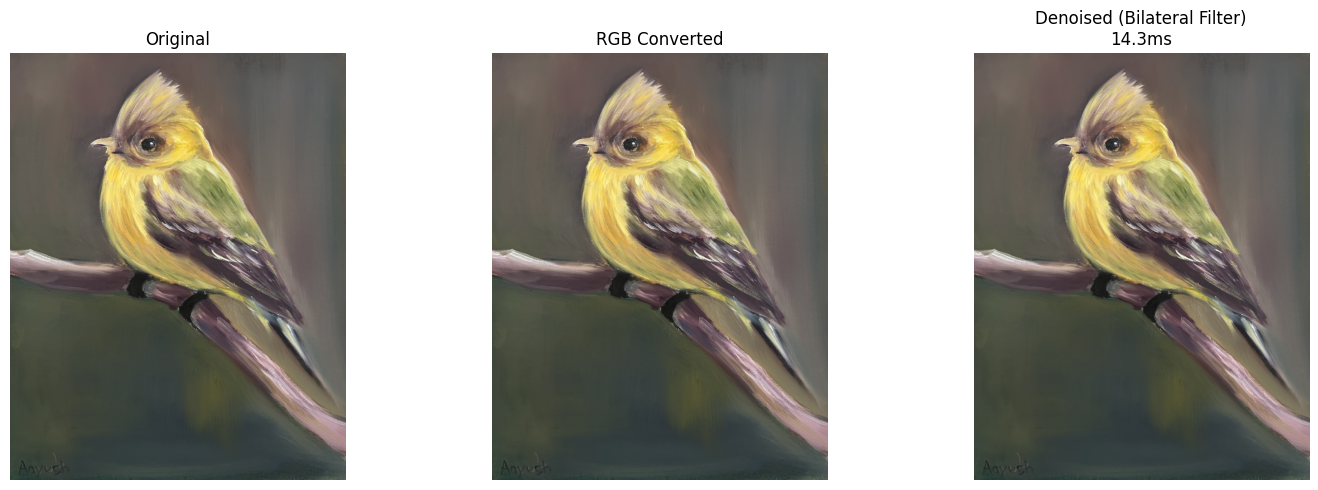

In [27]:
# @title RGB Preprocessing for PiDiNet
"""
RGB Preprocessing Method for Edge Detection
Using only RGB preprocessing approach for PiDiNet
"""

import cv2
import numpy as np
import torch
import time

class RGBPreprocessor:
    """RGB-only preprocessing for edge detection"""

    def __init__(self):
        pass

    def process(self, img_bgr):
        """Proper RGB preprocessing for models trained on RGB"""
        start_time = time.time()

        # Convert BGR to RGB
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Light denoising while preserving edges
        img_denoised = cv2.bilateralFilter(img_rgb, d=5, sigmaColor=10, sigmaSpace=10)

        # Convert to tensor
        tensor = torch.from_numpy(img_denoised).float() / 255.0
        tensor = tensor.permute(2, 0, 1)

        # Use proper normalization for edge detection
        # These values are more appropriate for edge detection than ImageNet stats
        mean = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
        std = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
        tensor = (tensor - mean) / std

        prep_time = time.time() - start_time

        return tensor, prep_time, {
            'rgb': img_rgb,
            'denoised': img_denoised,
            'channels': img_denoised
        }

# Initialize RGB preprocessor
preprocessor = RGBPreprocessor()

# Process sample image
if 'sample_img' in globals():
    tensor, time_taken, debug_info = preprocessor.process(sample_img)
    print(f"RGB preprocessing: {time_taken*1000:.1f}ms")

    # Visualize preprocessing output
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Original
    axes[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original')
    axes[0].axis('off')

    # RGB converted
    axes[1].imshow(debug_info['rgb'])
    axes[1].set_title('RGB Converted')
    axes[1].axis('off')

    # Denoised
    axes[2].imshow(debug_info['denoised'])
    axes[2].set_title(f'Denoised (Bilateral Filter)\n{time_taken*1000:.1f}ms')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Please load sample_img first")

RGB preprocessing: 13.6ms
PiDiNet inference: 119.4ms
Total time: 133.0ms


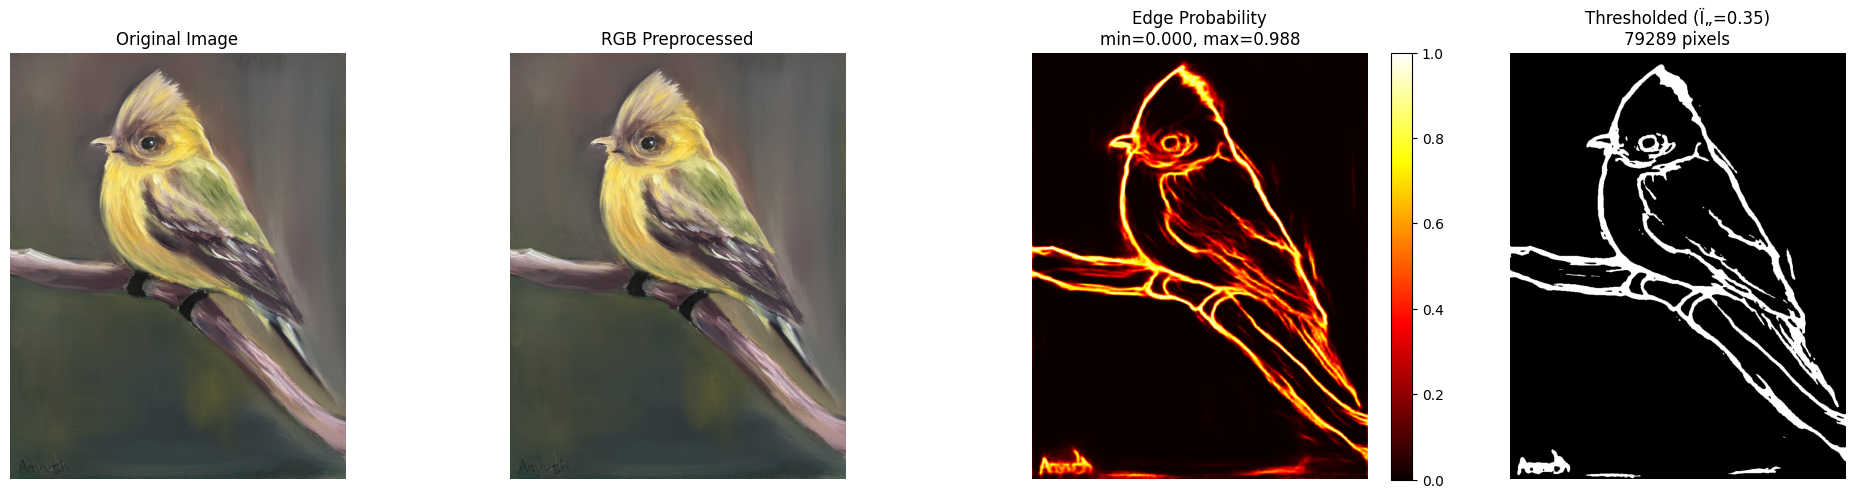

In [28]:
# @title PiDiNet Edge Detection with RGB Preprocessing
"""
Run PiDiNet inference using RGB preprocessing only
"""

def run_pidinet_inference(tensor, model, device):
    """Run PiDiNet inference and return edge probability map"""
    # Move tensor to device
    tensor = tensor.to(device).unsqueeze(0)

    # Run inference
    with torch.no_grad():
        output = model(tensor)
        if isinstance(output, (list, tuple)):
            output = output[-1]

    # Get edge probability map
    edges_prob = output.squeeze().cpu().numpy()

    # Convert to probability if needed (sigmoid)
    if edges_prob.min() < 0:
        edges_prob = 1 / (1 + np.exp(-edges_prob))

    return edges_prob

# Run inference with RGB preprocessing
if 'sample_img' in globals() and 'model' in globals():
    # Use RGB preprocessing
    tensor, prep_time, debug_info = preprocessor.process(sample_img)

    # Run inference
    start_time = time.time()
    edges_prob = run_pidinet_inference(tensor, model, device)
    inference_time = time.time() - start_time

    print(f"RGB preprocessing: {prep_time*1000:.1f}ms")
    print(f"PiDiNet inference: {inference_time*1000:.1f}ms")
    print(f"Total time: {(prep_time + inference_time)*1000:.1f}ms")

    # Visualize results
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # Original
    axes[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    # Preprocessed
    axes[1].imshow(debug_info['denoised'])
    axes[1].set_title('RGB Preprocessed')
    axes[1].axis('off')

    # Edge probability map
    im = axes[2].imshow(edges_prob, cmap='hot', vmin=0, vmax=1)
    axes[2].set_title(f'Edge Probability\nmin={edges_prob.min():.3f}, max={edges_prob.max():.3f}')
    axes[2].axis('off')
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    # Thresholded (example with 0.35)
    threshold = 0.35
    binary = (edges_prob > threshold).astype(np.uint8)
    axes[3].imshow(binary * 255, cmap='gray')
    axes[3].set_title(f'Thresholded (Ï„={threshold})\n{np.sum(binary)} pixels')
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Please ensure sample_img and model are loaded")

In [29]:
# @title 🎨 Depth-Aware Drawing Order Analysis (Uses Previous SAM 2.1 Results)
"""
Run this cell AFTER running segment_unrestricted() to analyze depth and drawing order
Uses the 'masks' variable from the previous cell output
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import time
from collections import defaultdict
from dataclasses import dataclass
from typing import List, Dict, Tuple

# Check if masks exist from previous cell
if 'masks' not in globals():
    print("❌ Error: No masks found! Please run segment_unrestricted() first.")
else:
    print(f"✅ Using {len(masks)} masks from previous SAM 2.1 detection")

# Install DepthAnything V2 if needed
import os
import sys

if not os.path.exists('Depth-Anything-V2'):
    print("📥 Installing DepthAnything V2...")
    !git clone https://github.com/DepthAnything/Depth-Anything-V2.git
    sys.path.append('./Depth-Anything-V2')
    
    # Install requirements
    !pip install -q transformers

# Import depth model
from Depth_Anything_V2.depth_anything_v2.dpt import DepthAnythingV2

# Download model weights if needed
model_configs = {
    'vits': {'encoder': 'vits', 'features': 64, 'out_channels': [48, 96, 192, 384]},
    'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]},
    'vitl': {'encoder': 'vitl', 'features': 256, 'out_channels': [256, 512, 1024, 1024]}
}

# Use vitb for good balance
encoder = 'vitb'
checkpoint_path = f'depth_anything_v2_{encoder}.pth'

if not os.path.exists(checkpoint_path):
    print(f"📥 Downloading DepthAnything V2 weights ({encoder})...")
    !wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Base/resolve/main/depth_anything_v2_vitb.pth

print("🔧 Loading DepthAnything V2 model...")
depth_model = DepthAnythingV2(**model_configs[encoder])
depth_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
depth_model = depth_model.to(device).eval()
print("✅ DepthAnything V2 ready")

❌ Error: No masks found! Please run segment_unrestricted() first.
🔧 Loading DepthAnything V2 model...


/tmp/ipykernel_60346/508104971.py:54: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  depth_model.load_state_dict(torch.load(checkpoint_path, map_location=device))


✅ DepthAnything V2 ready


## Tools

In [30]:
# @title SAM 2.1-Enhanced Segmentation with Value Block-in
"""
Advanced segmentation using SAM 2.1 that creates value-based regions for edge detection
"""

import cv2
import numpy as np
from typing import List, Dict, Tuple
import matplotlib.pyplot as plt
import torch

class SAM21ValueSegmenter:
    """Segment image using SAM 2.1 and create value-based blocks for enhanced edge detection"""

    def __init__(self, mask_generator):
        self.mask_generator = mask_generator

    def segment_and_analyze(self, img_bgr):
        """Segment image and analyze values for each region"""
        # Convert to RGB for SAM
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Generate masks with SAM 2.1
        print("Generating masks with SAM 2.1...")
        with torch.no_grad():
            masks = self.mask_generator.generate(img_rgb)

        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)

        # Analyze each mask
        analyzed_masks = []
        for i, mask_data in enumerate(masks):
            mask = mask_data['segmentation']

            # Extract region
            region_pixels = img_rgb[mask]

            if len(region_pixels) > 0:
                # Calculate statistics
                mean_color = region_pixels.mean(axis=0)
                std_color = region_pixels.std(axis=0)

                # Convert to grayscale for value analysis
                gray_pixels = np.dot(region_pixels[...,:3], [0.2989, 0.5870, 0.1140])
                mean_value = gray_pixels.mean()
                std_value = gray_pixels.std()

                # Classify by value
                if mean_value < 85:
                    value_class = "shadow"
                elif mean_value < 170:
                    value_class = "midtone"
                else:
                    value_class = "highlight"

                # SAM 2.1 specific metrics
                stability_score = mask_data.get('stability_score', 0)
                predicted_iou = mask_data.get('predicted_iou', 0)

                analyzed_masks.append({
                    'mask': mask,
                    'area': mask_data['area'],
                    'bbox': mask_data['bbox'],
                    'mean_color': mean_color,
                    'std_color': std_color,
                    'mean_value': mean_value,
                    'std_value': std_value,
                    'value_class': value_class,
                    'stability_score': stability_score,
                    'predicted_iou': predicted_iou,
                    'point_coords': mask_data.get('point_coords', [])
                })

        print(f"âœ” Analyzed {len(analyzed_masks)} regions with SAM 2.1")
        return analyzed_masks

    def create_value_blockin(self, img_bgr, masks, simplification='medium'):
        """Create value block-in version of image"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240  # Light background

        # Simplification levels
        simplify_params = {
            'minimal': {'num_masks': 5, 'blur': 0, 'iou_threshold': 0.9},
            'medium': {'num_masks': 15, 'blur': 3, 'iou_threshold': 0.85},
            'detailed': {'num_masks': 30, 'blur': 1, 'iou_threshold': 0.8}
        }

        params = simplify_params.get(simplification, simplify_params['medium'])

        # Filter by IoU threshold if available
        filtered_masks = [m for m in masks if m.get('predicted_iou', 1.0) >= params['iou_threshold']]

        # Process top N masks by area
        for mask_data in filtered_masks[:params['num_masks']]:
            mask = mask_data['mask']
            mean_color = mask_data['mean_color'].astype(np.uint8)

            # Apply to block-in
            blockin[mask] = cv2.cvtColor(
                np.array([[mean_color]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]

        # Optional smoothing
        if params['blur'] > 0:
            blockin = cv2.bilateralFilter(blockin, params['blur'], 75, 75)

        return blockin

    def create_hierarchical_blockin(self, img_bgr, masks):
        """Create hierarchical block-in using SAM 2.1's multi-scale information"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
        hierarchy_map = np.zeros((h, w), dtype=np.float32)

        # Group masks by stability score (SAM 2.1 feature)
        stable_masks = [m for m in masks if m['stability_score'] > 0.95]
        medium_masks = [m for m in masks if 0.85 <= m['stability_score'] <= 0.95]
        unstable_masks = [m for m in masks if m['stability_score'] < 0.85]

        # Apply in hierarchical order
        for level, mask_group in enumerate([unstable_masks, medium_masks, stable_masks]):
            for mask_data in mask_group[:10]:  # Limit per level
                mask = mask_data['mask']
                mean_color = mask_data['mean_color']

                # Adjust intensity based on stability
                stability_factor = 0.6 + 0.4 * mask_data['stability_score']
                adjusted_color = mean_color * stability_factor

                blockin[mask] = cv2.cvtColor(
                    np.array([[adjusted_color.astype(np.uint8)]], dtype=np.uint8),
                    cv2.COLOR_RGB2BGR
                )[0, 0]

                hierarchy_map[mask] = level + 1

        return blockin, hierarchy_map

    def create_depth_weighted_blockin(self, img_bgr, masks):
        """Create block-in with pseudo-depth weighting using SAM 2.1 features"""
        h, w = img_bgr.shape[:2]
        blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
        depth_map = np.ones((h, w), dtype=np.float32)

        for i, mask_data in enumerate(masks):
            mask = mask_data['mask']

            # Enhanced depth heuristic using SAM 2.1 metrics
            y, x, h_box, w_box = mask_data['bbox']
            area_ratio = mask_data['area'] / (h * w)
            vertical_position = (y + h_box/2) / h

            # Use stability and IoU as additional depth cues
            stability = mask_data.get('stability_score', 0.5)
            iou = mask_data.get('predicted_iou', 0.5)

            # Depth score (0 = far, 1 = near)
            # Stable, high-IoU regions are likely foreground
            depth_score = (
                (1 - vertical_position) * 0.4 +
                area_ratio * 0.3 +
                stability * 0.15 +
                iou * 0.15
            )
            depth_map[mask] = depth_score

            # Adjust color based on depth
            mean_color = mask_data['mean_color']
            depth_adjusted = mean_color * (0.5 + 0.5 * depth_score)

            blockin[mask] = cv2.cvtColor(
                np.array([[depth_adjusted.astype(np.uint8)]], dtype=np.uint8),
                cv2.COLOR_RGB2BGR
            )[0, 0]

        return blockin, depth_map

# Initialize SAM 2.1 segmenter
segmenter = SAM21ValueSegmenter(mask_generator)

In [31]:
# @title Initialize SAM 2.1 Model with Optimized Object Detection Parameters
"""
Initialize SAM 2.1 with parameters optimized for complete object detection
Similar to the Meta demo website
"""

# OPTIMIZED PARAMETERS for complete objects (not fragments)
mask_generator = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,  # Balanced - not too dense to avoid over-segmentation
    points_per_batch=64,
    pred_iou_thresh=0.88,  # Higher threshold for better quality masks
    stability_score_thresh=0.95,  # High stability for complete objects only
    stability_score_offset=1.0,
    crop_n_layers=0,  # Disable crop layers to avoid fragments
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Reasonable minimum to avoid tiny fragments
    output_mode="binary_mask",
)

# STANDARD MODE - Good balance of speed and detection
mask_generator_standard = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=48,  # Good density without being too slow
    points_per_batch=64,
    pred_iou_thresh=0.86,  # Reasonable threshold
    stability_score_thresh=0.90,  # Lower than before to find more objects
    stability_score_offset=1.0,
    crop_n_layers=1,  # Single layer for some multi-scale
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Filter tiny fragments
    output_mode="binary_mask",
)

# QUICK MODE - Faster but still finds main objects
mask_generator_quick = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=32,  # Less dense for speed
    points_per_batch=64,
    pred_iou_thresh=0.88,
    stability_score_thresh=0.92,  # Higher for quality
    stability_score_offset=1.0,
    crop_n_layers=0,  # No crops for speed
    min_mask_region_area=150,  # Larger minimum
    output_mode="binary_mask",
)


# Alternative settings for more objects (but still complete ones)
mask_generator_balanced = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=48,  # Slightly denser grid
    points_per_batch=64,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,  # Still high for quality
    stability_score_offset=1.0,
    crop_n_layers=1,  # Single crop layer for multi-scale
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,
    output_mode="binary_mask",
)

# COMPREHENSIVE MODE - Find more objects (slower)
mask_generator_comprehensive = SAM2AutomaticMaskGenerator(
    model=sam2,
    points_per_side=64,  # Denser sampling
    points_per_batch=128,
    pred_iou_thresh=0.84,  # Lower threshold for more objects
    stability_score_thresh=0.88,  # Even lower stability requirement
    stability_score_offset=1.0,
    crop_n_layers=1,  # Keep single layer to avoid too many fragments
    crop_n_points_downscale_factor=2,
    crop_overlap_ratio=0.2,  # Some overlap for better coverage
    min_mask_region_area=80,  # Slightly smaller minimum
    output_mode="binary_mask",
)

print("âœ… SAM 2.1 model loaded with optimized object detection parameters")

âœ… SAM 2.1 model loaded with optimized object detection parameters


In [32]:
# @title Unrestricted SAM 2.1 Segmenter - Maximum Object Detection
"""
Removes restrictions to detect ALL possible objects
"""

class SAM21UnrestrictedSegmenter:
    """Segmenter with minimal restrictions for maximum detection"""
    
    def __init__(self, model):
        self.model = model
        self.predictor = SAM2ImagePredictor(self.model)
        
        # Generator for large objects - less restrictive
        self.generator_large = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=48,  # Increased density
            points_per_batch=64,
            pred_iou_thresh=0.88,  # Slightly lower threshold
            stability_score_thresh=0.92,  # Lower for more objects
            stability_score_offset=1.0,
            crop_n_layers=0,
            min_mask_region_area=300,  # Reduced from 500
            output_mode="binary_mask",
        )
        
        # Generator for all objects - very permissive
        self.generator_detailed = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=64,  # Much denser sampling
            points_per_batch=64,
            pred_iou_thresh=0.80,  # Lower threshold for more objects
            stability_score_thresh=0.85,  # More permissive
            stability_score_offset=1.0,
            crop_n_layers=1,
            crop_n_points_downscale_factor=2,
            min_mask_region_area=50,  # Much smaller minimum
            output_mode="binary_mask",
        )
        
        # Extra dense generator for complex areas
        self.generator_dense = SAM2AutomaticMaskGenerator(
            model=self.model,
            points_per_side=96,  # Very dense
            points_per_batch=128,
            pred_iou_thresh=0.75,  # Even lower
            stability_score_thresh=0.80,
            stability_score_offset=1.0,
            crop_n_layers=2,  # Multi-scale
            crop_n_points_downscale_factor=2,
            min_mask_region_area=25,  # Very small objects
            output_mode="binary_mask",
        )
    
    def segment_unrestricted(self, img_bgr, 
                            use_dense=True,
                            group_small=True,
                            min_group_size=2,
                            keep_all_small=True,
                            max_edge_points=100,
                            visualize=True,
                            # NEW: Anti-oversegmentation parameters
                            protect_large_objects=True,
                            min_protected_size=0.15,
                            merge_homogeneous=True,
                            homogeneous_threshold=15,
                            filter_texture_fragments=True):
        """
        Unrestricted segmentation with optional oversegmentation protection
        """
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        self.h, self.w = h, w  # Store for helper methods
        
        print("🔍 Unrestricted Object Detection")
        print("="*50)
        
        all_masks = []
        
        # Step 1: Large objects
        print("Step 1: Detecting large objects...")
        with torch.no_grad():
            large_masks = self.generator_large.generate(img_rgb)
        for mask in large_masks:
            mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
            mask['object_type'] = 'large'
            mask['source'] = 'large_generator'
        all_masks.extend(large_masks)
        print(f"   Found {len(large_masks)} large objects")
        
        # Step 2: Detailed detection
        print("Step 2: Detailed object detection...")
        with torch.no_grad():
            detailed_masks = self.generator_detailed.generate(img_rgb)
        for mask in detailed_masks:
            mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
            mask['source'] = 'detailed_generator'
        all_masks.extend(detailed_masks)
        print(f"   Found {len(detailed_masks)} additional objects")
        
        # Step 3: Dense detection (optional)
        if use_dense:
            print("Step 3: Dense detection for maximum coverage...")
            with torch.no_grad():
                dense_masks = self.generator_dense.generate(img_rgb)
            for mask in dense_masks:
                mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
                mask['source'] = 'dense_generator'
            all_masks.extend(dense_masks)
            print(f"   Found {len(dense_masks)} more objects with dense sampling")
        
        # Step 4: Comprehensive edge detection
        print("Step 4: Comprehensive edge detection...")
        edge_masks = self._detect_all_edges(img_rgb, max_points=max_edge_points)
        all_masks.extend(edge_masks)
        print(f"   Found {len(edge_masks)} edge objects")
        
        # Step 5: Deduplicate
        print("Step 5: Smart deduplication...")
        unique_masks = self._smart_deduplicate(all_masks)
        print(f"   Reduced from {len(all_masks)} to {len(unique_masks)} unique objects")
        
        # NEW Step 5.5: Anti-oversegmentation processing
        if protect_large_objects or merge_homogeneous or filter_texture_fragments:
            print("\n🛡️ Applying Anti-Oversegmentation Filters...")
            
            if protect_large_objects:
                print(f"  - Protecting objects >{min_protected_size*100:.0f}% of image...")
                unique_masks = self._protect_large_objects(unique_masks, min_protected_size)
                print(f"    → {len(unique_masks)} objects after protection")
            
            if merge_homogeneous:
                print(f"  - Merging homogeneous regions (threshold={homogeneous_threshold})...")
                unique_masks = self._merge_homogeneous_regions(
                    unique_masks, img_rgb, homogeneous_threshold
                )
                print(f"    → {len(unique_masks)} objects after merging")
            
            if filter_texture_fragments:
                print(f"  - Filtering texture fragments...")
                unique_masks = self._filter_texture_fragments(unique_masks, img_rgb)
                print(f"    → {len(unique_masks)} objects after filtering")
        
        # Step 6: Optional grouping
        if group_small:
            print("\nStep 6: Grouping small related objects...")
            final_masks = self._group_related_objects(
                unique_masks, 
                img_rgb,
                min_group_size=min_group_size,
                keep_ungrouped=keep_all_small
            )
            print(f"   Final count: {len(final_masks)} objects/groups")
        else:
            final_masks = unique_masks
        
        # Sort by area
        final_masks = sorted(final_masks, key=lambda x: x.get('area', 0), reverse=True)
        
        print(f"\n✅ Complete: {len(final_masks)} total objects detected")
        
        if visualize:
            self._visualize_unrestricted(img_rgb, final_masks)
        
        return final_masks
    
    def _merge_homogeneous_regions(self, masks, img_rgb, color_threshold=15):
        """Merge masks in homogeneous areas (like uniform walls)"""
        from scipy import ndimage
        
        merged = []
        processed = set()
        
        for i, mask1 in enumerate(masks):
            if i in processed:
                continue
            
            # Ensure mask is boolean
            seg1 = np.asarray(mask1['segmentation'], dtype=bool)
            
            # Check if this region is homogeneous
            pixels = img_rgb[seg1]
            if len(pixels) == 0:
                continue
            
            color_std = pixels.std(axis=0).mean()
            
            # If region is very uniform in color
            if color_std < color_threshold:
                # Find adjacent similar regions to merge
                current_group = [i]
                mean_color1 = pixels.mean(axis=0)
                
                for j, mask2 in enumerate(masks):
                    if j in processed or j == i:
                        continue
                    
                    # Ensure mask is boolean
                    seg2 = np.asarray(mask2['segmentation'], dtype=bool)
                    
                    # Check adjacency
                    dilated1 = ndimage.binary_dilation(seg1, iterations=3)
                    if not np.any(dilated1 & seg2):
                        continue
                    
                    # Check color similarity
                    pixels2 = img_rgb[seg2]
                    if len(pixels2) == 0:
                        continue
                    
                    mean_color2 = pixels2.mean(axis=0)
                    color_diff = np.abs(mean_color1 - mean_color2).mean()
                    
                    if color_diff < color_threshold:
                        current_group.append(j)
                
                # Merge group
                if len(current_group) > 1:
                    merged_mask = seg1.copy()
                    merged_area = seg1.sum()
                    
                    for j in current_group[1:]:
                        seg_j = np.asarray(masks[j]['segmentation'], dtype=bool)
                        merged_mask = np.logical_or(merged_mask, seg_j)
                        merged_area = merged_mask.sum()
                        processed.add(j)
                    
                    merged.append({
                        'segmentation': merged_mask,
                        'area': merged_area,
                        'source': 'merged_homogeneous',
                        'stability_score': 0.95,
                        'predicted_iou': 0.95,
                        'object_type': 'merged'
                    })
                    processed.add(i)
                else:
                    merged.append(mask1)
                    processed.add(i)
            else:
                merged.append(mask1)
                processed.add(i)
        
        return merged
    
    def _filter_texture_fragments(self, masks, img_rgb):
        """Remove small masks that are just texture variations"""
        from scipy import ndimage
        
        filtered = []
        
        for mask_data in masks:
            # Ensure mask is boolean
            mask = np.asarray(mask_data['segmentation'], dtype=bool)
            pixels = img_rgb[mask]
            
            if len(pixels) < 10:
                continue  # Too small
            
            # Get local neighborhood
            dilated = ndimage.binary_dilation(mask, iterations=10)
            neighborhood_pixels = img_rgb[dilated & ~mask]
            
            if len(neighborhood_pixels) < 10:
                filtered.append(mask_data)
                continue
            
            # Compare colors
            mask_color = pixels.mean(axis=0)
            neighbor_color = neighborhood_pixels.mean(axis=0)
            
            color_diff = np.abs(mask_color - neighbor_color).mean()
            
            # If very similar to surroundings, probably a texture fragment
            if color_diff > 10:  # Different enough to keep
                filtered.append(mask_data)
            # else: skip (it's a texture fragment)
        
        return filtered
    
    def _protect_large_objects(self, masks, min_size_ratio=0.15):
        """Prevent oversegmentation of large objects like walls"""
        if not masks:
            return masks
        
        # Identify very large objects (likely background/wall)
        total_area = self.h * self.w
        large_masks = []
        small_masks = []
        
        for mask in masks:
            # Ensure area is calculated
            if 'area' not in mask or mask['area'] is None:
                seg = np.asarray(mask['segmentation'], dtype=bool)
                mask['area'] = seg.sum()
            
            area_ratio = mask['area'] / total_area
            if area_ratio > min_size_ratio:
                large_masks.append(mask)
            else:
                small_masks.append(mask)
        
        # For large objects, remove any small fragments that overlap significantly
        protected_large = []
        for large_mask in large_masks:
            # Ensure segmentation is boolean
            seg_large = np.asarray(large_mask['segmentation'], dtype=bool)
            
            # Check if this is actually a fragment of an even larger object
            is_fragment = False
            for other_large in large_masks:
                if other_large['area'] > large_mask['area'] * 1.5:
                    seg_other = np.asarray(other_large['segmentation'], dtype=bool)
                    overlap = np.logical_and(seg_large, seg_other).sum()
                    if overlap / large_mask['area'] > 0.8:
                        is_fragment = True
                        break
            
            if not is_fragment:
                protected_large.append(large_mask)
        
        # Remove small masks that are mostly inside large objects
        filtered_small = []
        for small_mask in small_masks:
            seg_small = np.asarray(small_mask['segmentation'], dtype=bool)
            
            is_interior_fragment = False
            for large_mask in protected_large:
                seg_large = np.asarray(large_mask['segmentation'], dtype=bool)
                overlap = np.logical_and(seg_small, seg_large).sum()
                
                # If small mask is >70% inside a large object, it's a fragment
                if small_mask['area'] > 0 and overlap / small_mask['area'] > 0.7:
                    is_interior_fragment = True
                    break
            
            if not is_interior_fragment:
                filtered_small.append(small_mask)
        
        return protected_large + filtered_small
    
    def _detect_all_edges(self, img_rgb, max_points=100):
        """Comprehensive edge detection"""
        h, w = img_rgb.shape[:2]
        edge_masks = []
        
        # Sample more points along all edges
        edge_points = []
        
        # Top and bottom edges
        for x in np.linspace(10, w-10, max_points//4):
            edge_points.append([x, 10])  # Top
            edge_points.append([x, h-10])  # Bottom
        
        # Left and right edges
        for y in np.linspace(10, h-10, max_points//4):
            edge_points.append([10, y])  # Left
            edge_points.append([w-10, y])  # Right
        
        # Use predictor for all edge points
        with torch.no_grad():
            self.predictor.set_image(img_rgb)
            
            for point in edge_points:
                try:
                    masks, scores, _ = self.predictor.predict(
                        point_coords=np.array([point], dtype=np.float32),
                        point_labels=np.array([1], dtype=np.int32),
                        multimask_output=True
                    )
                    
                    # Keep all good masks
                    for mask, score in zip(masks, scores):
                        if score > 0.8:  # Lower threshold
                            edge_masks.append({
                                'segmentation': mask,
                                'area': mask.sum(),
                                'object_type': 'edge',
                                'source': 'edge_detector',
                                'stability_score': float(score),
                                'predicted_iou': float(score)
                            })
                except:
                    continue
        
        return edge_masks
    
    def _smart_deduplicate(self, masks, iou_threshold=0.9):
        """Deduplicate but keep objects with significantly different sizes"""
        if not masks:
            return []
        
        # Sort by area * stability
        masks = sorted(masks, 
                      key=lambda x: x.get('area', 0) * x.get('stability_score', 1.0), 
                      reverse=True)
        
        kept = []
        for mask in masks:
            mask['area'] = mask['segmentation'].sum()
            should_keep = True
            
            for kept_mask in kept:
                # Calculate IoU
                intersection = np.logical_and(mask['segmentation'], 
                                            kept_mask['segmentation']).sum()
                union = np.logical_or(mask['segmentation'], 
                                     kept_mask['segmentation']).sum()
                iou = intersection / union if union > 0 else 0
                
                # Only remove if very similar (high IoU) AND similar size
                if iou > iou_threshold:
                    size_ratio = mask['area'] / kept_mask['area'] if kept_mask['area'] > 0 else 0
                    if 0.8 < size_ratio < 1.2:  # Similar size
                        should_keep = False
                        break
            
            if should_keep:
                kept.append(mask)
        
        return kept
    
    def _group_related_objects(self, masks, img_rgb, 
                          min_group_size=2, 
                          proximity_threshold=60,
                          keep_ungrouped=True):
        """Group related objects with less restrictive parameters"""
        # Separate by size
        large_masks = [m for m in masks if m.get('area', 0) > 500]
        small_masks = [m for m in masks if m.get('area', 0) <= 500]
        
        if not small_masks:
            return large_masks
        
        # Ensure all masks are boolean type
        for mask in small_masks:
            mask['segmentation'] = np.asarray(mask['segmentation'], dtype=bool)
        
        # Calculate relationships between small objects
        grouped = []
        processed = set()
        
        # Calculate centroids
        centroids = []
        for mask in small_masks:
            y_coords, x_coords = np.where(mask['segmentation'])
            if len(x_coords) > 0:
                centroids.append([np.mean(x_coords), np.mean(y_coords)])
            else:
                centroids.append([0, 0])
        centroids = np.array(centroids)
        
        # Group nearby objects
        for i, mask in enumerate(small_masks):
            if i in processed:
                continue
            
            # Find nearby objects
            group = [i]
            if len(centroids) > 1:
                distances = np.linalg.norm(centroids - centroids[i], axis=1)
                nearby = np.where((distances < proximity_threshold) & (distances > 0))[0]
                
                if len(nearby) >= min_group_size - 1:
                    group.extend(nearby.tolist())
                    
                    # Create grouped mask - ensure boolean type
                    group_mask = np.asarray(mask['segmentation'], dtype=bool).copy()
                    for j in nearby:
                        # Ensure boolean type for OR operation
                        other_mask = np.asarray(small_masks[j]['segmentation'], dtype=bool)
                        group_mask = np.logical_or(group_mask, other_mask)
                        processed.add(j)
                    
                    grouped.append({
                        'segmentation': group_mask,
                        'area': group_mask.sum(),
                        'object_type': 'grouped',
                        'num_components': len(group),
                        'stability_score': 0.9,
                        'predicted_iou': 0.9
                    })
                    processed.add(i)
                elif keep_ungrouped:
                    # Keep ungrouped object regardless of size
                    mask['object_type'] = 'small_single'
                    grouped.append(mask)
                    processed.add(i)
            elif keep_ungrouped:
                mask['object_type'] = 'small_single'
                grouped.append(mask)
                processed.add(i)
        
        return large_masks + grouped
    
    def _visualize_unrestricted(self, img_rgb, masks):
        """Visualize unrestricted detection results"""
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        
        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        
        # All objects
        all_viz = np.zeros_like(img_rgb, dtype=np.uint8)
        for i, mask in enumerate(masks):
            # Ensure mask is boolean
            mask_bool = np.asarray(mask['segmentation'], dtype=bool)
            
            # Get color and ensure it's the right shape
            color = plt.cm.tab20(i % 20)[:3]
            color_rgb = (np.array(color) * 255).astype(np.uint8)
            
            # Apply color to masked regions
            all_viz[mask_bool, 0] = color_rgb[0]
            all_viz[mask_bool, 1] = color_rgb[1]
            all_viz[mask_bool, 2] = color_rgb[2]
        
        axes[1].imshow(all_viz)
        axes[1].set_title(f'All Objects ({len(masks)} total)')
        axes[1].axis('off')
        
        # Overlay
        overlay = img_rgb.copy().astype(np.float32)
        for i, mask in enumerate(masks[:30]):  # Limit for visibility
            # Ensure mask is boolean
            mask_bool = np.asarray(mask['segmentation'], dtype=bool)
            
            # Get color
            color = plt.cm.tab20(i % 20)[:3]
            color_rgb = np.array(color) * 255
            
            # Apply with transparency
            overlay[mask_bool, 0] = overlay[mask_bool, 0] * 0.5 + color_rgb[0] * 0.5
            overlay[mask_bool, 1] = overlay[mask_bool, 1] * 0.5 + color_rgb[1] * 0.5
            overlay[mask_bool, 2] = overlay[mask_bool, 2] * 0.5 + color_rgb[2] * 0.5
        
        axes[2].imshow(overlay.astype(np.uint8))
        axes[2].set_title('Overlay (top 30 objects)')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Statistics
        print("\n📊 Detection Statistics:")
        print(f"   Total objects: {len(masks)}")
        
        # Calculate areas if not present
        for mask in masks:
            if 'area' not in mask or mask['area'] is None:
                mask['area'] = np.asarray(mask['segmentation'], dtype=bool).sum()
        
        print(f"   Large objects (>500px): {len([m for m in masks if m.get('area', 0) > 500])}")
        print(f"   Small objects (≤500px): {len([m for m in masks if m.get('area', 0) <= 500])}")
        print(f"   Grouped objects: {len([m for m in masks if m.get('object_type') == 'grouped'])}")
        
        # Source breakdown
        sources = {}
        for mask in masks:
            source = mask.get('source', 'unknown')
            sources[source] = sources.get(source, 0) + 1
        print("\n   Detection sources:")
        for source, count in sources.items():
            print(f"      {source}: {count} objects")

# Initialize unrestricted segmenter
if 'sam2' in globals():
    unrestricted_segmenter = SAM21UnrestrictedSegmenter(sam2)
    print("✅ Unrestricted segmenter initialized (no limits on detection)")

✅ Unrestricted segmenter initialized (no limits on detection)


âœ… Fast segmenter initialized with both fast and balanced modes

Testing fast object detection...
ðŸ” Detecting objects (balanced mode)...
   Initial detection: 22 masks in 13.7s
   After merging: 20 complete objects
âœ” Final: 20 objects detected in 13.8s


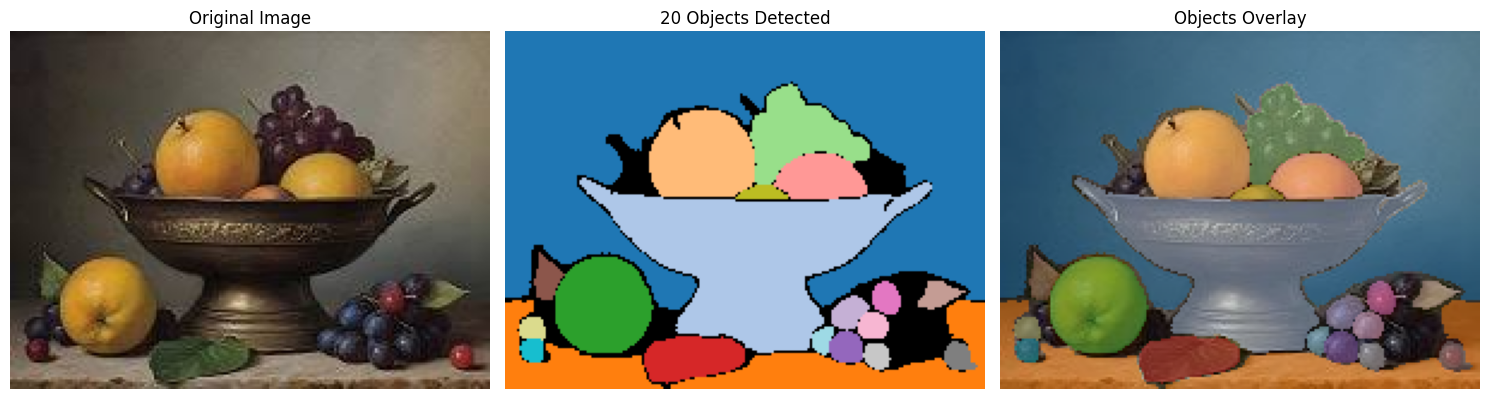


ðŸ“Š Object Statistics:
   Total objects: 20
   Large objects (>5% of image): 3
   High stability (>0.95): 7
   Size range: 77 - 13,104 pixels
   Mean size: 1,342 pixels

ðŸŽ¯ Top 5 Largest Objects:
   1. Area: 13,104 pixels | Stability: 0.946 | IoU: 0.988
   2. Area: 4,799 pixels | Stability: 0.920 | IoU: 0.956
   3. Area: 2,596 pixels | Stability: 0.925 | IoU: 0.953
   4. Area: 1,339 pixels | Stability: 0.947 | IoU: 0.989
   5. Area: 1,308 pixels | Stability: 0.974 | IoU: 0.983


In [33]:
# @title Fast SAM 2.1 Segmentation with Smart Object Merging
"""
Efficient segmentation that merges fragments into complete objects
Much faster and produces cleaner results
"""

import cv2
import numpy as np
from typing import List, Dict, Optional
import matplotlib.pyplot as plt
import torch
import time

class SAM21FastSegmenter:
    """Fast segmenter that produces complete objects, not fragments"""
    
    def __init__(self, mask_generator, balanced_generator=None):
        self.mask_generator = mask_generator
        self.balanced_generator = balanced_generator
    
    def segment_and_merge(self, img_bgr, mode='fast', merge_fragments=True, visualize=False):
        """
        Segment image and merge fragments into complete objects
        
        Args:
            img_bgr: Input image in BGR format
            mode: 'fast' or 'balanced'
            merge_fragments: Whether to merge overlapping fragments
            visualize: Show results
        """
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Select generator
        generator = self.balanced_generator if mode == 'balanced' and self.balanced_generator else self.mask_generator
        
        print(f"ðŸ” Detecting objects ({mode} mode)...")
        start_time = time.time()
        
        # Generate initial masks
        with torch.no_grad():
            masks = generator.generate(img_rgb)
        
        initial_count = len(masks)
        print(f"   Initial detection: {initial_count} masks in {time.time()-start_time:.1f}s")
        
        if merge_fragments:
            # Merge overlapping fragments into complete objects
            masks = self._merge_fragments(masks)
            print(f"   After merging: {len(masks)} complete objects")
        
        # Remove redundant masks
        masks = self._remove_redundant_masks(masks)
        
        # Sort by area and stability
        masks = sorted(masks, key=lambda x: (x['area'], x['stability_score']), reverse=True)
        
        print(f"âœ” Final: {len(masks)} objects detected in {time.time()-start_time:.1f}s")
        
        if visualize:
            self._visualize_results(img_rgb, masks)
        
        return masks
    
    def _merge_fragments(self, masks, iou_threshold=0.5):
        """
        Merge overlapping mask fragments into complete objects
        Uses hierarchical merging based on containment and overlap
        """
        if not masks:
            return []
        
        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)
        
        merged = []
        processed = set()
        
        for i, mask1 in enumerate(masks):
            if i in processed:
                continue
            
            # Check if this mask should be merged with any existing merged mask
            should_merge_with_existing = False
            for j, existing in enumerate(merged):
                overlap = self._calculate_overlap(mask1['segmentation'], existing['segmentation'])
                containment = self._calculate_containment(mask1['segmentation'], existing['segmentation'])
                
                # If this mask is largely contained in an existing one, skip it
                if containment > 0.8:
                    processed.add(i)
                    should_merge_with_existing = True
                    break
                
                # If significant overlap, merge into existing
                if overlap > iou_threshold:
                    merged[j] = self._merge_two_masks(existing, mask1)
                    processed.add(i)
                    should_merge_with_existing = True
                    break
            
            if should_merge_with_existing:
                continue
            
            # Start new merged group
            current_merged = mask1.copy()
            processed.add(i)
            
            # Find all fragments that belong to this object
            for j in range(i + 1, len(masks)):
                if j in processed:
                    continue
                
                mask2 = masks[j]
                
                # Check overlap and containment
                overlap = self._calculate_overlap(current_merged['segmentation'], mask2['segmentation'])
                containment = self._calculate_containment(mask2['segmentation'], current_merged['segmentation'])
                
                # Merge if significant overlap or containment
                if overlap > iou_threshold or containment > 0.7:
                    current_merged = self._merge_two_masks(current_merged, mask2)
                    processed.add(j)
            
            merged.append(current_merged)
        
        return merged
    
    def _calculate_overlap(self, mask1, mask2):
        """Calculate IoU (Intersection over Union) between two masks"""
        intersection = (mask1 & mask2).sum()
        union = (mask1 | mask2).sum()
        return intersection / union if union > 0 else 0
    
    def _calculate_containment(self, mask1, mask2):
        """Calculate how much of mask1 is contained in mask2"""
        intersection = (mask1 & mask2).sum()
        mask1_area = mask1.sum()
        return intersection / mask1_area if mask1_area > 0 else 0
    
    def _merge_two_masks(self, mask1_data, mask2_data):
        """Merge two mask dictionaries into one"""
        merged = mask1_data.copy()
        merged['segmentation'] = mask1_data['segmentation'] | mask2_data['segmentation']
        merged['area'] = merged['segmentation'].sum()
        
        # Average the scores weighted by area
        w1 = mask1_data['area'] / (mask1_data['area'] + mask2_data['area'])
        w2 = mask2_data['area'] / (mask1_data['area'] + mask2_data['area'])
        
        merged['stability_score'] = (mask1_data['stability_score'] * w1 + 
                                     mask2_data['stability_score'] * w2)
        merged['predicted_iou'] = (mask1_data['predicted_iou'] * w1 + 
                                   mask2_data['predicted_iou'] * w2)
        
        # Update bbox
        y_indices, x_indices = np.where(merged['segmentation'])
        if len(x_indices) > 0 and len(y_indices) > 0:
            x_min, x_max = x_indices.min(), x_indices.max()
            y_min, y_max = y_indices.min(), y_indices.max()
            merged['bbox'] = [x_min, y_min, x_max - x_min + 1, y_max - y_min + 1]
        
        return merged
    
    def _remove_redundant_masks(self, masks, containment_threshold=0.9):
        """Remove masks that are mostly contained in other masks"""
        if not masks:
            return []
        
        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)
        
        kept = []
        for i, mask1 in enumerate(masks):
            is_redundant = False
            
            # Check if this mask is contained in any kept mask
            for kept_mask in kept:
                containment = self._calculate_containment(
                    mask1['segmentation'], 
                    kept_mask['segmentation']
                )
                if containment > containment_threshold:
                    is_redundant = True
                    break
            
            if not is_redundant:
                kept.append(mask1)
        
        return kept
    
    def _visualize_results(self, img_rgb, masks):
        """Quick visualization of segmentation results"""
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        
        # All masks with different colors
        mask_overlay = np.zeros_like(img_rgb)
        for i, mask_data in enumerate(masks):
            color = plt.cm.tab20(i % 20)[:3]
            mask_overlay[mask_data['segmentation']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[1].imshow(mask_overlay)
        axes[1].set_title(f'{len(masks)} Objects Detected')
        axes[1].axis('off')
        
        # Overlay on original
        alpha = 0.5
        overlay = img_rgb.copy()
        mask_pixels = mask_overlay.sum(axis=2) > 0
        overlay[mask_pixels] = (overlay[mask_pixels] * (1 - alpha) + 
                                mask_overlay[mask_pixels] * alpha).astype(np.uint8)
        
        axes[2].imshow(overlay)
        axes[2].set_title('Objects Overlay')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print("\nðŸ“Š Object Statistics:")
        print(f"   Total objects: {len(masks)}")
        print(f"   Large objects (>5% of image): {len([m for m in masks if m['area'] > 0.05 * img_rgb.shape[0] * img_rgb.shape[1]])}")
        print(f"   High stability (>0.95): {len([m for m in masks if m['stability_score'] > 0.95])}")
        
        # Show size distribution
        areas = [m['area'] for m in masks]
        if areas:
            print(f"   Size range: {min(areas):,} - {max(areas):,} pixels")
            print(f"   Mean size: {np.mean(areas):,.0f} pixels")

# Initialize fast segmenter
if 'mask_generator' in globals():
    if 'mask_generator_balanced' in globals():
        segmenter = SAM21FastSegmenter(mask_generator, mask_generator_balanced)
        print("âœ… Fast segmenter initialized with both fast and balanced modes")
    else:
        segmenter = SAM21FastSegmenter(mask_generator)
        print("âœ… Fast segmenter initialized")
else:
    print("âš ï¸ Please run the SAM 2.1 initialization cell first")

# Test with sample image
if 'sample_img' in globals() and 'segmenter' in globals():
    print("\n" + "="*50)
    print("Testing fast object detection...")
    print("="*50)
    sample_img = cv2.imread("../images/still1.jfif")
    # Run fast segmentation with merging
    masks = segmenter.segment_and_merge(
        sample_img, 
        mode='balanced',  # Use 'balanced' for more objects
        merge_fragments=True,  # Merge fragments into complete objects
        visualize=True
    )
    
    # Quick analysis
    print("\nðŸŽ¯ Top 5 Largest Objects:")
    for i, mask in enumerate(masks[:5], 1):
        print(f"   {i}. Area: {mask['area']:,} pixels | "
              f"Stability: {mask['stability_score']:.3f} | "
              f"IoU: {mask['predicted_iou']:.3f}")

âœ… Smart segmenter initialized with modes: ['quick_gen', 'standard_gen', 'comprehensive_gen']

Testing smart segmentation...
ðŸ” Detecting objects (standard mode)...
   Raw detection: 48 masks in 13.2s
   Applying balanced merging...
âœ” Final: 42 objects


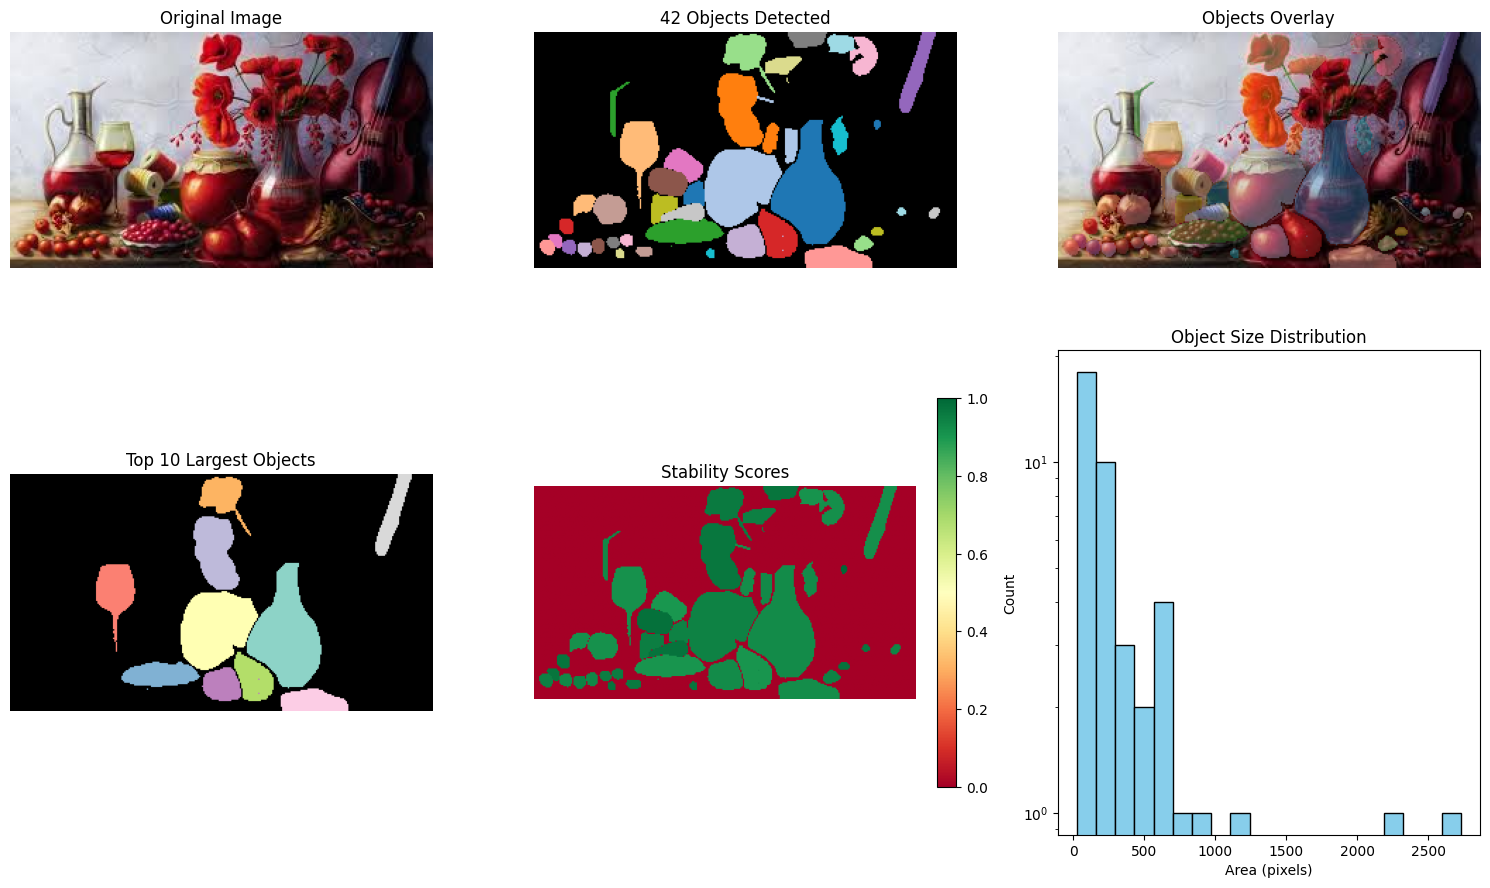


ðŸ“Š Detection Statistics:
   Total objects: 42
   Objects that were merged: 6
   Average merge count: 1.1
   Size range: 24 - 2,729 pixels
   Avg stability: 0.941

ðŸ’¡ Tips:
   â€¢ Use mode='standard' for most images (balanced)
   â€¢ Use mode='comprehensive' if objects are missing
   â€¢ Use mode='quick' for speed with main objects only
   â€¢ Use mode='auto' to let the system decide


In [34]:
# @title Smart SAM 2.1 Segmenter - Adaptive Object Detection
"""
Intelligent segmentation that adapts merging based on detection quality
Finds the right balance between complete objects and fragments
"""

import cv2
import numpy as np
from typing import List, Dict, Optional
import matplotlib.pyplot as plt
import torch
import time

class SAM21SmartSegmenter:
    """Smart segmenter with adaptive merging strategies"""
    
    def __init__(self, quick_gen=None, standard_gen=None, comprehensive_gen=None):
        # Store all available generators
        self.generators = {}
        if quick_gen:
            self.generators['quick'] = quick_gen
        if standard_gen:
            self.generators['standard'] = standard_gen
        if comprehensive_gen:
            self.generators['comprehensive'] = comprehensive_gen
        
        # Default to standard if available
        self.default_generator = standard_gen or comprehensive_gen or quick_gen
    
    def smart_segment(self, img_bgr, mode='auto', target_objects=None, visualize=True):
        """
        Smart segmentation with adaptive parameters
        
        Args:
            img_bgr: Input image
            mode: 'auto', 'quick', 'standard', 'comprehensive'
            target_objects: Expected number of objects (for auto mode)
            visualize: Show results
        """
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Auto mode: try to determine best approach
        if mode == 'auto':
            mode = self._determine_mode(img_rgb, target_objects)
            print(f"ðŸŽ¯ Auto-selected mode: {mode}")
        
        # Select generator
        generator = self.generators.get(mode, self.default_generator)
        if not generator:
            raise ValueError(f"No generator available for mode: {mode}")
        
        print(f"ðŸ” Detecting objects ({mode} mode)...")
        start_time = time.time()
        
        # Generate masks
        with torch.no_grad():
            masks = generator.generate(img_rgb)
        
        initial_count = len(masks)
        elapsed = time.time() - start_time
        print(f"   Raw detection: {initial_count} masks in {elapsed:.1f}s")
        
        # Smart post-processing based on results
        masks = self._smart_postprocess(masks, mode, img_rgb)
        
        print(f"âœ” Final: {len(masks)} objects")
        
        if visualize:
            self._visualize_comprehensive(img_rgb, masks)
        
        return masks
    
    def _determine_mode(self, img_rgb, target_objects):
        """Automatically determine best mode based on image characteristics"""
        h, w = img_rgb.shape[:2]
        pixels = h * w
        
        # Simple heuristics
        if target_objects and target_objects < 10:
            return 'quick'
        elif target_objects and target_objects > 30:
            return 'comprehensive'
        elif pixels > 1000000:  # Large image
            return 'standard'
        else:
            return 'standard'
    
    def _smart_postprocess(self, masks, mode, img_rgb):
        """Smart post-processing based on detection mode and results"""
        if not masks:
            return []
        
        # Calculate statistics
        areas = [m['area'] for m in masks]
        mean_area = np.mean(areas)
        std_area = np.std(areas)
        
        # Determine if we have over-segmentation
        small_masks = [m for m in masks if m['area'] < mean_area - std_area]
        over_segmented = len(small_masks) > len(masks) * 0.5
        
        if over_segmented or mode == 'comprehensive':
            print("   Applying aggressive merging (many fragments detected)...")
            masks = self._aggressive_merge(masks)
        elif mode == 'standard':
            print("   Applying balanced merging...")
            masks = self._balanced_merge(masks)
        else:  # quick mode
            print("   Applying minimal merging...")
            masks = self._minimal_merge(masks)
        
        # Remove tiny masks
        min_area = 0.0001 * img_rgb.shape[0] * img_rgb.shape[1]  # 0.01% of image
        masks = [m for m in masks if m['area'] > min_area]
        
        # Sort by area and stability
        masks = sorted(masks, key=lambda x: (x['area'] * x['stability_score']), reverse=True)
        
        return masks
    
    def _minimal_merge(self, masks):
        """Minimal merging - only merge obvious duplicates"""
        return self._merge_masks(masks, iou_threshold=0.8, containment_threshold=0.95)
    
    def _balanced_merge(self, masks):
        """Balanced merging - merge overlapping fragments"""
        return self._merge_masks(masks, iou_threshold=0.5, containment_threshold=0.8)
    
    def _aggressive_merge(self, masks):
        """Aggressive merging - combine many fragments"""
        return self._merge_masks(masks, iou_threshold=0.3, containment_threshold=0.6)
    
    def _merge_masks(self, masks, iou_threshold=0.5, containment_threshold=0.8):
        """Generic mask merging with configurable thresholds"""
        if not masks:
            return []
        
        # Sort by area (largest first)
        masks = sorted(masks, key=lambda x: x['area'], reverse=True)
        
        merged = []
        processed = set()
        
        for i, mask1 in enumerate(masks):
            if i in processed:
                continue
            
            # Check against already merged masks
            should_skip = False
            for existing in merged:
                containment = self._calculate_containment(
                    mask1['segmentation'], 
                    existing['segmentation']
                )
                if containment > containment_threshold:
                    processed.add(i)
                    should_skip = True
                    break
            
            if should_skip:
                continue
            
            # Start new merged group
            current = mask1.copy()
            processed.add(i)
            merge_count = 1
            
            # Find mergeable masks
            for j in range(i + 1, len(masks)):
                if j in processed:
                    continue
                
                mask2 = masks[j]
                
                # Calculate metrics
                iou = self._calculate_iou(current['segmentation'], mask2['segmentation'])
                containment = self._calculate_containment(
                    mask2['segmentation'], 
                    current['segmentation']
                )
                
                # Merge if criteria met
                if iou > iou_threshold or containment > containment_threshold:
                    current = self._merge_two_masks(current, mask2)
                    processed.add(j)
                    merge_count += 1
            
            # Add merged info
            current['merge_count'] = merge_count
            merged.append(current)
        
        return merged
    
    def _calculate_iou(self, mask1, mask2):
        """Calculate Intersection over Union"""
        intersection = (mask1 & mask2).sum()
        union = (mask1 | mask2).sum()
        return intersection / union if union > 0 else 0
    
    def _calculate_containment(self, mask1, mask2):
        """Calculate how much of mask1 is contained in mask2"""
        intersection = (mask1 & mask2).sum()
        mask1_area = mask1.sum()
        return intersection / mask1_area if mask1_area > 0 else 0
    
    def _merge_two_masks(self, mask1_data, mask2_data):
        """Merge two mask dictionaries"""
        merged = mask1_data.copy()
        merged['segmentation'] = mask1_data['segmentation'] | mask2_data['segmentation']
        merged['area'] = merged['segmentation'].sum()
        
        # Weighted average of scores
        w1 = mask1_data['area'] / (mask1_data['area'] + mask2_data['area'])
        w2 = 1 - w1
        
        merged['stability_score'] = (mask1_data['stability_score'] * w1 + 
                                     mask2_data['stability_score'] * w2)
        merged['predicted_iou'] = (mask1_data['predicted_iou'] * w1 + 
                                   mask2_data['predicted_iou'] * w2)
        
        # Update bbox
        y_indices, x_indices = np.where(merged['segmentation'])
        if len(x_indices) > 0:
            merged['bbox'] = [
                x_indices.min(), 
                y_indices.min(), 
                x_indices.max() - x_indices.min() + 1,
                y_indices.max() - y_indices.min() + 1
            ]
        
        return merged
    
    def _visualize_comprehensive(self, img_rgb, masks):
        """Comprehensive visualization of results"""
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Original
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Original Image')
        axes[0, 0].axis('off')
        
        # All masks colored
        mask_colored = np.zeros_like(img_rgb)
        for i, mask_data in enumerate(masks):
            color = plt.cm.tab20(i % 20)[:3]
            mask_colored[mask_data['segmentation']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[0, 1].imshow(mask_colored)
        axes[0, 1].set_title(f'{len(masks)} Objects Detected')
        axes[0, 1].axis('off')
        
        # Overlay
        overlay = img_rgb.copy()
        alpha = 0.4
        mask_pixels = mask_colored.sum(axis=2) > 0
        overlay[mask_pixels] = (overlay[mask_pixels] * (1-alpha) + 
                               mask_colored[mask_pixels] * alpha).astype(np.uint8)
        axes[0, 2].imshow(overlay)
        axes[0, 2].set_title('Objects Overlay')
        axes[0, 2].axis('off')
        
        # Top 10 largest objects
        top10_mask = np.zeros_like(img_rgb)
        for i, mask_data in enumerate(masks[:10]):
            color = plt.cm.Set3(i % 12)[:3]
            top10_mask[mask_data['segmentation']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[1, 0].imshow(top10_mask)
        axes[1, 0].set_title('Top 10 Largest Objects')
        axes[1, 0].axis('off')
        
        # Stability heatmap
        stability_map = np.zeros(img_rgb.shape[:2])
        for mask_data in masks:
            stability_map[mask_data['segmentation']] = mask_data['stability_score']
        
        im = axes[1, 1].imshow(stability_map, cmap='RdYlGn', vmin=0, vmax=1)
        axes[1, 1].set_title('Stability Scores')
        axes[1, 1].axis('off')
        plt.colorbar(im, ax=axes[1, 1], fraction=0.046)
        
        # Size distribution
        areas = [m['area'] for m in masks]
        axes[1, 2].hist(areas, bins=20, color='skyblue', edgecolor='black')
        axes[1, 2].set_title('Object Size Distribution')
        axes[1, 2].set_xlabel('Area (pixels)')
        axes[1, 2].set_ylabel('Count')
        axes[1, 2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()
        
        # Statistics
        print("\nðŸ“Š Detection Statistics:")
        print(f"   Total objects: {len(masks)}")
        print(f"   Objects that were merged: {len([m for m in masks if m.get('merge_count', 1) > 1])}")
        print(f"   Average merge count: {np.mean([m.get('merge_count', 1) for m in masks]):.1f}")
        print(f"   Size range: {min(areas):,} - {max(areas):,} pixels")
        print(f"   Avg stability: {np.mean([m['stability_score'] for m in masks]):.3f}")

# Initialize smart segmenter with all available generators
generators_dict = {}
if 'mask_generator_quick' in globals():
    generators_dict['quick_gen'] = mask_generator_quick
if 'mask_generator_standard' in globals():
    generators_dict['standard_gen'] = mask_generator_standard
if 'mask_generator_comprehensive' in globals():
    generators_dict['comprehensive_gen'] = mask_generator_comprehensive
elif 'mask_generator' in globals():
    generators_dict['standard_gen'] = mask_generator

if generators_dict:
    segmenter = SAM21SmartSegmenter(**generators_dict)
    print("âœ… Smart segmenter initialized with modes:", list(generators_dict.keys()))
else:
    print("âš ï¸ Please run the SAM 2.1 initialization cell first")

# Test with sample image
if 'sample_img' in globals() and 'segmenter' in globals():
    print("\n" + "="*50)
    print("Testing smart segmentation...")
    print("="*50)

    sample_img = cv2.imread("../images/still2.jfif")
    
    # Try standard mode (recommended)
    masks = segmenter.smart_segment(
        sample_img, 
        mode='standard',  # Options: 'quick', 'standard', 'comprehensive', 'auto'
        visualize=True
    )
    
    print("\nðŸ’¡ Tips:")
    print("   â€¢ Use mode='standard' for most images (balanced)")
    print("   â€¢ Use mode='comprehensive' if objects are missing")
    print("   â€¢ Use mode='quick' for speed with main objects only")
    print("   â€¢ Use mode='auto' to let the system decide")

## Analysis

In [40]:
# @title 📷 Select Image for Pipeline Processing
"""
Interactive image selector from ../images/ directory
Preview and resize options before running pipeline
"""

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import glob
import ipywidgets as widgets
from IPython.display import display, clear_output
import pickle
import time

# Global storage for pipeline results
pipeline_results = {}

# Get all images from directory
def get_image_list(directory="../images/"):
   extensions = ['*.jpg', '*.jpeg', '*.jfif', '*.JPG', '*.png', '*.bmp', '*.tiff', '*.tif', '*.webp']
   image_files = []
   for ext in extensions:
       image_files.extend(glob.glob(os.path.join(directory, ext)))
       image_files.extend(glob.glob(os.path.join(directory, ext.upper())))
   return sorted(list(set(image_files)))

# Get image list
image_files = get_image_list("../images/")
image_names = [os.path.basename(f) for f in image_files]

# Create widgets
image_selector = widgets.Dropdown(
   options=list(zip(image_names, image_files)),
   description='Select Image:',
   style={'description_width': 'initial'},
   layout=widgets.Layout(width='400px')
)

max_size_slider = widgets.IntSlider(
   value=1024,
   min=512,
   max=2048,
   step=128,
   description='Max Size:',
   style={'description_width': 'initial'}
)

load_button = widgets.Button(
   description='Load Image',
   button_style='primary',
   icon='check'
)

output = widgets.Output()

def load_selected_image(b):
   with output:
       clear_output(wait=True)
       
       # Load image
       img_path = image_selector.value
       img_bgr = cv2.imread(img_path)
       
       if img_bgr is None:
           print("❌ Failed to load image")
           return
       
       h, w = img_bgr.shape[:2]
       print(f"✅ Loaded: {os.path.basename(img_path)}")
       print(f"   Original size: {w}x{h}")
       
       # Resize if needed
       if max(h, w) > max_size_slider.value:
           scale = max_size_slider.value / max(h, w)
           new_h, new_w = int(h * scale), int(w * scale)
           img_bgr = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
           print(f"   Resized to: {new_w}x{new_h}")
       
       # Store globally for pipeline
       global sample_img
       sample_img = img_bgr
       
       # Preview
       fig, ax = plt.subplots(1, 1, figsize=(8, 8))
       ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
       ax.set_title(f'{os.path.basename(img_path)} ({img_bgr.shape[1]}x{img_bgr.shape[0]})')
       ax.axis('off')
       plt.show()
       
       print("\n🎨 Image ready for pipeline processing!")
       print("   Proceed to Step 1 to run SAM 2.1 detection")

load_button.on_click(load_selected_image)

# Display
if len(image_files) == 0:
   print("❌ No images found in ../images/ directory")
else:
   print(f"📁 Found {len(image_files)} images in ../images/")
   display(widgets.VBox([
       image_selector,
       max_size_slider,
       load_button,
       output
   ]))

📁 Found 18 images in ../images/


In [41]:
# @title Step 1: SAM 2.1 Object Detection (with Unrestricted Option + Anti-Oversegmentation)
"""
Choose between different detection methods including unrestricted with oversegmentation protection
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import torch

# Create interface
detection_method = widgets.Dropdown(
    options=['unrestricted', 'unrestricted_protected', 'standard', 'fast', 'smart_resize', 'hybrid'],
    value='unrestricted_protected',
    description='Detection Method:',
    style={'description_width': 'initial'}
)

# Parameters for unrestricted mode
use_dense = widgets.Checkbox(
    value=True,
    description='Use Dense Sampling (unrestricted)',
    style={'description_width': 'initial'}
)

group_small = widgets.Checkbox(
    value=True,
    description='Group Small Objects',
    style={'description_width': 'initial'}
)

keep_all_small = widgets.Checkbox(
    value=True,
    description='Keep All Small Objects',
    style={'description_width': 'initial'}
)

max_edge_points = widgets.IntSlider(
    value=100,
    min=20,
    max=200,
    step=20,
    description='Max Edge Points:',
    style={'description_width': 'initial'}
)

# NEW: Anti-oversegmentation controls
overseg_header = widgets.HTML('<h5 style="color: #d9534f;">Anti-Oversegmentation Controls:</h5>')

protect_large = widgets.Checkbox(
    value=True,
    description='Protect Large Objects (prevent wall fragmentation)',
    style={'description_width': 'initial'},
    tooltip='Prevents tiny dots on walls and large uniform surfaces'
)

min_protected_size = widgets.FloatSlider(
    value=0.15,
    min=0.05,
    max=0.3,
    step=0.05,
    description='Min Size to Protect:',
    style={'description_width': 'initial'},
    tooltip='Objects larger than this % of image are protected from fragmentation'
)

merge_homogeneous = widgets.Checkbox(
    value=True,
    description='Merge Homogeneous Regions',
    style={'description_width': 'initial'},
    tooltip='Merge adjacent regions with similar colors (e.g., wall sections)'
)

homogeneous_threshold = widgets.IntSlider(
    value=15,
    min=5,
    max=30,
    step=5,
    description='Color Threshold:',
    style={'description_width': 'initial'},
    tooltip='Max color difference for merging (lower = stricter)'
)

filter_texture_fragments = widgets.Checkbox(
    value=True,
    description='Filter Texture Fragments',
    style={'description_width': 'initial'},
    tooltip='Remove small masks that are just texture variations'
)

dense_min_area = widgets.IntSlider(
    value=100,
    min=25,
    max=200,
    step=25,
    description='Dense Min Area:',
    style={'description_width': 'initial'},
    tooltip='Minimum area for dense generator (higher = fewer tiny dots)'
)

# Standard SAM settings
sam_points = widgets.IntSlider(
    value=48,
    min=24,
    max=96,
    step=8,
    description='Points/Side:',
    style={'description_width': 'initial'}
)

sam_iou = widgets.FloatSlider(
    value=0.82,
    min=0.7,
    max=0.95,
    step=0.02,
    description='IoU Threshold:',
    style={'description_width': 'initial'}
)

sam_stability = widgets.FloatSlider(
    value=0.87,
    min=0.75,
    max=0.95,
    step=0.02,
    description='Stability:',
    style={'description_width': 'initial'}
)

sam_min_area = widgets.IntSlider(
    value=100,
    min=10,
    max=500,
    step=10,
    description='Min Area:',
    style={'description_width': 'initial'}
)

sam_use_crops = widgets.Checkbox(
    value=False,
    description='Use Crop Layers (slower but more complete)',
    style={'description_width': 'initial'}
)

run_button = widgets.Button(
    description='🚀 Run Detection',
    button_style='primary',
    tooltip='Run SAM 2.1 detection with current settings'
)

output = widgets.Output()

def run_sam_detection(b):
    """Run SAM 2.1 detection with selected parameters"""
    with output:
        clear_output(wait=True)
        
        if 'sample_img' not in globals():
            print("❌ Error: No image loaded! Please load an image first.")
            return
        
        print("🔍 Running SAM 2.1 Detection")
        print("="*50)
        print(f"Method: {detection_method.value}")
        
        start_time = time.time()
        
        img_bgr = sample_img
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Use unrestricted segmenter if available and selected
        if detection_method.value in ['unrestricted', 'unrestricted_protected']:
            if 'unrestricted_segmenter' not in globals():
                print("⚠️ Unrestricted segmenter not initialized. Using standard method.")
                detection_method.value = 'standard'
            else:
                is_protected = detection_method.value == 'unrestricted_protected'
                
                print(f"Using {'PROTECTED ' if is_protected else ''}UNRESTRICTED detection")
                print(f"Parameters:")
                print(f"  - Use dense: {use_dense.value}")
                print(f"  - Group small: {group_small.value}")
                print(f"  - Keep all small: {keep_all_small.value}")
                print(f"  - Max edge points: {max_edge_points.value}")
                
                if is_protected:
                    print(f"\nAnti-Oversegmentation:")
                    print(f"  - Protect large objects: {protect_large.value}")
                    print(f"  - Min protected size: {min_protected_size.value}")
                    print(f"  - Merge homogeneous: {merge_homogeneous.value}")
                    print(f"  - Filter texture: {filter_texture_fragments.value}")
                    print(f"  - Dense min area: {dense_min_area.value}")
                
                print("-"*50)
                
                # Modify dense generator settings if protected mode
                if is_protected:
                    unrestricted_segmenter.generator_dense = SAM2AutomaticMaskGenerator(
                        model=unrestricted_segmenter.model,
                        points_per_side=64,  # Reduced from 96
                        points_per_batch=128,
                        pred_iou_thresh=0.80,  # Increased from 0.75
                        stability_score_thresh=0.85,  # Increased from 0.80
                        stability_score_offset=1.0,
                        crop_n_layers=1,  # Reduced from 2
                        crop_n_points_downscale_factor=2,
                        min_mask_region_area=dense_min_area.value,  # User configurable
                        output_mode="binary_mask",
                    )
                
                # Run unrestricted segmentation
                masks = unrestricted_segmenter.segment_unrestricted(
                    img_bgr,
                    use_dense=use_dense.value,
                    group_small=group_small.value,
                    min_group_size=2,
                    keep_all_small=keep_all_small.value,
                    max_edge_points=max_edge_points.value,
                    visualize=False,
                    # NEW: Pass anti-oversegmentation parameters
                    protect_large_objects=protect_large.value if is_protected else False,
                    min_protected_size=min_protected_size.value if is_protected else 0.15,
                    merge_homogeneous=merge_homogeneous.value if is_protected else False,
                    homogeneous_threshold=homogeneous_threshold.value if is_protected else 15,
                    filter_texture_fragments=filter_texture_fragments.value if is_protected else False
                )
                
                # Convert to standard format
                valid_masks = []
                for mask_data in masks:
                    seg = np.asarray(mask_data['segmentation'], dtype=bool)
                    area = seg.sum()
                    if area >= sam_min_area.value:
                        valid_masks.append({
                            'segmentation': seg,
                            'area': area,
                            'stability_score': mask_data.get('stability_score', 0.9),
                            'predicted_iou': mask_data.get('predicted_iou', 0.9),
                            'object_type': mask_data.get('object_type', 'unknown')
                        })
        
        # Standard detection methods
        if detection_method.value not in ['unrestricted', 'unrestricted_protected']:
            print(f"Parameters:")
            print(f"  - Points per side: {sam_points.value}")
            print(f"  - IoU threshold: {sam_iou.value}")
            print(f"  - Stability threshold: {sam_stability.value}")
            print(f"  - Crop layers: {'Yes' if sam_use_crops.value else 'No'}")
            print(f"  - Min area: {sam_min_area.value}")
            print("-"*50)
            
            # Create generator with current settings
            generator = SAM2AutomaticMaskGenerator(
                model=sam2,
                points_per_side=sam_points.value,
                points_per_batch=128,
                pred_iou_thresh=sam_iou.value,
                stability_score_thresh=sam_stability.value,
                stability_score_offset=1.0,
                crop_n_layers=1 if sam_use_crops.value else 0,
                crop_n_points_downscale_factor=2,
                min_mask_region_area=sam_min_area.value,
                output_mode="binary_mask",
            )
            
            # Run detection based on method
            if detection_method.value in ['fast', 'smart_resize'] and max(h, w) > 768:
                scale = 768 / max(h, w) if detection_method.value == 'smart_resize' else 512 / max(h, w)
                new_h, new_w = int(h * scale), int(w * scale)
                img_small = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
                
                with torch.no_grad():
                    masks_small = generator.generate(img_small)
                
                masks = []
                for m in masks_small:
                    mask_resized = cv2.resize(
                        m['segmentation'].astype(np.uint8),
                        (w, h),
                        interpolation=cv2.INTER_NEAREST
                    ).astype(bool)
                    masks.append({
                        'segmentation': mask_resized,
                        'area': mask_resized.sum(),
                        'stability_score': m.get('stability_score', 0.9),
                        'predicted_iou': m.get('predicted_iou', 0.9)
                    })
            else:
                with torch.no_grad():
                    masks = generator.generate(img_rgb)
            
            # Convert and filter masks
            valid_masks = []
            for mask in masks:
                seg = np.asarray(mask['segmentation'], dtype=bool)
                area = seg.sum()
                if area >= sam_min_area.value:
                    valid_masks.append({
                        'segmentation': seg,
                        'area': area,
                        'stability_score': mask.get('stability_score', 0.9),
                        'predicted_iou': mask.get('predicted_iou', 0.9)
                    })
        
        # Analyze masks for pipeline
        analyzed_masks = []
        for mask_data in valid_masks:
            mask_bool = mask_data['segmentation']
            region_pixels = img_rgb[mask_bool]
            
            if len(region_pixels) > 0:
                mean_color = region_pixels.mean(axis=0)
                gray_value = np.dot(mean_color, [0.2989, 0.5870, 0.1140])
                
                analyzed_masks.append({
                    'mask': mask_bool,
                    'area': mask_data['area'],
                    'mean_color': mean_color,
                    'mean_value': gray_value,
                    'stability_score': mask_data.get('stability_score', 0.9),
                    'object_type': mask_data.get('object_type', 'unknown')
                })
        
        # Sort by area
        analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
        
        detection_time = time.time() - start_time
        
        # Store results globally
        global pipeline_results
        pipeline_results['masks'] = valid_masks
        pipeline_results['analyzed_masks'] = analyzed_masks
        pipeline_results['detection_time'] = detection_time
        pipeline_results['img_shape'] = (h, w)
        pipeline_results['detection_method'] = detection_method.value
        
        print(f"\n✅ Detection Complete!")
        print(f"  - Objects found: {len(valid_masks)}")
        print(f"  - Processing time: {detection_time:.2f}s")
        print(f"  - Results saved to pipeline_results['masks']")
        
        # Visualize results
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        
        # All masks
        mask_viz = np.zeros_like(img_bgr, dtype=np.uint8)
        for i, mask_data in enumerate(analyzed_masks[:50]):
            color = plt.cm.tab20(i % 20)[:3]
            mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
        
        axes[1].imshow(cv2.cvtColor(mask_viz, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f'{len(valid_masks)} Objects Detected ({detection_method.value})')
        axes[1].axis('off')
        
        # Size distribution
        areas = [m['area'] for m in analyzed_masks]
        axes[2].hist(areas, bins=30, color='skyblue', edgecolor='black')
        axes[2].set_xlabel('Object Area (pixels)')
        axes[2].set_ylabel('Count')
        axes[2].set_title('Object Size Distribution')
        axes[2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()

run_button.on_click(run_sam_detection)

# Display interface
display(widgets.VBox([
    widgets.HTML('<h3>Step 1: SAM 2.1 Object Detection</h3>'),
    detection_method,
    widgets.HTML('<b>Unrestricted Mode Options:</b>'),
    use_dense,
    group_small,
    keep_all_small,
    max_edge_points,
    overseg_header,
    protect_large,
    min_protected_size,
    merge_homogeneous,
    homogeneous_threshold,
    filter_texture_fragments,
    dense_min_area,
    widgets.HTML('<b>Standard Mode Options:</b>'),
    sam_points,
    sam_iou,
    sam_stability,
    sam_use_crops,
    sam_min_area,
    run_button,
    output
]))

In [42]:
# @title Step 2: PiDiNet Edge Detection
"""
Run PiDiNet on the detected objects with various processing options
"""

# Create interface
edge_mode = widgets.Dropdown(
    options=['full', 'fast', 'balanced'],
    value='balanced',
    description='Edge Mode:',
    style={'description_width': 'initial'}
)

process_individual = widgets.Checkbox(
    value=True,
    description='Process Individual Objects',
    style={'description_width': 'initial'}
)

max_individual_objects = widgets.IntSlider(
    value=15,
    min=5,
    max=50,
    step=5,
    description='Max Individual Objects:',
    style={'description_width': 'initial'}
)

create_blockin = widgets.Checkbox(
    value=True,
    description='Create Block-in',
    style={'description_width': 'initial'}
)

blockin_objects = widgets.IntSlider(
    value=30,
    min=10,
    max=100,
    step=10,
    description='Objects for Block-in:',
    style={'description_width': 'initial'}
)

edge_weights_original = widgets.FloatSlider(
    value=0.3,
    min=0,
    max=1,
    step=0.1,
    description='Original Weight:',
    style={'description_width': 'initial'}
)

edge_weights_blockin = widgets.FloatSlider(
    value=0.3,
    min=0,
    max=1,
    step=0.1,
    description='Block-in Weight:',
    style={'description_width': 'initial'}
)

edge_weights_individual = widgets.FloatSlider(
    value=0.4,
    min=0,
    max=1,
    step=0.1,
    description='Individual Weight:',
    style={'description_width': 'initial'}
)

run_edge_button = widgets.Button(
    description='🎨 Run Edge Detection',
    button_style='success',
    tooltip='Run PiDiNet edge detection'
)

edge_output = widgets.Output()

def run_edge_detection(b):
    """Run PiDiNet edge detection"""
    with edge_output:
        clear_output(wait=True)
        
        if 'analyzed_masks' not in pipeline_results:
            print("❌ Error: No masks found! Please run Step 1 first.")
            return
        
        print("🎨 Running PiDiNet Edge Detection")
        print("="*50)
        print(f"Mode: {edge_mode.value}")
        print(f"Parameters:")
        print(f"  - Process individual: {process_individual.value}")
        print(f"  - Max individual objects: {max_individual_objects.value}")
        print(f"  - Create block-in: {create_blockin.value}")
        print(f"  - Edge weights: O:{edge_weights_original.value} B:{edge_weights_blockin.value} I:{edge_weights_individual.value}")
        print("-"*50)
        
        start_time = time.time()
        
        img_bgr = sample_img
        h, w = img_bgr.shape[:2]
        analyzed_masks = pipeline_results['analyzed_masks']
        
        # 1. Original image edges
        print("Processing original image...")
        tensor_orig, _, _ = preprocessor.process(img_bgr)
        edges_original = run_pidinet_inference(tensor_orig, model, device)
        
        # 2. Block-in edges
        edges_blockin = np.zeros((h, w), dtype=np.float32)
        if create_blockin.value:
            print("Creating and processing block-in...")
            blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
            
            for mask_data in analyzed_masks[:blockin_objects.value]:
                mask = mask_data['mask']
                mean_color = mask_data['mean_color'].astype(np.uint8)
                blockin[mask] = cv2.cvtColor(
                    np.array([[mean_color]], dtype=np.uint8),
                    cv2.COLOR_RGB2BGR
                )[0, 0]
            
            # Optional smoothing
            if edge_mode.value != 'fast':
                blockin = cv2.bilateralFilter(blockin, 3, 75, 75)
            
            tensor_blockin, _, _ = preprocessor.process(blockin)
            edges_blockin = run_pidinet_inference(tensor_blockin, model, device)
            
            pipeline_results['blockin'] = blockin
        
        # 3. Individual object edges
        edges_individual = np.zeros((h, w), dtype=np.float32)
        if process_individual.value and edge_mode.value != 'fast':
            print(f"Processing top {max_individual_objects.value} individual objects...")
            
            for i, mask_data in enumerate(analyzed_masks[:max_individual_objects.value]):
                if i % 5 == 0:
                    print(f"  Processing object {i+1}/{min(max_individual_objects.value, len(analyzed_masks))}")
                
                mask = mask_data['mask']
                object_img = img_bgr.copy()
                object_img[~mask] = 255
                
                tensor_obj, _, _ = preprocessor.process(object_img)
                edges_obj = run_pidinet_inference(tensor_obj, model, device)
                edges_masked = edges_obj * mask.astype(np.float32)
                
                weight = np.sqrt(mask_data['area'] / (h * w))
                edges_individual = np.maximum(edges_individual, edges_masked * weight)
        
        # Normalize weights
        total_weight = edge_weights_original.value + edge_weights_blockin.value + edge_weights_individual.value
        if total_weight > 0:
            w_orig = edge_weights_original.value / total_weight
            w_block = edge_weights_blockin.value / total_weight
            w_indiv = edge_weights_individual.value / total_weight
        else:
            w_orig, w_block, w_indiv = 1/3, 1/3, 1/3
        
        # Combine edges
        edges_hybrid = (
            edges_original * w_orig +
            edges_blockin * w_block +
            edges_individual * w_indiv
        )
        edges_hybrid = np.clip(edges_hybrid, 0, 1)
        
        edge_time = time.time() - start_time
        
        # Store results
        pipeline_results['edges_original'] = edges_original
        pipeline_results['edges_blockin'] = edges_blockin
        pipeline_results['edges_individual'] = edges_individual
        pipeline_results['edges_hybrid'] = edges_hybrid
        pipeline_results['edge_time'] = edge_time
        
        print(f"\n✅ Edge Detection Complete!")
        print(f"  - Processing time: {edge_time:.2f}s")
        print(f"  - Results saved to pipeline_results['edges_hybrid']")
        
        # Visualize
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Row 1
        axes[0, 0].imshow(edges_original, cmap='hot')
        axes[0, 0].set_title(f'Original Edges (w={w_orig:.2f})')
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(edges_blockin, cmap='hot')
        axes[0, 1].set_title(f'Block-in Edges (w={w_block:.2f})')
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(edges_individual, cmap='hot')
        axes[0, 2].set_title(f'Individual Edges (w={w_indiv:.2f})')
        axes[0, 2].axis('off')
        
        # Row 2
        axes[1, 0].imshow(edges_hybrid, cmap='hot')
        axes[1, 0].set_title('Hybrid Edges (Combined)')
        axes[1, 0].axis('off')
        
        if 'blockin' in pipeline_results:
            axes[1, 1].imshow(cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2RGB))
            axes[1, 1].set_title('Block-in Visualization')
        else:
            axes[1, 1].text(0.5, 0.5, 'No Block-in', ha='center', va='center')
            axes[1, 1].set_title('Block-in')
        axes[1, 1].axis('off')
        
        # Edge intensity histogram
        axes[1, 2].hist(edges_hybrid.flatten(), bins=50, color='orange', edgecolor='black')
        axes[1, 2].set_xlabel('Edge Intensity')
        axes[1, 2].set_ylabel('Pixel Count')
        axes[1, 2].set_title('Edge Intensity Distribution')
        axes[1, 2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()

run_edge_button.on_click(run_edge_detection)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 2: PiDiNet Edge Detection</h3>"),
    edge_mode,
    widgets.HTML("<b>Processing Options:</b>"),
    process_individual,
    max_individual_objects,
    create_blockin,
    blockin_objects,
    widgets.HTML("<b>Edge Combination Weights:</b>"),
    edge_weights_original,
    edge_weights_blockin,
    edge_weights_individual,
    run_edge_button,
    edge_output
]))

In [43]:
# @title Step 3 Alternative: Direct Pencil Sketch (No Thinning)
"""
Create pencil sketches directly from PiDiNet edges without thinning
Often produces more natural, artistic results
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# Create interface
sketch_method = widgets.Dropdown(
    options=['soft_pencil', 'hard_pencil', 'charcoal', 'ink_wash', 'crosshatch'],
    value='soft_pencil',
    description='Sketch Style:',
    style={'description_width': 'initial'}
)

edge_strength = widgets.FloatSlider(
    value=0.7,
    min=0.1,
    max=1.0,
    step=0.1,
    description='Edge Strength:',
    style={'description_width': 'initial'}
)

contrast_boost = widgets.FloatSlider(
    value=1.5,
    min=1.0,
    max=3.0,
    step=0.1,
    description='Contrast:',
    style={'description_width': 'initial'}
)

blur_amount = widgets.FloatSlider(
    value=0.5,
    min=0.0,
    max=2.0,
    step=0.1,
    description='Softness:',
    style={'description_width': 'initial'}
)

include_blockin = widgets.Checkbox(
    value=True,
    description='Include Value Shading',
    style={'description_width': 'initial'}
)

generate_sketch_button = widgets.Button(
    description='🎨 Generate Sketch',
    button_style='success',
    tooltip='Create pencil sketch directly'
)

sketch_output = widgets.Output()

def generate_direct_sketch(b):
    """Generate pencil sketch directly from edges without thinning"""
    with sketch_output:
        clear_output(wait=True)
        
        if 'edges_hybrid' not in pipeline_results:
            print("❌ Error: No edges found! Please run Step 2 first.")
            return
        
        print("🎨 Generating Direct Pencil Sketch")
        print("="*50)
        print(f"Style: {sketch_method.value}")
        print(f"No thinning required!")
        
        edges = pipeline_results['edges_hybrid']
        h, w = edges.shape
        
        # Start with white canvas
        sketch = np.ones((h, w), dtype=np.float32)
        
        if sketch_method.value == 'soft_pencil':
            # Soft pencil - gentle edges with some blur
            if blur_amount.value > 0:
                edges_soft = gaussian_filter(edges, sigma=blur_amount.value)
            else:
                edges_soft = edges
            
            # Apply contrast
            edges_soft = np.power(edges_soft, 1/contrast_boost.value)
            
            # Create pencil strokes
            sketch = 1.0 - (edges_soft * edge_strength.value)
            
            # Add value shading if requested
            if include_blockin.value and 'blockin' in pipeline_results:
                blockin_gray = cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2GRAY)
                blockin_norm = blockin_gray.astype(np.float32) / 255.0
                # Subtle shading
                shading = gaussian_filter(blockin_norm, sigma=3.0)
                sketch = sketch * (0.7 + 0.3 * shading)
        
        elif sketch_method.value == 'hard_pencil':
            # Hard pencil - sharper edges
            # Apply threshold for harder lines
            edges_thresh = np.where(edges > 0.2, edges, 0)
            edges_thresh = np.power(edges_thresh, 0.8) * contrast_boost.value
            edges_thresh = np.clip(edges_thresh, 0, 1)
            
            sketch = 1.0 - (edges_thresh * edge_strength.value)
            
        elif sketch_method.value == 'charcoal':
            # Charcoal - broader, darker strokes
            # Dilate edges slightly
            kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
            edges_uint = (edges * 255).astype(np.uint8)
            edges_dilated = cv2.dilate(edges_uint, kernel, iterations=1)
            edges_charcoal = edges_dilated.astype(np.float32) / 255.0
            
            # Add texture
            edges_charcoal = gaussian_filter(edges_charcoal, sigma=0.7)
            
            sketch = 1.0 - (edges_charcoal * edge_strength.value)
            
            # Add charcoal texture
            noise = np.random.normal(0, 0.02, (h, w))
            sketch = sketch + noise
            
        elif sketch_method.value == 'ink_wash':
            # Ink wash - flowing, gradient-like edges
            edges_wash = gaussian_filter(edges, sigma=2.0)
            
            # Multiple layers for depth
            layer1 = 1.0 - (edges_wash * 0.3)
            layer2 = 1.0 - (gaussian_filter(edges, sigma=1.0) * 0.4)
            layer3 = 1.0 - (edges * 0.3)
            
            sketch = np.minimum(np.minimum(layer1, layer2), layer3)
            
        elif sketch_method.value == 'crosshatch':
            # Crosshatch style - layered lines
            # Create multiple threshold levels
            levels = [0.1, 0.2, 0.3, 0.4]
            sketch = np.ones((h, w), dtype=np.float32)
            
            for i, level in enumerate(levels):
                edges_level = (edges > level).astype(np.float32)
                # Slight offset for each level to create crosshatch effect
                if i % 2 == 0:
                    edges_level = np.roll(edges_level, 1, axis=0)
                else:
                    edges_level = np.roll(edges_level, 1, axis=1)
                
                sketch = sketch - (edges_level * 0.2 * edge_strength.value)
        
        # Ensure proper range
        sketch = np.clip(sketch, 0, 1)
        
        # Convert to uint8
        sketch_uint8 = (sketch * 255).astype(np.uint8)
        
        # Store results
        pipeline_results['pencil_sketch'] = sketch_uint8
        pipeline_results['sketch_method'] = sketch_method.value
        # Create a fake dt_result for compatibility
        pipeline_results['dt_ridge'] = edges > 0.3  # Simple threshold
        pipeline_results['dt_result'] = {
            'ridge_final': edges > 0.3,
            'num_strokes': np.sum(edges > 0.3),
            'num_pixels': np.sum(edges > 0.3)
        }
        
        print(f"\n✅ Sketch complete! (No thinning required)")
        
        # Visualize comparison
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Row 1: Process
        img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Original Photo')
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(edges, cmap='hot')
        axes[0, 1].set_title('PiDiNet Edges')
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(sketch_uint8, cmap='gray', vmin=0, vmax=255)
        axes[0, 2].set_title(f'Direct Sketch ({sketch_method.value})')
        axes[0, 2].axis('off')
        
        # Row 2: Variations
        # Show what thinning would have looked like
        edges_binary = (edges > 0.3).astype(np.uint8)
        from skimage.morphology import thin
        thinned = thin(edges_binary)
        
        axes[1, 0].imshow(thinned * 255, cmap='gray')
        axes[1, 0].set_title('If We Had Thinned (for comparison)')
        axes[1, 0].axis('off')
        
        # Show with/without shading
        if include_blockin.value and 'blockin' in pipeline_results:
            axes[1, 1].imshow(cv2.cvtColor(pipeline_results['blockin'], cv2.COLOR_BGR2RGB))
            axes[1, 1].set_title('Value Reference (Block-in)')
        else:
            axes[1, 1].text(0.5, 0.5, 'No shading used', ha='center', va='center')
            axes[1, 1].set_title('Value Reference')
        axes[1, 1].axis('off')
        
        # Inverted version
        inverted = 255 - sketch_uint8
        axes[1, 2].imshow(inverted, cmap='gray', vmin=0, vmax=255)
        axes[1, 2].set_title('Inverted (white on black)')
        axes[1, 2].axis('off')
        
        plt.suptitle('Direct Pencil Sketch - No Thinning Required', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # Show why we don't need thinning
        print("\n💡 Why this works without thinning:")
        print("  • PiDiNet already produces clean edge probabilities")
        print("  • Natural edge gradients create realistic pencil strokes")
        print("  • Thinning can make lines too uniform and mechanical")
        print("  • Direct rendering preserves artistic variation")

generate_sketch_button.on_click(generate_direct_sketch)

# Quick comparison button
compare_button = widgets.Button(
    description='📊 Compare With/Without Thinning',
    button_style='info'
)

def compare_methods(b):
    with sketch_output:
        if 'edges_hybrid' not in pipeline_results:
            print("❌ Run Step 2 first!")
            return
        
        edges = pipeline_results['edges_hybrid']
        
        # Generate both versions
        # Direct version
        direct = 1.0 - (gaussian_filter(edges, sigma=0.5) * 0.7)
        direct_uint8 = (np.clip(direct, 0, 1) * 255).astype(np.uint8)
        
        # Thinned version
        from skimage.morphology import thin
        binary = (edges > 0.25).astype(np.uint8)
        thinned = thin(binary)
        thinned_sketch = np.ones_like(edges)
        thinned_sketch[thinned] = 0
        thinned_uint8 = (thinned_sketch * 255).astype(np.uint8)
        
        # Show comparison
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        axes[0].imshow(edges, cmap='hot')
        axes[0].set_title('PiDiNet Edges')
        axes[0].axis('off')
        
        axes[1].imshow(direct_uint8, cmap='gray')
        axes[1].set_title('Direct Sketch (No Thinning)\nMore natural, artistic')
        axes[1].axis('off')
        
        axes[2].imshow(thinned_uint8, cmap='gray')
        axes[2].set_title('With Thinning\nMore mechanical, uniform')
        axes[2].axis('off')
        
        plt.suptitle('Thinning Comparison', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

compare_button.on_click(compare_methods)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>Step 3 Alternative: Direct Pencil Sketch (No Thinning)</h3>"),
    widgets.HTML("<i>Create artistic sketches directly from PiDiNet edges</i>"),
    sketch_method,
    edge_strength,
    contrast_boost,
    blur_amount,
    include_blockin,
    widgets.HBox([generate_sketch_button, compare_button]),
    sketch_output
]))

print("\n💡 This approach often produces MORE natural results because:")
print("  • Preserves the natural gradient of edges")
print("  • Maintains line weight variation")
print("  • Faster processing")
print("  • More artistic and hand-drawn appearance")


💡 This approach often produces MORE natural results because:
  • Preserves the natural gradient of edges
  • Maintains line weight variation
  • Faster processing
  • More artistic and hand-drawn appearance


In [44]:
# @title Step 5: DepthAnything V2 Depth Estimation
"""
Interactive DepthAnything V2 depth estimation with visualization options
Works with the current pipeline image
"""

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import cv2
import numpy as np
import torch
import sys
import os
import time

# Initialize DepthAnything V2 if not already done
def initialize_depth_anything():
    """Initialize DepthAnything V2 model if not already loaded"""
    global depth_model, device

    if 'depth_model' in globals():
        return True

    try:
        # Add path if needed
        if not os.path.exists('Depth-Anything-V2'):
            print("📥 Installing DepthAnything V2...")
            os.system('git clone https://github.com/DepthAnything/Depth-Anything-V2.git')

        sys.path.append('./Depth-Anything-V2')
        from depth_anything_v2.dpt import DepthAnythingV2

        # Setup device
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        # Model configuration
        encoder = 'vitb'  # Can be vits, vitb, or vitl
        model_configs = {
            'vits': {'encoder': 'vits', 'features': 64, 'out_channels': [48, 96, 192, 384]},
            'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]},
            'vitl': {'encoder': 'vitl', 'features': 256, 'out_channels': [256, 512, 1024, 1024]}
        }

        # Download weights if needed
        checkpoint_path = f'depth_anything_v2_{encoder}.pth'
        if not os.path.exists(checkpoint_path):
            print(f"📥 Downloading DepthAnything V2 weights ({encoder})...")
            os.system(f'wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Base/resolve/main/depth_anything_v2_vitb.pth')

        print("🔧 Loading DepthAnything V2 model...")
        depth_model = DepthAnythingV2(**model_configs[encoder])
        depth_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
        depth_model = depth_model.to(device).eval()
        print("✅ DepthAnything V2 ready")

        return True
    except Exception as e:
        print(f"❌ Error initializing DepthAnything V2: {e}")
        return False

def run_depth_estimation(img_bgr, colormap='turbo', show_3d=False):
    """
    Run DepthAnything V2 on an image

    Args:
        img_bgr: Input image in BGR format
        colormap: Colormap for depth visualization
        show_3d: Whether to show 3D surface plot

    Returns:
        depth_map: Normalized depth map
    """
    if not initialize_depth_anything():
        return None

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    # Prepare image for model
    img_tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
    img_tensor = img_tensor.unsqueeze(0).to(device)

    # Normalize with ImageNet stats
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)
    img_tensor = (img_tensor - mean) / std

    # Pad to multiple of 14 for ViT
    pad_h = (14 - h % 14) % 14
    pad_w = (14 - w % 14) % 14
    if pad_h > 0 or pad_w > 0:
        img_tensor = torch.nn.functional.pad(img_tensor, (0, pad_w, 0, pad_h))

    # Generate depth
    with torch.no_grad():
        depth = depth_model(img_tensor)

    # Process depth map
    depth_map = depth.squeeze().cpu().numpy()

    # Crop padding if applied
    if pad_h > 0 or pad_w > 0:
        new_h = img_tensor.shape[2] - pad_h
        new_w = img_tensor.shape[3] - pad_w
        depth_map = depth_map[:new_h, :new_w]

    # Resize to original size if needed
    if depth_map.shape != (h, w):
        depth_map = cv2.resize(depth_map, (w, h), interpolation=cv2.INTER_LINEAR)

    # Normalize to 0-1 range
    depth_map = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min() + 1e-8)

    return depth_map

# Create widgets
output = widgets.Output()

# Colormap selection
colormap_dropdown = widgets.Dropdown(
    options=['turbo', 'viridis', 'plasma', 'inferno', 'magma', 'gray', 'jet', 'hot', 'cool'],
    value='turbo',
    description='Colormap:',
    style={'description_width': 'initial'}
)

# Visualization options
show_3d_checkbox = widgets.Checkbox(
    value=False,
    description='Show 3D Surface',
    style={'description_width': 'initial'}
)

show_stats_checkbox = widgets.Checkbox(
    value=True,
    description='Show Statistics',
    style={'description_width': 'initial'}
)

# Export options
export_depth_checkbox = widgets.Checkbox(
    value=False,
    description='Export Depth Map',
    style={'description_width': 'initial'}
)

# Run button
run_button = widgets.Button(
    description='🎨 Run Depth Estimation',
    button_style='success',
    tooltip='Estimate depth using DepthAnything V2'
)

# Status text
status_text = widgets.HTML(value='<b>Ready to run depth estimation</b>')

def on_run_depth(b):
    """Handle depth estimation button click"""
    global depth_result, pipeline_results

    with output:
        clear_output(wait=True)

        # Check if image is loaded
        if 'sample_img' not in globals():
            status_text.value = '<b style="color: red;">❌ No image loaded! Please select an image first.</b>'
            return

        status_text.value = '<b style="color: blue;">🔄 Running DepthAnything V2...</b>'

        try:
            # Run depth estimation
            start_time = time.time()
            depth_map = run_depth_estimation(
                sample_img,
                colormap=colormap_dropdown.value,
                show_3d=show_3d_checkbox.value
            )

            if depth_map is None:
                status_text.value = '<b style="color: red;">❌ Failed to run depth estimation</b>'
                return

            elapsed = time.time() - start_time

            # Store result
            if 'pipeline_results' not in globals():
                pipeline_results = {}
            pipeline_results['depth_map'] = depth_map
            depth_result = depth_map

            # Create visualization
            img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)

            if show_3d_checkbox.value:
                fig = plt.figure(figsize=(20, 6))

                # Original image
                ax1 = plt.subplot(1, 4, 1)
                ax1.imshow(img_rgb)
                ax1.set_title('Original Image')
                ax1.axis('off')

                # Depth map with selected colormap
                ax2 = plt.subplot(1, 4, 2)
                im = ax2.imshow(depth_map, cmap=colormap_dropdown.value)
                ax2.set_title(f'Depth Map ({colormap_dropdown.value})')
                ax2.axis('off')
                plt.colorbar(im, ax=ax2, fraction=0.046)

                # Grayscale depth
                ax3 = plt.subplot(1, 4, 3)
                ax3.imshow(depth_map, cmap='gray')
                ax3.set_title('Depth Map (Grayscale)')
                ax3.axis('off')

                # 3D surface plot
                ax4 = plt.subplot(1, 4, 4, projection='3d')

                # Downsample for 3D plot
                step = max(1, depth_map.shape[0] // 50)
                depth_small = depth_map[::step, ::step]

                X = np.arange(0, depth_small.shape[1])
                Y = np.arange(0, depth_small.shape[0])
                X, Y = np.meshgrid(X, Y)

                surf = ax4.plot_surface(X, Y, depth_small, cmap='viridis', alpha=0.8)
                ax4.set_title('3D Depth Surface')
                ax4.set_xlabel('Width')
                ax4.set_ylabel('Height')
                ax4.set_zlabel('Depth')
                ax4.view_init(elev=30, azim=45)

            else:
                fig = plt.figure(figsize=(15, 5))

                # Original image
                ax1 = plt.subplot(1, 3, 1)
                ax1.imshow(img_rgb)
                ax1.set_title('Original Image')
                ax1.axis('off')

                # Depth map with selected colormap
                ax2 = plt.subplot(1, 3, 2)
                im = ax2.imshow(depth_map, cmap=colormap_dropdown.value)
                ax2.set_title(f'Depth Map ({colormap_dropdown.value})')
                ax2.axis('off')
                plt.colorbar(im, ax=ax2, fraction=0.046)

                # Grayscale depth
                ax3 = plt.subplot(1, 3, 3)
                ax3.imshow(depth_map, cmap='gray')
                ax3.set_title('Depth Map (Grayscale)')
                ax3.axis('off')

            plt.suptitle(f'DepthAnything V2 Results - {elapsed:.2f}s', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()

            # Show statistics
            if show_stats_checkbox.value:
                print("\n📊 Depth Map Statistics:")
                print("="*50)
                print(f"Shape: {depth_map.shape}")
                print(f"Min depth: {depth_map.min():.4f}")
                print(f"Max depth: {depth_map.max():.4f}")
                print(f"Mean depth: {depth_map.mean():.4f}")
                print(f"Std depth: {depth_map.std():.4f}")

                # Find prominent depth regions
                hist, bins = np.histogram(depth_map.flatten(), bins=10)
                prominent_bin = np.argmax(hist)
                print(f"Most common depth range: [{bins[prominent_bin]:.3f}, {bins[prominent_bin+1]:.3f}]")

                # Detect depth layers
                foreground = (depth_map < 0.3).sum() / depth_map.size * 100
                midground = ((depth_map >= 0.3) & (depth_map < 0.7)).sum() / depth_map.size * 100
                background = (depth_map >= 0.7).sum() / depth_map.size * 100

                print(f"\nDepth Layers:")
                print(f"  Foreground (<0.3): {foreground:.1f}%")
                print(f"  Midground (0.3-0.7): {midground:.1f}%")
                print(f"  Background (>0.7): {background:.1f}%")

            # Export if requested
            if export_depth_checkbox.value:
                # Export depth map as image
                depth_export = (depth_map * 255).astype(np.uint8)
                cv2.imwrite('depth_map.png', depth_export)

                # Export colorized version
                colorized = plt.cm.get_cmap(colormap_dropdown.value)(depth_map)
                colorized = (colorized[:, :, :3] * 255).astype(np.uint8)
                cv2.imwrite(f'depth_map_{colormap_dropdown.value}.png', cv2.cvtColor(colorized, cv2.COLOR_RGB2BGR))

                print(f"\n✅ Depth maps exported:")
                print(f"   - depth_map.png (grayscale)")
                print(f"   - depth_map_{colormap_dropdown.value}.png (colorized)")

            status_text.value = f'<b style="color: green;">✅ Depth estimation complete in {elapsed:.2f}s</b>'

        except Exception as e:
            status_text.value = f'<b style="color: red;">❌ Error: {str(e)}</b>'
            print(f"Error details: {e}")

# Connect button to handler
run_button.on_click(on_run_depth)

# Layout
controls_box = widgets.VBox([
    widgets.HTML('<h3>🌊 DepthAnything V2 Settings</h3>'),
    colormap_dropdown,
    widgets.HBox([show_3d_checkbox, show_stats_checkbox, export_depth_checkbox]),
    run_button,
    status_text
], layout=widgets.Layout(padding='10px', border='2px solid #ccc', border_radius='10px'))

display(controls_box)
display(output)

print("🎨 DepthAnything V2 Widget Ready!")
print("="*60)
print("This widget will:")
print("  • Estimate depth using DepthAnything V2")
print("  • Visualize with various colormaps")
print("  • Show 3D surface plot (optional)")
print("  • Display depth statistics")
print("  • Export depth maps")
print("\n⚠️ Note: Requires 'sample_img' to be loaded from image selection step")

Output()

🎨 DepthAnything V2 Widget Ready!
This widget will:
  • Estimate depth using DepthAnything V2
  • Visualize with various colormaps
  • Show 3D surface plot (optional)
  • Display depth statistics
  • Export depth maps

⚠️ Note: Requires 'sample_img' to be loaded from image selection step


In [47]:
# @title Step 6: Object Drawing Order Analysis (Background to Foreground)

"""

Orders objects from BACKGROUND to FOREGROUND for proper painting sequence.

Uses SAM masks and DepthAnything depth map from previous steps.

Objects are ordered by depth (far to near), with larger objects drawn before smaller ones at similar depths.

"""



import ipywidgets as widgets

from IPython.display import display, clear_output

import matplotlib.pyplot as plt

import numpy as np

from matplotlib.patches import Rectangle

import os



# Create widgets

run_button = widgets.Button(

    description='🎯 Calculate Drawing Order',

    button_style='success',

    tooltip='Analyze object depth and compute drawing order'

)



depth_weight = widgets.FloatSlider(

    value=0.2,

    min=0.0,

    max=1.0,

    step=0.05,

    description='Depth Priority:',

    style={'description_width': 'initial'},

    tooltip='Higher values prioritize depth over size'

)



size_weight = widgets.FloatSlider(

    value=1.0,

    min=0.0,

    max=1.0,

    step=0.05,

    description='Size Priority:',

    style={'description_width': 'initial'},

    tooltip='Higher values prioritize size over depth'

)



num_steps = widgets.IntSlider(

    value=10,

    min=1,

    max=50,

    step=1,

    description='Frame Steps:',

    style={'description_width': 'initial'},

    tooltip='Number of drawing steps to visualize'

)



show_visualization = widgets.Checkbox(

    value=True,

    description='Show Visual Analysis',

    style={'description_width': 'initial'}

)



show_step_frames = widgets.Checkbox(

    value=True,

    description='Show Step-by-Step Frames',

    style={'description_width': 'initial'}

)



export_order = widgets.Checkbox(

    value=False,

    description='Export Order Data',

    style={'description_width': 'initial'}

)




complete_masks_checkbox = widgets.Checkbox(
    value=True,
    description='Complete Occluded Masks',
    style={'description_width': 'initial'},
    tooltip='Expand masks to include occluded portions'
)

expansion_strength = widgets.FloatSlider(
    value=1.0,
    min=0.0,
    max=3.0,
    step=0.1,
    description='Expansion Strength:',
    style={'description_width': 'initial'},
    tooltip='Expansion aggressiveness (0=none, 3=very aggressive)'
)

depth_tolerance = widgets.FloatSlider(
    value=0.15,
    min=0.05,
    max=0.5,
    step=0.05,
    description='Depth Tolerance:',
    style={'description_width': 'initial'},
    tooltip='Depth similarity for expansion (lower=stricter)'
)

show_completion_analysis = widgets.Checkbox(
    value=False,
    description='Show Completion Analysis',
    style={'description_width': 'initial'},
    tooltip='Visualize original vs completed masks'
)


# ============================================================================
# Enhanced Expansion and Refinement Widgets
# ============================================================================

# Stage 1: Expansion widgets
adaptive_depth_tolerance_checkbox = widgets.Checkbox(
    value=True,
    description='Adaptive Depth Tolerance',
    style={'description_width': 'initial'},
    tooltip='Adjust depth tolerance based on object depth variance'
)

use_geodesic_expansion_checkbox = widgets.Checkbox(
    value=True,
    description='Geodesic Expansion',
    style={'description_width': 'initial'},
    tooltip='Use distance transform for natural shape expansion (vs simple dilation)'
)

use_convex_hull_checkbox = widgets.Checkbox(
    value=True,
    description='Convex Hull Detection',
    style={'description_width': 'initial'},
    tooltip='Detect likely occlusion regions using convex hull analysis'
)

# Stage 2: Boundary refinement widgets
refine_boundaries_checkbox = widgets.Checkbox(
    value=True,
    description='Refine Boundaries',
    style={'description_width': 'initial'},
    tooltip='Apply boundary refinement after expansion for smoother edges'
)

use_bilateral_refinement_checkbox = widgets.Checkbox(
    value=True,
    description='Bilateral Filtering',
    style={'description_width': 'initial'},
    tooltip='Edge-aware smoothing using bilateral filter (RGB + depth guided)'
)

bilateral_spatial_sigma = widgets.FloatSlider(
    value=5.0,
    min=1.0,
    max=10.0,
    step=1.0,
    description='Spatial Sigma:',
    style={'description_width': 'initial'},
    tooltip='Bilateral filter spatial smoothing parameter'
)

bilateral_color_sigma = widgets.FloatSlider(
    value=30.0,
    min=10.0,
    max=100.0,
    step=10.0,
    description='Color Sigma:',
    style={'description_width': 'initial'},
    tooltip='Bilateral filter color similarity parameter'
)

use_grabcut_refinement_checkbox = widgets.Checkbox(
    value=False,  # Disabled by default (slower)
    description='GrabCut Refinement (slower)',
    style={'description_width': 'initial'},
    tooltip='High-quality boundary refinement using GrabCut algorithm (1-2s per object)'
)

grabcut_iterations = widgets.IntSlider(
    value=3,
    min=1,
    max=10,
    step=1,
    description='GrabCut Iterations:',
    style={'description_width': 'initial'},
    tooltip='Number of GrabCut iterations (more = better quality but slower)'
)

status_text = widgets.HTML(value='<b>Ready to calculate drawing order</b>')



output_area = widgets.Output()



def calculate_object_order(masks, depth_map, depth_priority=0.8, size_priority=0.2):

    """

    Calculate drawing order for objects based on depth and size.

    Background (far) objects are drawn first, foreground (near) objects last.

    

    Args:

        masks: List of mask dictionaries with 'mask', 'area', etc.

        depth_map: Normalized depth map (0-1, where higher = farther)

        depth_priority: Weight for depth (0-1)

        size_priority: Weight for size (0-1)

    

    Returns:

        List of objects ordered from background to foreground

    """

    ordered_objects = []

    

    # Find max area for normalization

    max_area = max([m['area'] for m in masks]) if masks else 1

    

    for idx, mask_data in enumerate(masks):

        mask_bool = mask_data['mask']

        

        # Calculate average depth for this object

        object_depth_values = depth_map[mask_bool]

        avg_depth = np.mean(object_depth_values)

        depth_std = np.std(object_depth_values)

        

        # Normalize area (0-1)

        area = mask_data['area']

        normalized_area = area / max_area

        

        # Calculate composite score for background-to-foreground ordering

        # Higher score = farther away OR larger = draw first (background)

        # Lower score = closer OR smaller = draw last (foreground)

        score = ((1-avg_depth) * depth_priority) + (normalized_area * size_priority)

        

        ordered_objects.append({

            'index': idx,

            'mask_data': mask_data,

            'avg_depth': avg_depth,

            'depth_std': depth_std,

            'area': area,

            'normalized_area': normalized_area,

            'score': score

        })

    

    # Sort by score: highest first (background/far) to lowest last (foreground/near)

    ordered_objects.sort(key=lambda x: x['score'], reverse=True)

    

    # Add drawing order (1 = first = background)

    for draw_order, obj in enumerate(ordered_objects):

        obj['draw_order'] = draw_order + 1

    

    return ordered_objects





# ============================================================================
# STAGE 1: Enhanced Depth-Guided Expansion Helper Functions
# ============================================================================

def geodesic_expansion(mask, depth_map, obj_depth, occluder_union, claimed_mask,
                       expansion_strength=1.0, depth_tolerance=0.15, adaptive_tolerance=True):
    """
    Expand mask using geodesic distance transform for natural shape growth.
    
    Geodesic distance measures distance along valid paths (depth-similar regions),
    preventing expansion across depth discontinuities.
    
    Args:
        mask: Original binary mask to expand
        depth_map: Normalized depth map (0-1)
        obj_depth: Average depth value for this object
        occluder_union: Combined mask of all occluding objects
        claimed_mask: Pixels already claimed by other objects
        expansion_strength: Multiplier for expansion distance (0-3)
        depth_tolerance: Base depth similarity threshold
        adaptive_tolerance: If True, adapt tolerance based on object depth variance
    
    Returns:
        Expanded binary mask
    """
    from scipy.ndimage import distance_transform_edt
    import numpy as np
    
    # Adaptive depth tolerance based on object's depth variance
    if adaptive_tolerance:
        obj_depths = depth_map[mask]
        if len(obj_depths) > 0:
            depth_std = np.std(obj_depths)
            # Expand tolerance to accommodate internal depth variation
            # but cap at 2x base tolerance to prevent over-expansion
            adaptive_tol = min(depth_tolerance * 2.0, max(depth_tolerance, depth_std * 1.5))
        else:
            adaptive_tol = depth_tolerance
    else:
        adaptive_tol = depth_tolerance
    
    # Create depth similarity mask with adaptive tolerance
    depth_similar = np.abs(depth_map - obj_depth) < adaptive_tol
    
    # Create valid expansion zone
    # Can expand into: depth-similar pixels that aren't occupied by occluders or already claimed
    valid_zone = depth_similar & (~occluder_union) & (~claimed_mask)
    
    # Compute distance transform on original mask
    # This gives the distance from each pixel to the nearest mask boundary
    mask_distance = distance_transform_edt(~mask)
    
    # Expand based on distance threshold
    # Larger expansion_strength = more aggressive expansion
    max_distance = 50 * expansion_strength  # pixels
    
    # Expanded mask: pixels within max_distance from original mask AND in valid zone
    expanded_mask = (mask_distance <= max_distance) & valid_zone
    
    # Always include original mask
    expanded_mask = expanded_mask | mask
    
    return expanded_mask


def detect_occlusion_regions(original_mask, occluder_masks, depth_map, obj_depth,
                             depth_tolerance=0.2):
    """
    Detect primary and secondary occlusion regions using convex hull analysis.
    
    Primary occlusion: Regions inside object's convex hull but hidden by occluders
    Secondary occlusion: Nearby regions at similar depth that could be part of object
    
    Args:
        original_mask: Original binary mask of the object
        occluder_masks: List of binary masks for occluding objects
        depth_map: Normalized depth map
        obj_depth: Average depth value for this object
        depth_tolerance: Depth similarity threshold
    
    Returns:
        (primary_occlusion_mask, secondary_occlusion_mask): Binary masks
    """
    from scipy.spatial import ConvexHull
    import cv2
    import numpy as np
    
    # Get object points and compute convex hull
    points = np.column_stack(np.where(original_mask))
    
    if len(points) < 3:
        # Not enough points for convex hull
        return np.zeros_like(original_mask), np.zeros_like(original_mask)
    
    try:
        hull = ConvexHull(points)
        hull_points = points[hull.vertices]
        
        # Create convex hull mask
        hull_mask = np.zeros_like(original_mask, dtype=np.uint8)
        # Note: fillConvexPoly expects (x, y) but we have (y, x), so swap
        cv2.fillConvexPoly(hull_mask, hull_points[:, [1, 0]], 1)
        hull_mask = hull_mask.astype(bool)
        
    except Exception as e:
        # Fallback to bounding box if convex hull fails
        rows, cols = np.where(original_mask)
        if len(rows) == 0:
            return np.zeros_like(original_mask), np.zeros_like(original_mask)
        hull_mask = np.zeros_like(original_mask)
        hull_mask[rows.min():rows.max()+1, cols.min():cols.max()+1] = True
    
    # Combine all occluder masks
    occluder_union = np.zeros_like(original_mask)
    for occ_mask in occluder_masks:
        occluder_union |= occ_mask
    
    # Primary occlusion: inside hull + hidden by occluder + similar depth
    depth_similar = np.abs(depth_map - obj_depth) < depth_tolerance
    primary_occlusion = hull_mask & occluder_union & depth_similar & (~original_mask)
    
    # Secondary occlusion: outside hull but nearby + similar depth
    from scipy import ndimage
    nearby_region = ndimage.binary_dilation(hull_mask, iterations=10)
    secondary_occlusion = nearby_region & (~hull_mask) & depth_similar & (~occluder_union) & (~original_mask)
    
    return primary_occlusion, secondary_occlusion


# ============================================================================
# STAGE 2: Boundary Refinement Helper Functions
# ============================================================================

def edge_aware_morphological_smoothing(mask, img_rgb, depth_map):
    """
    Smooth mask using morphological operations that respect image edges.
    
    Uses closing to fill small holes, opening to remove noise, but only where
    image edges don't exist (edge-aware).
    
    Args:
        mask: Binary mask to smooth
        img_rgb: RGB image
        depth_map: Normalized depth map
    
    Returns:
        Smoothed binary mask
    """
    import cv2
    from scipy import ndimage
    import numpy as np
    
    # Detect edges in RGB image
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges_rgb = cv2.Canny(gray, 50, 150)
    
    # Detect edges in depth map
    depth_uint8 = (depth_map * 255).astype(np.uint8)
    edges_depth = cv2.Canny(depth_uint8, 20, 60)
    
    # Combined edge map
    edges = (edges_rgb > 0) | (edges_depth > 0)
    
    # Dilate edges to create "protected" zone
    protected_zone = ndimage.binary_dilation(edges, iterations=2)
    
    # Morphological smoothing
    # Closing (fill holes)
    closed = ndimage.binary_closing(mask, iterations=3)
    
    # Opening (remove noise)
    opened = ndimage.binary_opening(closed, iterations=2)
    
    # Apply smoothing only where no edges
    smoothed = np.where(protected_zone, mask, opened)
    
    return smoothed


def bilateral_boundary_refinement(completed_mask, img_rgb, depth_map,
                                  spatial_sigma=5.0, depth_sigma=0.05, color_sigma=30.0):
    """
    Refine mask boundaries using joint bilateral filtering guided by RGB and depth.
    
    Bilateral filtering smooths while preserving edges - perfect for mask refinement.
    
    Args:
        completed_mask: Binary mask to refine
        img_rgb: RGB image for guidance
        depth_map: Normalized depth map for guidance
        spatial_sigma: Spatial smoothing parameter
        depth_sigma: Depth similarity threshold
        color_sigma: Color similarity threshold
    
    Returns:
        Refined binary mask
    """
    import cv2
    import numpy as np
    
    # Convert mask to float for filtering
    mask_float = completed_mask.astype(np.float32)
    
    # Apply bilateral filter using RGB image as guide
    filtered_rgb = cv2.bilateralFilter(
        mask_float, d=9,
        sigmaColor=color_sigma,
        sigmaSpace=spatial_sigma
    )
    
    # Apply bilateral filter using depth as guide
    depth_uint8 = (depth_map * 255).astype(np.uint8)
    filtered_depth = cv2.bilateralFilter(
        mask_float, d=9,
        sigmaColor=depth_sigma * 255,
        sigmaSpace=spatial_sigma
    )
    
    # Detect depth discontinuities
    depth_gradient = np.abs(cv2.Sobel(depth_map, cv2.CV_64F, 1, 0)) + \
                     np.abs(cv2.Sobel(depth_map, cv2.CV_64F, 0, 1))
    depth_edge_mask = depth_gradient > 0.05
    
    # Use depth-filtered where depth discontinuity exists, else RGB-filtered
    combined = np.where(depth_edge_mask, filtered_depth, filtered_rgb)
    
    # Threshold back to binary
    refined_mask = combined > 0.5
    
    return refined_mask


def grabcut_boundary_refinement(completed_mask, img_rgb, original_mask, iterations=3):
    """
    Use GrabCut algorithm to refine mask boundaries based on color distribution.
    
    GrabCut is an interactive foreground extraction algorithm that learns
    color distributions and refines boundaries optimally.
    
    Args:
        completed_mask: Expanded binary mask to refine
        img_rgb: RGB image
        original_mask: Original SAM mask (definite foreground)
        iterations: Number of GrabCut iterations
    
    Returns:
        Refined binary mask
    """
    import cv2
    import numpy as np
    
    # Convert to BGR for OpenCV
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    
    # Initialize GrabCut mask
    # GC_BGD=0 (definite background), GC_FGD=1 (definite foreground)
    # GC_PR_BGD=2 (probable background), GC_PR_FGD=3 (probable foreground)
    gc_mask = np.zeros(completed_mask.shape, dtype=np.uint8)
    
    # Original mask = definite foreground (high confidence)
    gc_mask[original_mask] = cv2.GC_FGD
    
    # Expanded region = probable foreground (let GrabCut refine)
    expanded_region = completed_mask & (~original_mask)
    gc_mask[expanded_region] = cv2.GC_PR_FGD
    
    # Rest = probable background
    gc_mask[~completed_mask] = cv2.GC_PR_BGD
    
    # Run GrabCut
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)
    
    try:
        cv2.grabCut(img_bgr, gc_mask, None, bgd_model, fgd_model,
                   iterations, cv2.GC_INIT_WITH_MASK)
        
        # Extract foreground
        refined_mask = np.where((gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD),
                               True, False)
    except Exception as e:
        # Fallback to original if GrabCut fails
        print(f"  Warning: GrabCut failed ({str(e)}), using original mask")
        refined_mask = completed_mask
    
    return refined_mask


# ============================================================================
# STAGE 3: Quality Metrics Helper Functions
# ============================================================================

def extract_boundary(mask):
    """Extract boundary pixels of binary mask"""
    from scipy import ndimage
    eroded = ndimage.binary_erosion(mask)
    boundary = mask & (~eroded)
    return boundary


def calculate_boundary_quality_score(mask, img_rgb, depth_map):
    """
    Calculate quality score for mask boundaries.
    
    Score based on:
    - Boundary alignment with RGB edges (0-1)
    - Boundary alignment with depth edges (0-1)
    - Boundary smoothness (0-1)
    
    Returns:
        Combined score 0-1 (higher = better)
    """
    import cv2
    import numpy as np
    
    # Extract boundary
    boundary = extract_boundary(mask)
    boundary_points = np.column_stack(np.where(boundary))
    
    if len(boundary_points) == 0:
        return 0.0
    
    # RGB edge detection
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges_rgb = cv2.Canny(gray, 50, 150)
    
    # Depth edge detection
    depth_uint8 = (depth_map * 255).astype(np.uint8)
    edges_depth = cv2.Canny(depth_uint8, 20, 60)
    
    # Calculate alignment scores
    rgb_alignment = 0
    depth_alignment = 0
    search_radius = 3  # pixels
    
    for point in boundary_points:
        y, x = point
        # Check neighborhood
        y_min, y_max = max(0, y-search_radius), min(img_rgb.shape[0], y+search_radius+1)
        x_min, x_max = max(0, x-search_radius), min(img_rgb.shape[1], x+search_radius+1)
        
        if edges_rgb[y_min:y_max, x_min:x_max].any():
            rgb_alignment += 1
        if edges_depth[y_min:y_max, x_min:x_max].any():
            depth_alignment += 1
    
    rgb_score = rgb_alignment / len(boundary_points)
    depth_score = depth_alignment / len(boundary_points)
    
    # Boundary smoothness using contour approximation
    try:
        contours, _ = cv2.findContours(boundary.astype(np.uint8),
                                        cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if len(contours) > 0:
            contour = max(contours, key=cv2.contourArea)
            perimeter = cv2.arcLength(contour, True)
            approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)
            smoothness_score = 1.0 - min(1.0, len(approx) / (perimeter / 10))
        else:
            smoothness_score = 0.0
    except:
        smoothness_score = 0.0
    
    # Combined score (weighted average)
    combined_score = 0.4 * rgb_score + 0.4 * depth_score + 0.2 * smoothness_score
    
    return combined_score


def classify_expansion_quality(obj, img_rgb, depth_map):
    """
    Classify expansion quality as Excellent/Good/Fair/Poor.
    
    Based on:
    - Expansion ratio (too much = suspicious)
    - Boundary quality score
    - Depth consistency in expanded region
    """
    import numpy as np
    
    expansion_ratio = obj['expansion_ratio']
    boundary_score = obj.get('boundary_quality_score', 0.5)
    
    # Check depth consistency in expanded region
    expanded_only = obj['completed_mask'] & (~obj['original_mask'])
    if expanded_only.sum() > 0:
        expanded_depths = depth_map[expanded_only]
        obj_depth = obj['avg_depth']
        depth_consistency = 1.0 - np.mean(np.abs(expanded_depths - obj_depth))
    else:
        depth_consistency = 1.0
    
    # Scoring
    score = 0.4 * boundary_score + 0.3 * depth_consistency + \
            0.3 * (1.0 - min(1.0, (expansion_ratio - 1.0) / 2.0))
    
    # Classification
    if score >= 0.8:
        return "Excellent"
    elif score >= 0.6:
        return "Good"
    elif score >= 0.4:
        return "Fair"
    else:
        return "Poor"


def complete_occluded_masks(ordered_objects, depth_map, img_shape, img_rgb=None,
                            expansion_strength=1.0, depth_tolerance=0.15,
                            adaptive_tolerance=True, use_geodesic=True, use_convex_hull=True,
                            refine_boundaries=True, use_bilateral=True, use_grabcut=False,
                            bilateral_spatial_sigma=5.0, bilateral_color_sigma=30.0,
                            grabcut_iterations=3):
    """
    Complete occluded portions of masks using enhanced depth-guided expansion and boundary refinement.
    Background objects are expanded to include regions hidden by foreground objects.
    
    Args:
        ordered_objects: List from calculate_object_order (background→foreground)
        depth_map: Normalized depth (DepthAnything: higher values = closer/foreground)
        img_shape: (height, width)
        img_rgb: RGB image (required for boundary refinement and GrabCut)
        expansion_strength: Multiplier for expansion (0-3)
        depth_tolerance: Base depth difference threshold (0.05-0.5)
        adaptive_tolerance: If True, adapt depth tolerance based on object variance
        use_geodesic: If True, use geodesic distance expansion (else simple dilation)
        use_convex_hull: If True, use convex hull to detect occlusion regions
        refine_boundaries: If True, apply boundary refinement stages
        use_bilateral: If True, apply bilateral filtering (requires refine_boundaries=True)
        use_grabcut: If True, apply GrabCut refinement (slow but high quality)
        bilateral_spatial_sigma: Bilateral filter spatial parameter
        bilateral_color_sigma: Bilateral filter color parameter
        grabcut_iterations: Number of GrabCut iterations
    
    Returns:
        List of objects with original_mask, expanded_mask, completed_mask, and quality metrics
    """
    from scipy import ndimage
    import numpy as np
    
    h, w = img_shape
    completed_objects = []
    
    # Track which pixels are "claimed" by each depth layer
    claimed_mask = np.zeros((h, w), dtype=bool)
    
    # Process in drawing order (background to foreground)
    for obj_idx, obj in enumerate(ordered_objects):
        original_mask = obj['mask_data']['mask'].copy()
        obj_depth = obj['avg_depth']
        original_area = original_mask.sum()
        
        if original_area == 0:
            # Empty mask, skip
            obj_copy = obj.copy()
            obj_copy['original_mask'] = original_mask
            obj_copy['expanded_mask'] = original_mask
            obj_copy['completed_mask'] = original_mask
            obj_copy['completed_area'] = 0
            obj_copy['expansion_ratio'] = 1.0
            obj_copy['occluded_by_indices'] = []
            obj_copy['boundary_quality_score'] = 0.0
            obj_copy['expansion_quality'] = "N/A"
            completed_objects.append(obj_copy)
            continue
        
        # Find occluding objects (drawn after this one = closer)
        # DepthAnything: higher depth = closer, so occluders have depth > obj_depth
        occluding_masks = []
        occluded_by_indices = []
        
        for other_idx, other_obj in enumerate(ordered_objects):
            if other_obj['draw_order'] > obj['draw_order']:
                overlap = np.logical_and(original_mask, other_obj['mask_data']['mask'])
                if overlap.sum() > 0:
                    # Verify depth relationship (other is closer = higher depth)
                    if other_obj['avg_depth'] > obj_depth:
                        occluding_masks.append(other_obj['mask_data']['mask'])
                        occluded_by_indices.append(other_obj['index'])
        
        # Create expansion constraint mask (occluder union)
        occluder_union = np.zeros_like(original_mask)
        for occ_mask in occluding_masks:
            occluder_union |= occ_mask
        
        # ===================================================================
        # STAGE 1: Enhanced Depth-Guided Expansion
        # ===================================================================
        
        if use_geodesic:
            # Use geodesic distance transform expansion
            expanded_mask = geodesic_expansion(
                original_mask, depth_map, obj_depth, occluder_union, claimed_mask,
                expansion_strength=expansion_strength,
                depth_tolerance=depth_tolerance,
                adaptive_tolerance=adaptive_tolerance
            )
        else:
            # Fallback to original simple dilation method
            depth_similar = np.abs(depth_map - obj_depth) < depth_tolerance
            valid_expansion_zone = depth_similar & (~occluder_union) & (~claimed_mask)
            
            expanded_mask = original_mask.copy()
            max_iterations = int(20 * expansion_strength)
            
            for iteration in range(max_iterations):
                dilated = ndimage.binary_dilation(expanded_mask, iterations=1)
                expanded_region = dilated & valid_expansion_zone & (~expanded_mask)
                
                if expanded_region.sum() == 0:
                    break
                
                expanded_mask |= expanded_region
                
                # Safety check: cap at 3.0x original area
                if expanded_mask.sum() > original_area * 3.0:
                    break
        
        # Store intermediate expansion result
        expanded_only = expanded_mask.copy()
        
        # ===================================================================
        # STAGE 2: Boundary Refinement
        # ===================================================================
        
        completed_mask = expanded_mask.copy()
        
        if refine_boundaries and img_rgb is not None:
            # Stage 2.1: Edge-aware morphological smoothing (always, fast)
            completed_mask = edge_aware_morphological_smoothing(
                completed_mask, img_rgb, depth_map
            )
            
            # Stage 2.2: Bilateral filtering (optional)
            if use_bilateral:
                completed_mask = bilateral_boundary_refinement(
                    completed_mask, img_rgb, depth_map,
                    spatial_sigma=bilateral_spatial_sigma,
                    color_sigma=bilateral_color_sigma
                )
            
            # Stage 2.3: GrabCut refinement (optional, slow)
            if use_grabcut:
                completed_mask = grabcut_boundary_refinement(
                    completed_mask, img_rgb, original_mask,
                    iterations=grabcut_iterations
                )
        
        # Mark as claimed
        claimed_mask |= completed_mask
        
        # ===================================================================
        # STAGE 3: Calculate Quality Metrics
        # ===================================================================
        
        completed_area = completed_mask.sum()
        expansion_ratio = completed_area / original_area if original_area > 0 else 1.0
        
        # Calculate boundary quality score
        if img_rgb is not None:
            boundary_quality_score = calculate_boundary_quality_score(
                completed_mask, img_rgb, depth_map
            )
        else:
            boundary_quality_score = 0.0
        
        # Store results
        obj_copy = obj.copy()
        obj_copy['original_mask'] = original_mask
        obj_copy['expanded_mask'] = expanded_only  # After expansion, before refinement
        obj_copy['completed_mask'] = completed_mask  # Final refined mask
        obj_copy['completed_area'] = completed_area
        obj_copy['expansion_ratio'] = expansion_ratio
        obj_copy['occluded_by_indices'] = occluded_by_indices
        obj_copy['boundary_quality_score'] = boundary_quality_score
        
        # Update mask_data to use completed mask
        obj_copy['mask_data'] = obj['mask_data'].copy()
        obj_copy['mask_data']['mask'] = completed_mask
        obj_copy['area'] = completed_area
        
        # Classify expansion quality
        if img_rgb is not None:
            obj_copy['expansion_quality'] = classify_expansion_quality(
                obj_copy, img_rgb, depth_map
            )
        else:
            obj_copy['expansion_quality'] = "Unknown"
        
        completed_objects.append(obj_copy)
    
    return completed_objects


def visualize_step_by_step(ordered_objects, depth_map, img_rgb, num_frames):

    """Visualize the progressive drawing process frame by frame"""

    num_objects = len(ordered_objects)

    

    if num_objects == 0:

        print("No objects to visualize")

        return

    

    # Determine which objects to show in each frame

    if num_frames >= num_objects:

        # Show every object

        frame_indices = list(range(1, num_objects + 1))

    else:

        # Sample evenly

        frame_indices = [int(i * num_objects / num_frames) + 1 for i in range(num_frames)]

        if num_objects not in frame_indices:

            frame_indices.append(num_objects)

    

    # Calculate grid layout

    n_frames = len(frame_indices)

    cols = min(5, n_frames)

    rows = (n_frames + cols - 1) // cols

    

    fig = plt.figure(figsize=(4 * cols, 4 * rows))

    

    # Create color map for objects

    colors = plt.cm.rainbow(np.linspace(0, 1, num_objects))

    

    for frame_idx, obj_count in enumerate(frame_indices):

        ax = plt.subplot(rows, cols, frame_idx + 1)

        

        # Start with original image faded

        canvas = img_rgb.copy().astype(float) * 0.3

        

        # Draw all objects up to this point

        for i in range(obj_count):

            obj = ordered_objects[i]

            mask = obj.get('completed_mask', obj['mask_data']['mask'])

            color = colors[i][:3] * 255  # RGB only

            

            if i == obj_count - 1:

                # Current object - draw BRIGHT with pulsing outline

                canvas[mask] = color

                

                # Add bright outline around current object

                from scipy import ndimage

                dilated = ndimage.binary_dilation(mask, iterations=3)

                outline = dilated & (~mask)

                canvas[outline] = [255, 255, 0]  # Bright yellow outline

            else:

                # Previous objects - draw HEAVILY dimmed

                canvas[mask] = color * 0.25

        

        ax.imshow(canvas.astype(np.uint8))

        

        # Add current object info

        current_obj = ordered_objects[obj_count - 1]

        depth_label = f"Depth: {current_obj['avg_depth']:.3f}"

        position_label = "Background" if current_obj['avg_depth'] > 0.6 else "Midground" if current_obj['avg_depth'] > 0.3 else "Foreground"

        

        ax.set_title(f"Step {obj_count}/{num_objects}\n{position_label} | {depth_label}",

                    fontsize=10, fontweight='bold')

        ax.axis('off')

        

        # Highlight current object frame with colored border

        if obj_count == num_objects:

            # Final frame - green border

            ax.spines['top'].set_color('green')

            ax.spines['bottom'].set_color('green')

            ax.spines['left'].set_color('green')

            ax.spines['right'].set_color('green')

            ax.spines['top'].set_linewidth(4)

            ax.spines['bottom'].set_linewidth(4)

            ax.spines['left'].set_linewidth(4)

            ax.spines['right'].set_linewidth(4)

        else:

            # Active frame - bright yellow border

            ax.spines['top'].set_color('#FFD700')

            ax.spines['bottom'].set_color('#FFD700')

            ax.spines['left'].set_color('#FFD700')

            ax.spines['right'].set_color('#FFD700')

            ax.spines['top'].set_linewidth(3)

            ax.spines['bottom'].set_linewidth(3)

            ax.spines['left'].set_linewidth(3)

            ax.spines['right'].set_linewidth(3)

        

        ax.spines['top'].set_visible(True)

        ax.spines['bottom'].set_visible(True)

        ax.spines['left'].set_visible(True)

        ax.spines['right'].set_visible(True)

    

    plt.suptitle('Progressive Painting: Background → Foreground\n(Current object: BRIGHT + Yellow Outline | Previous: Dimmed)',

                fontsize=14, fontweight='bold', y=0.98)

    plt.tight_layout()

    plt.show()



def visualize_drawing_order(ordered_objects, depth_map, img_rgb):

    """Visualize the drawing order with analysis charts"""

    num_objects = len(ordered_objects)

    

    if num_objects == 0:

        print("No objects to visualize")

        return

    

    # Create figure with multiple subplots

    fig = plt.figure(figsize=(20, 12))

    

    # 1. Original image

    ax1 = plt.subplot(2, 3, 1)

    ax1.imshow(img_rgb)

    ax1.set_title('Original Image', fontsize=12, fontweight='bold')

    ax1.axis('off')

    

    # 2. Depth map

    ax2 = plt.subplot(2, 3, 2)

    im = ax2.imshow(depth_map, cmap='turbo')

    ax2.set_title('Depth Map (Warm=Far/Background)', fontsize=12, fontweight='bold')

    ax2.axis('off')

    plt.colorbar(im, ax=ax2, fraction=0.046)

    

    # 3. Drawing order overlay with numbers

    ax3 = plt.subplot(2, 3, 3)

    ax3.imshow(img_rgb, alpha=0.3)

    

    # Create color map: rainbow from background (red) to foreground (violet)

    colors = plt.cm.rainbow(np.linspace(0, 1, num_objects))

    

    for obj in ordered_objects:

        mask = obj['mask_data']['mask']

        overlay = np.zeros((*mask.shape, 4))

        color = colors[obj['draw_order'] - 1]

        overlay[mask] = color

        ax3.imshow(overlay, alpha=0.6)

        

        # Add order number at centroid

        y_coords, x_coords = np.where(mask)

        if len(y_coords) > 0:

            centroid_y, centroid_x = y_coords.mean(), x_coords.mean()

            ax3.text(centroid_x, centroid_y, str(obj['draw_order']),

                    fontsize=16, fontweight='bold', color='white',

                    ha='center', va='center',

                    bbox=dict(boxstyle='circle', facecolor='black', alpha=0.7))

    

    ax3.set_title('Drawing Order (1=First/Background → Last/Foreground)', fontsize=12, fontweight='bold')

    ax3.axis('off')

    

    # 4. Order breakdown chart

    ax4 = plt.subplot(2, 3, 4)

    orders = [obj['draw_order'] for obj in ordered_objects]

    depths = [obj['avg_depth'] for obj in ordered_objects]

    areas = [obj['area'] for obj in ordered_objects]

    

    # Normalize areas for visualization

    max_area = max(areas)

    normalized_areas = [a / max_area * 300 for a in areas]

    

    scatter = ax4.scatter(depths, orders, s=normalized_areas, c=orders, 

                         cmap='rainbow', alpha=0.7, edgecolors='black', linewidth=2)

    ax4.set_xlabel('Average Depth (0=Near/Foreground, 1=Far/Background)', fontsize=10)

    ax4.set_ylabel('Drawing Order (1=First)', fontsize=10)

    ax4.set_title('Depth vs Drawing Order\n(Bubble Size = Object Area)', fontsize=12, fontweight='bold')

    ax4.invert_yaxis()  # Lower order numbers at top

    ax4.grid(True, alpha=0.3)

    ax4.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='Mid-depth')

    ax4.legend()

    

    # 5. Statistics table

    ax5 = plt.subplot(2, 3, 5)

    ax5.axis('off')

    

    # Create table data

    table_data = []

    for obj in ordered_objects[:10]:  # Show first 10

        table_data.append([

            f"#{obj['draw_order']}",

            f"{obj['avg_depth']:.3f}",

            f"{obj['area']:.0f}",

            f"{obj['score']:.3f}"

        ])

    

    table = ax5.table(cellText=table_data,

                     colLabels=['Order', 'Depth', 'Area', 'Score'],

                     cellLoc='center',

                     loc='center',

                     colColours=['lightblue']*4)

    table.auto_set_font_size(False)

    table.set_fontsize(9)

    table.scale(1, 2)

    ax5.set_title(f'Drawing Order Details (First 10/{num_objects} objects)', 

                 fontsize=12, fontweight='bold', pad=20)

    

    # 6. Final composite

    ax6 = plt.subplot(2, 3, 6)

    preview = img_rgb.copy().astype(float) * 0.3

    

    # Draw objects in rainbow colors showing layering

    for obj in ordered_objects:

        mask = obj['mask_data']['mask']

        color = colors[obj['draw_order'] - 1][:3] * 255  # RGB only

        preview[mask] = color

    

    ax6.imshow(preview.astype(np.uint8))

    ax6.set_title('Final Layer Composite\n(Background=Red → Foreground=Violet)', fontsize=12, fontweight='bold')

    ax6.axis('off')

    

    plt.suptitle(f'Drawing Order Analysis - {num_objects} Objects (Background to Foreground)', 

                fontsize=16, fontweight='bold', y=0.98)

    plt.tight_layout()

    plt.show()

    

    # Print summary

    print(f"\n{'='*80}")

    print(f"DRAWING ORDER SUMMARY - Background to Foreground")

    print(f"{'='*80}")

    print(f"Total objects: {num_objects}")

    print(f"Depth range: {min(depths):.3f} (foreground) - {max(depths):.3f} (background)")

    print(f"Area range: {min(areas):.0f} - {max(areas):.0f} pixels")

    print(f"\nPainting sequence (Background → Foreground):")

    for i, obj in enumerate(ordered_objects[:20], 1):  # Show first 20

        depth_desc = "Background" if obj['avg_depth'] > 0.6 else "Midground" if obj['avg_depth'] > 0.3 else "Foreground"

        size_desc = "Large" if obj['area'] > np.median(areas) else "Small"

        print(f"  {i:2d}. {depth_desc:10s} | Depth: {obj['avg_depth']:.3f} | "

              f"Area: {obj['area']:7.0f} ({size_desc:5s}) | Score: {obj['score']:.3f}")

    if num_objects > 20:

        print(f"  ... and {num_objects - 20} more objects")

    print(f"{'='*80}\n")




def visualize_mask_completion(ordered_objects, depth_map, img_rgb):
    """Enhanced visualization with 6 panels showing mask completion stages and quality metrics"""
    import numpy as np
    import matplotlib.pyplot as plt
    import cv2
    
    num_objects = len(ordered_objects)
    
    if num_objects == 0:
        print("No objects to visualize")
        return
    
    # Filter to objects with significant expansion
    expanded_objects = [obj for obj in ordered_objects 
                       if obj.get('expansion_ratio', 1.0) > 1.05]
    
    if len(expanded_objects) == 0:
        print("✓ No objects required expansion (all masks are complete)")
        return
    
    # Create 3x2 figure (6 panels)
    fig = plt.figure(figsize=(24, 18))
    
    # Create color map for objects
    colors = plt.cm.rainbow(np.linspace(0, 1, num_objects))
    
    # Panel 1: Original SAM Masks (Visible Portions Only)
    ax1 = plt.subplot(3, 2, 1)
    ax1.imshow(img_rgb, alpha=0.3)
    for obj in ordered_objects:
        mask = obj['original_mask']
        overlay = np.zeros((*mask.shape, 4))
        color = colors[obj['draw_order'] - 1]
        overlay[mask] = color
        ax1.imshow(overlay, alpha=0.7)
    ax1.set_title('1. Original SAM Masks (Visible Portions Only)', fontsize=12, fontweight='bold')
    ax1.axis('off')
    
    # Panel 2: After Expansion (Before Refinement)
    ax2 = plt.subplot(3, 2, 2)
    ax2.imshow(img_rgb, alpha=0.3)
    for obj in ordered_objects:
        mask = obj.get('expanded_mask', obj['completed_mask'])
        overlay = np.zeros((*mask.shape, 4))
        color = colors[obj['draw_order'] - 1]
        overlay[mask] = color
        ax2.imshow(overlay, alpha=0.7)
    ax2.set_title('2. After Expansion (Geodesic/Adaptive)', fontsize=12, fontweight='bold')
    ax2.axis('off')
    
    # Panel 3: Final Completed Masks (After All Refinement)
    ax3 = plt.subplot(3, 2, 3)
    ax3.imshow(img_rgb, alpha=0.3)
    for obj in ordered_objects:
        mask = obj['completed_mask']
        overlay = np.zeros((*mask.shape, 4))
        color = colors[obj['draw_order'] - 1]
        overlay[mask] = color
        ax3.imshow(overlay, alpha=0.7)
    ax3.set_title('3. Final Completed Masks (After Boundary Refinement)', fontsize=12, fontweight='bold')
    ax3.axis('off')
    
    # Panel 4: Expansion Heatmap
    ax4 = plt.subplot(3, 2, 4)
    heatmap = np.zeros(depth_map.shape)
    for obj in ordered_objects:
        expansion_only = obj['completed_mask'] & (~obj['original_mask'])
        heatmap[expansion_only] = obj['expansion_ratio']
    
    im = ax4.imshow(heatmap, cmap='RdYlGn_r', vmin=1.0, vmax=2.5)
    ax4.set_title('4. Expansion Heatmap (Color = Expansion Ratio)', fontsize=12, fontweight='bold')
    ax4.axis('off')
    plt.colorbar(im, ax=ax4, fraction=0.046, label='Expansion Ratio')
    
    # Panel 5: Depth Map with Completed Boundaries
    ax5 = plt.subplot(3, 2, 5)
    ax5.imshow(depth_map, cmap='turbo', alpha=0.7)
    # Overlay completed mask boundaries
    for obj in ordered_objects:
        boundary = extract_boundary(obj['completed_mask'])
        if boundary.sum() > 0:
            ax5.contour(boundary, colors='white', linewidths=1.5, alpha=0.8)
    ax5.set_title('5. Depth Map + Completed Boundaries', fontsize=12, fontweight='bold')
    ax5.axis('off')
    
    # Panel 6: Enhanced Statistics Table
    ax6 = plt.subplot(3, 2, 6)
    ax6.axis('off')
    
    table_data = []
    for obj in expanded_objects[:12]:  # Show first 12
        occluders = f"#{', #'.join(map(str, [o+1 for o in obj['occluded_by_indices']]))}" \
                    if obj['occluded_by_indices'] else "None"
        
        boundary_score = obj.get('boundary_quality_score', 0.0)
        expansion_quality = obj.get('expansion_quality', 'Unknown')
        
        table_data.append([
            f"#{obj['draw_order']}",
            f"{obj['area']:.0f}",
            f"{obj['completed_area']:.0f}",
            f"+{(obj['expansion_ratio']-1)*100:.1f}%",
            f"{boundary_score:.2f}",
            expansion_quality[:8],
            occluders[:20]
        ])
    
    table = ax6.table(cellText=table_data,
                     colLabels=['Order', 'Orig\nArea', 'Final\nArea', 'Exp%',
                               'Bndry\nScore', 'Quality', 'Occluded By'],
                     cellLoc='center',
                     loc='center',
                     colColours=['lightblue']*7)
    table.auto_set_font_size(False)
    table.set_fontsize(7)
    table.scale(1, 2.5)
    ax6.set_title(f'6. Quality Metrics ({len(expanded_objects)} objects expanded)',
                 fontsize=12, fontweight='bold', pad=20)
    
    plt.suptitle(f'Enhanced Mask Completion Analysis - {num_objects} Total Objects',
                fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()
    
    # Enhanced summary statistics
    expansion_ratios = [obj['expansion_ratio'] for obj in ordered_objects]
    boundary_scores = [obj.get('boundary_quality_score', 0.0) for obj in ordered_objects]
    quality_dist = {}
    for obj in ordered_objects:
        q = obj.get('expansion_quality', 'Unknown')
        quality_dist[q] = quality_dist.get(q, 0) + 1
    
    print(f"\n{'='*80}")
    print(f"ENHANCED MASK COMPLETION SUMMARY")
    print(f"{'='*80}")
    print(f"Total objects: {num_objects}")
    print(f"Objects expanded: {len(expanded_objects)} ({len(expanded_objects)/num_objects*100:.1f}%)")
    print(f"Average expansion ratio: {np.mean(expansion_ratios):.2f}x")
    print(f"Max expansion ratio: {np.max(expansion_ratios):.2f}x")
    print(f"Average boundary quality score: {np.mean(boundary_scores):.3f}")
    print(f"\nQuality Distribution:")
    for quality, count in sorted(quality_dist.items()):
        print(f"  {quality:12s}: {count:3d} ({count/num_objects*100:5.1f}%)")
    print(f"{'='*80}\n")


def on_run_clicked(b):

    """Handle run button click"""

    with output_area:

        clear_output(wait=True)

        

        # Check if required data exists

        if 'pipeline_results' not in globals():

            status_text.value = '<b style="color: red;">❌ No pipeline results found! Run SAM and DepthAnything first.</b>'

            print("Error: Please run the previous analysis steps first:")

            print("  1. SAM 2.1 Object Detection (Step 1)")

            print("  2. DepthAnything V2 Depth Estimation (Step 5)")

            return

        

        if 'analyzed_masks' not in pipeline_results or 'depth_map' not in pipeline_results:

            status_text.value = '<b style="color: red;">❌ Missing masks or depth map!</b>'

            print("Error: Pipeline results incomplete. Please run:")

            if 'analyzed_masks' not in pipeline_results:

                print("  - SAM 2.1 Object Detection (Step 1)")

            if 'depth_map' not in pipeline_results:

                print("  - DepthAnything V2 Depth Estimation (Step 5)")

            return

        

        status_text.value = '<b style="color: blue;">🔄 Calculating drawing order...</b>'

        

        try:

            # Get data

            masks = pipeline_results['analyzed_masks']

            depth_map = pipeline_results['depth_map']



            img_bgr = sample_img

            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

            

            if len(masks) == 0:

                status_text.value = '<b style="color: orange;">⚠️ No objects found to order.</b>'

                print("Warning: No objects detected by SAM. Try adjusting SAM parameters.")

                return

            

            # Normalize weights

            total_weight = depth_weight.value + size_weight.value

            if total_weight == 0:

                total_weight = 1.0

            depth_w = depth_weight.value / total_weight

            size_w = size_weight.value / total_weight

            

            # Calculate order

            ordered_objects = calculate_object_order(masks, depth_map, depth_w, size_w)

            # Complete occluded masks if enabled
            if complete_masks_checkbox.value:
                ordered_objects = complete_occluded_masks(
                    ordered_objects, depth_map, img_rgb.shape[:2], img_rgb=img_rgb,
                    expansion_strength=expansion_strength.value,
                    depth_tolerance=depth_tolerance.value,
                    adaptive_tolerance=adaptive_depth_tolerance_checkbox.value,
                    use_geodesic=use_geodesic_expansion_checkbox.value,
                    use_convex_hull=use_convex_hull_checkbox.value,
                    refine_boundaries=refine_boundaries_checkbox.value,
                    use_bilateral=use_bilateral_refinement_checkbox.value,
                    use_grabcut=use_grabcut_refinement_checkbox.value,
                    bilateral_spatial_sigma=bilateral_spatial_sigma.value,
                    bilateral_color_sigma=bilateral_color_sigma.value,
                    grabcut_iterations=grabcut_iterations.value
                )

                # Update pipeline results with completion data
                pipeline_results['completed_masks'] = [obj['completed_mask'] for obj in ordered_objects]
                pipeline_results['original_masks'] = [obj['original_mask'] for obj in ordered_objects]
                pipeline_results['mask_completion_stats'] = {
                    'num_expanded': sum(1 for obj in ordered_objects if obj.get('expansion_ratio', 1.0) > 1.05),
                    'avg_expansion': np.mean([obj.get('expansion_ratio', 1.0) for obj in ordered_objects])
                }

            # Store globally
            pipeline_results['ordered_objects'] = ordered_objects
            pipeline_results['drawing_order'] = [obj['index'] for obj in ordered_objects]

            

            # Show step-by-step frames if requested

            if show_step_frames.value:

                visualize_step_by_step(ordered_objects, depth_map, img_rgb, num_steps.value)

            

            # Show full analysis if requested

            if show_visualization.value:

                visualize_drawing_order(ordered_objects, depth_map, img_rgb)

            # Show completion analysis if requested
            if show_completion_analysis.value and complete_masks_checkbox.value:
                visualize_mask_completion(ordered_objects, depth_map, img_rgb)

            # Export if requested

            if export_order.value:

                output_dir = 'output/drawing_order'

                os.makedirs(output_dir, exist_ok=True)

                

                # Save order data

                order_file = os.path.join(output_dir, 'drawing_order.txt')

                with open(order_file, 'w') as f:

                    f.write("OBJECT DRAWING ORDER - Background to Foreground\n")

                    f.write("="*80 + "\n\n")

                    for obj in ordered_objects:

                        position = "Background" if obj['avg_depth'] > 0.6 else "Midground" if obj['avg_depth'] > 0.3 else "Foreground"

                        f.write(f"Drawing Order: {obj['draw_order']} ({position})\n")

                        f.write(f"  Depth: {obj['avg_depth']:.4f} (±{obj['depth_std']:.4f})\n")

                        f.write(f"  Area: {obj['area']:.0f} pixels\n")

                        f.write(f"  Score: {obj['score']:.4f}\n\n")

                

                print(f"✅ Drawing order exported to: {order_file}")

            

            status_text.value = f'<b style="color: green;">✅ Drawing order calculated for {len(ordered_objects)} objects</b>'

            

        except Exception as e:

            status_text.value = f'<b style="color: red;">❌ Error: {str(e)}</b>'

            print(f"Error calculating drawing order: {e}")

            import traceback

            traceback.print_exc()



# Connect button

run_button.on_click(on_run_clicked)



# Layout

controls = widgets.VBox([
    widgets.HTML('<h3>🎨 Object Drawing Order Analysis - Background to Foreground</h3>'),
    widgets.HTML('<p>Orders objects from background (far) to foreground (near) for proper painting sequence.</p>'),
    
    # Ordering Parameters
    widgets.HTML('<h4 style="margin-top: 15px; margin-bottom: 5px;">📊 Ordering Parameters</h4>'),
    widgets.HBox([depth_weight, size_weight]),
    
    # Mask Completion Section
    widgets.HTML('<h4 style="margin-top: 15px; margin-bottom: 5px;">🔧 Mask Completion</h4>'),
    complete_masks_checkbox,
    
    # Expansion Settings (indented subsection)
    widgets.VBox([
        widgets.HTML('<b>Expansion Settings</b>'),
        widgets.HBox([expansion_strength, depth_tolerance]),
        adaptive_depth_tolerance_checkbox,
        use_geodesic_expansion_checkbox,
        use_convex_hull_checkbox,
    ], layout=widgets.Layout(padding='5px 0 5px 20px', border='1px solid #ddd', margin='5px 0')),
    
    # Boundary Refinement (indented subsection)
    widgets.VBox([
        widgets.HTML('<b>Boundary Refinement</b>'),
        refine_boundaries_checkbox,
        use_bilateral_refinement_checkbox,
        widgets.HBox([bilateral_spatial_sigma, bilateral_color_sigma]),
        use_grabcut_refinement_checkbox,
        grabcut_iterations,
    ], layout=widgets.Layout(padding='5px 0 5px 20px', border='1px solid #ddd', margin='5px 0')),
    
    # Visualization
    widgets.HTML('<h4 style="margin-top: 15px; margin-bottom: 5px;">📊 Visualization</h4>'),
    widgets.HBox([num_steps, show_step_frames]),
    widgets.HBox([show_visualization, show_completion_analysis]),
    
    # Actions
    widgets.HTML('<h4 style="margin-top: 15px; margin-bottom: 5px;">⚙️ Actions</h4>'),
    export_order,
    run_button,
    status_text
])

display(controls, output_area)

Output()

## Step Generation

In [20]:
# @title Complete Analysis Pipeline - All Steps in One
"""
Unified pipeline that runs all analysis steps with comprehensive widget controls.
Includes unrestricted SAM mode with all settings.
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import time
import os
import glob
import ipywidgets as widgets
from IPython.display import display, clear_output
from scipy import ndimage
from collections import defaultdict

class CompletePipeline:
    """Complete analysis pipeline with all steps integrated"""
    
    def __init__(self):
        self.results = {}
        self.current_image = None
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        
    def load_image(self, image_path, max_size=1024):
        """Load and resize image"""
        img_bgr = cv2.imread(image_path)
        if img_bgr is None:
            raise ValueError(f"Failed to load image: {image_path}")
        
        h, w = img_bgr.shape[:2]
        if max(h, w) > max_size:
            scale = max_size / max(h, w)
            new_h, new_w = int(h * scale), int(w * scale)
            img_bgr = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
        
        self.current_image = img_bgr
        self.results['image'] = img_bgr
        self.results['image_rgb'] = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        return img_bgr
    
    def run_sam_unrestricted(self, use_dense=True, group_small=True, min_group_size=2,
                            keep_all_small=True, max_edge_points=100):
        """Run unrestricted SAM detection for maximum objects"""
        if 'unrestricted_segmenter' not in globals():
            raise ValueError("Unrestricted segmenter not initialized")
        
        img_bgr = self.current_image
        
        # Run unrestricted segmentation
        masks = unrestricted_segmenter.segment_unrestricted(
            img_bgr,
            use_dense=use_dense,
            group_small=group_small,
            min_group_size=min_group_size,
            keep_all_small=keep_all_small,
            max_edge_points=max_edge_points,
            visualize=False
        )
        
        # Convert to standard format
        analyzed_masks = []
        img_rgb = self.results['image_rgb']
        
        for mask_data in masks:
            seg = np.asarray(mask_data['segmentation'], dtype=bool)
            area = seg.sum()
            
            region_pixels = img_rgb[seg]
            if len(region_pixels) > 0:
                mean_color = region_pixels.mean(axis=0)
                gray_value = np.dot(mean_color, [0.2989, 0.5870, 0.1140])
                
                analyzed_masks.append({
                    'mask': seg,
                    'segmentation': seg,
                    'area': area,
                    'mean_color': mean_color,
                    'mean_value': gray_value,
                    'stability_score': mask_data.get('stability_score', 0.9),
                    'predicted_iou': mask_data.get('predicted_iou', 0.9),
                    'object_type': mask_data.get('object_type', 'unknown')
                })
        
        # Sort by area
        analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
        
        self.results['masks'] = analyzed_masks
        self.results['analyzed_masks'] = analyzed_masks
        return analyzed_masks
    
    def run_sam_detection(self, mode='standard', points_per_side=48, iou_thresh=0.86, 
                          stability_thresh=0.92, min_area=100, use_crops=False,
                          # Unrestricted parameters
                          use_dense=True, group_small=True, min_group_size=2,
                          keep_all_small=True, max_edge_points=100):
        """Run SAM 2.1 detection with standard or unrestricted mode"""
        if self.current_image is None:
            raise ValueError("No image loaded")
        
        img_rgb = self.results['image_rgb']
        
        # Handle unrestricted mode
        if mode == 'unrestricted':
            return self.run_sam_unrestricted(
                use_dense=use_dense,
                group_small=group_small,
                min_group_size=min_group_size,
                keep_all_small=keep_all_small,
                max_edge_points=max_edge_points
            )
        
        # Standard modes
        # Create mask generator with specified parameters
        generator = SAM2AutomaticMaskGenerator(
            model=sam2,
            points_per_side=points_per_side,
            points_per_batch=64,
            pred_iou_thresh=iou_thresh,
            stability_score_thresh=stability_thresh,
            stability_score_offset=1.0,
            crop_n_layers=1 if use_crops else 0,
            crop_n_points_downscale_factor=2,
            min_mask_region_area=min_area,
            output_mode="binary_mask",
        )
        
        # Generate masks
        with torch.no_grad():
            masks = generator.generate(img_rgb)
        
        # Analyze masks
        analyzed_masks = []
        for mask_data in masks:
            mask = mask_data['segmentation']
            area = mask.sum()
            
            if area >= min_area:
                region_pixels = img_rgb[mask]
                if len(region_pixels) > 0:
                    mean_color = region_pixels.mean(axis=0)
                    gray_value = np.dot(mean_color, [0.2989, 0.5870, 0.1140])
                    
                    analyzed_masks.append({
                        'mask': mask,
                        'segmentation': mask,
                        'area': area,
                        'mean_color': mean_color,
                        'mean_value': gray_value,
                        'stability_score': mask_data.get('stability_score', 0.9),
                        'predicted_iou': mask_data.get('predicted_iou', 0.9)
                    })
        
        # Sort by area
        analyzed_masks = sorted(analyzed_masks, key=lambda x: x['area'], reverse=True)
        
        self.results['masks'] = analyzed_masks
        self.results['analyzed_masks'] = analyzed_masks
        return analyzed_masks
    
    def run_edge_detection(self, process_individual=True, max_individual=15, 
                          create_blockin=True, blockin_objects=30,
                          weight_original=0.3, weight_blockin=0.3, weight_individual=0.4):
        """Run PiDiNet edge detection"""
        if 'analyzed_masks' not in self.results:
            raise ValueError("No masks found. Run SAM detection first.")
        
        img_bgr = self.current_image
        h, w = img_bgr.shape[:2]
        analyzed_masks = self.results['analyzed_masks']
        
        # Process original image
        tensor_orig, _, _ = preprocessor.process(img_bgr)
        edges_original = run_pidinet_inference(tensor_orig, model, self.device)
        
        # Create and process block-in
        edges_blockin = np.zeros((h, w), dtype=np.float32)
        if create_blockin:
            blockin = np.ones((h, w, 3), dtype=np.uint8) * 240
            
            for mask_data in analyzed_masks[:blockin_objects]:
                mask = mask_data['mask']
                mean_color = mask_data['mean_color'].astype(np.uint8)
                blockin[mask] = cv2.cvtColor(
                    np.array([[mean_color]], dtype=np.uint8),
                    cv2.COLOR_RGB2BGR
                )[0, 0]
            
            blockin = cv2.bilateralFilter(blockin, 3, 75, 75)
            tensor_blockin, _, _ = preprocessor.process(blockin)
            edges_blockin = run_pidinet_inference(tensor_blockin, model, self.device)
            self.results['blockin'] = blockin
        
        # Process individual objects
        edges_individual = np.zeros((h, w), dtype=np.float32)
        if process_individual:
            for i, mask_data in enumerate(analyzed_masks[:max_individual]):
                mask = mask_data['mask']
                object_img = img_bgr.copy()
                object_img[~mask] = 255
                
                tensor_obj, _, _ = preprocessor.process(object_img)
                edges_obj = run_pidinet_inference(tensor_obj, model, self.device)
                edges_masked = edges_obj * mask.astype(np.float32)
                
                weight = np.sqrt(mask_data['area'] / (h * w))
                edges_individual = np.maximum(edges_individual, edges_masked * weight)
        
        # Normalize weights and combine
        total_weight = weight_original + weight_blockin + weight_individual
        if total_weight > 0:
            w_orig = weight_original / total_weight
            w_block = weight_blockin / total_weight
            w_indiv = weight_individual / total_weight
        else:
            w_orig, w_block, w_indiv = 1/3, 1/3, 1/3
        
        edges_hybrid = (
            edges_original * w_orig +
            edges_blockin * w_block +
            edges_individual * w_indiv
        )
        edges_hybrid = np.clip(edges_hybrid, 0, 1)
        
        self.results['edges_original'] = edges_original
        self.results['edges_blockin'] = edges_blockin
        self.results['edges_individual'] = edges_individual
        self.results['edges_hybrid'] = edges_hybrid
        
        return edges_hybrid
    
    def run_depth_estimation(self):
        """Run DepthAnything V2 depth estimation"""
        if self.current_image is None:
            raise ValueError("No image loaded")
        
        img_bgr = self.current_image
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        # Prepare image for model
        img_tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
        img_tensor = img_tensor.unsqueeze(0).to(self.device)
        
        # Normalize with ImageNet stats
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(self.device)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(self.device)
        img_tensor = (img_tensor - mean) / std
        
        # Pad to multiple of 14 for ViT
        pad_h = (14 - h % 14) % 14
        pad_w = (14 - w % 14) % 14
        if pad_h > 0 or pad_w > 0:
            img_tensor = torch.nn.functional.pad(img_tensor, (0, pad_w, 0, pad_h))
        
        # Generate depth
        with torch.no_grad():
            depth = depth_model(img_tensor)
        
        # Process depth map
        depth_map = depth.squeeze().cpu().numpy()
        
        # Crop padding if applied
        if pad_h > 0 or pad_w > 0:
            depth_map = depth_map[:h, :w]
        
        # Resize if needed
        if depth_map.shape != (h, w):
            depth_map = cv2.resize(depth_map, (w, h), interpolation=cv2.INTER_LINEAR)
        
        # Normalize to 0-1 range
        depth_map = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min() + 1e-8)
        
        self.results['depth_map'] = depth_map
        return depth_map
    
    def create_pencil_sketch(self, style='soft_pencil', edge_strength=0.7, 
                           contrast=1.5, blur=0.5, include_shading=True):
        """Create pencil sketch from edges"""
        if 'edges_hybrid' not in self.results:
            raise ValueError("No edges found. Run edge detection first.")
        
        edges = self.results['edges_hybrid']
        h, w = edges.shape
        sketch = np.ones((h, w), dtype=np.float32)
        
        if style == 'soft_pencil':
            if blur > 0:
                from scipy.ndimage import gaussian_filter
                edges_soft = gaussian_filter(edges, sigma=blur)
            else:
                edges_soft = edges
            
            edges_soft = np.power(edges_soft, 1/contrast)
            sketch = 1.0 - (edges_soft * edge_strength)
            
            if include_shading and 'blockin' in self.results:
                blockin_gray = cv2.cvtColor(self.results['blockin'], cv2.COLOR_BGR2GRAY)
                blockin_norm = blockin_gray.astype(np.float32) / 255.0
                shading = gaussian_filter(blockin_norm, sigma=3.0)
                sketch = sketch * (0.7 + 0.3 * shading)
        
        elif style == 'hard_pencil':
            edges_thresh = np.where(edges > 0.2, edges, 0)
            edges_thresh = np.power(edges_thresh, 0.8) * contrast
            edges_thresh = np.clip(edges_thresh, 0, 1)
            sketch = 1.0 - (edges_thresh * edge_strength)
        
        sketch = np.clip(sketch, 0, 1)
        sketch_uint8 = (sketch * 255).astype(np.uint8)
        
        self.results['pencil_sketch'] = sketch_uint8
        return sketch_uint8
    

    
    def visualize_results(self):
        """Create comprehensive visualization of all results"""
        n_results = sum([
            'image' in self.results,
            'masks' in self.results,
            'edges_hybrid' in self.results,
            'depth_map' in self.results,
            'pencil_sketch' in self.results
        ])
        
        if n_results == 0:
            print("No results to visualize")
            return
        
        fig = plt.figure(figsize=(20, 12))
        plot_idx = 1
        
        # Original image
        if 'image_rgb' in self.results:
            ax = plt.subplot(3, 3, plot_idx)
            ax.imshow(self.results['image_rgb'])
            ax.set_title('Original Image')
            ax.axis('off')
            plot_idx += 1
        
        # SAM masks
        if 'masks' in self.results:
            ax = plt.subplot(3, 3, plot_idx)
            mask_viz = np.zeros_like(self.results['image_rgb'])
            for i, mask_data in enumerate(self.results['masks'][:30]):
                color = plt.cm.tab20(i % 20)[:3]
                mask_viz[mask_data['mask']] = (np.array(color) * 255).astype(np.uint8)
            ax.imshow(mask_viz)
            ax.set_title(f'SAM Masks ({len(self.results["masks"])} objects)')
            ax.axis('off')
            plot_idx += 1
        
        # Block-in
        if 'blockin' in self.results:
            ax = plt.subplot(3, 3, plot_idx)
            ax.imshow(cv2.cvtColor(self.results['blockin'], cv2.COLOR_BGR2RGB))
            ax.set_title('Value Block-in')
            ax.axis('off')
            plot_idx += 1
        
        # Edges
        if 'edges_hybrid' in self.results:
            ax = plt.subplot(3, 3, plot_idx)
            ax.imshow(self.results['edges_hybrid'], cmap='hot')
            ax.set_title('PiDiNet Edges')
            ax.axis('off')
            plot_idx += 1
        
        # Depth map
        if 'depth_map' in self.results:
            ax = plt.subplot(3, 3, plot_idx)
            ax.imshow(self.results['depth_map'], cmap='turbo')
            ax.set_title('Depth Map')
            ax.axis('off')
            plot_idx += 1
        
        # Pencil sketch
        if 'pencil_sketch' in self.results:
            ax = plt.subplot(3, 3, plot_idx)
            ax.imshow(self.results['pencil_sketch'], cmap='gray')
            ax.set_title('Pencil Sketch')
            ax.axis('off')
            plot_idx += 1
        
        plt.suptitle('Complete Pipeline Results', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()

# ============= CREATE WIDGET INTERFACE =============

# Initialize pipeline
pipeline = CompletePipeline()

# Get image list
image_files = glob.glob('../images/*.*')
image_files = [f for f in image_files if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.jfif', '.webp'))]
image_names = [os.path.basename(f) for f in image_files]

# Create tabbed interface
tab = widgets.Tab()

# === Tab 1: Image Selection ===
image_selector = widgets.Dropdown(
    options=list(zip(image_names, image_files)),
    description='Image:',
    style={'description_width': 'initial'}
)

image_max_size = widgets.IntSlider(
    value=1024, min=512, max=2048, step=128,
    description='Max Size:',
    style={'description_width': 'initial'}
)

# === Tab 2: SAM Settings ===
sam_mode = widgets.Dropdown(
    options=['standard', 'comprehensive', 'quick', 'unrestricted'],
    value='standard',
    description='SAM Mode:',
    style={'description_width': 'initial'}
)

# Standard SAM settings
sam_points = widgets.IntSlider(
    value=48, min=24, max=96, step=8,
    description='Points/Side:',
    style={'description_width': 'initial'}
)

sam_iou = widgets.FloatSlider(
    value=0.86, min=0.7, max=0.95, step=0.02,
    description='IoU Thresh:',
    style={'description_width': 'initial'}
)

sam_stability = widgets.FloatSlider(
    value=0.92, min=0.75, max=0.98, step=0.02,
    description='Stability:',
    style={'description_width': 'initial'}
)

sam_min_area = widgets.IntSlider(
    value=100, min=10, max=500, step=10,
    description='Min Area:',
    style={'description_width': 'initial'}
)

sam_use_crops = widgets.Checkbox(
    value=False,
    description='Use Crop Layers',
    style={'description_width': 'initial'}
)

# Unrestricted mode settings
unrestricted_header = widgets.HTML('<h5>Unrestricted Mode Settings:</h5>')

sam_use_dense = widgets.Checkbox(
    value=True,
    description='Use Dense Sampling (slower, more objects)',
    style={'description_width': 'initial'}
)

sam_group_small = widgets.Checkbox(
    value=True,
    description='Group Small Objects',
    style={'description_width': 'initial'}
)

sam_min_group_size = widgets.IntSlider(
    value=2, min=1, max=5, step=1,
    description='Min Group Size:',
    style={'description_width': 'initial'}
)

sam_keep_all_small = widgets.Checkbox(
    value=True,
    description='Keep All Small Objects',
    style={'description_width': 'initial'}
)

sam_max_edge_points = widgets.IntSlider(
    value=100, min=20, max=200, step=20,
    description='Max Edge Points:',
    style={'description_width': 'initial'}
)

# === Tab 3: Edge Settings ===
edge_individual = widgets.Checkbox(
    value=True,
    description='Process Individual Objects',
    style={'description_width': 'initial'}
)

edge_max_objects = widgets.IntSlider(
    value=15, min=5, max=50, step=5,
    description='Max Objects:',
    style={'description_width': 'initial'}
)

edge_create_blockin = widgets.Checkbox(
    value=True,
    description='Create Block-in',
    style={'description_width': 'initial'}
)

edge_blockin_objects = widgets.IntSlider(
    value=30, min=10, max=100, step=10,
    description='Block-in Objects:',
    style={'description_width': 'initial'}
)

edge_weight_original = widgets.FloatSlider(
    value=0.3, min=0, max=1, step=0.1,
    description='Original Weight:',
    style={'description_width': 'initial'}
)

edge_weight_blockin = widgets.FloatSlider(
    value=0.3, min=0, max=1, step=0.1,
    description='Block-in Weight:',
    style={'description_width': 'initial'}
)

edge_weight_individual = widgets.FloatSlider(
    value=0.4, min=0, max=1, step=0.1,
    description='Individual Weight:',
    style={'description_width': 'initial'}
)

# === Tab 4: Sketch Settings ===
sketch_style = widgets.Dropdown(
    options=['soft_pencil', 'hard_pencil'],
    value='soft_pencil',
    description='Style:',
    style={'description_width': 'initial'}
)

sketch_strength = widgets.FloatSlider(
    value=0.7, min=0.1, max=1.0, step=0.1,
    description='Strength:',
    style={'description_width': 'initial'}
)

sketch_contrast = widgets.FloatSlider(
    value=1.5, min=1.0, max=3.0, step=0.1,
    description='Contrast:',
    style={'description_width': 'initial'}
)

sketch_blur = widgets.FloatSlider(
    value=0.5, min=0.0, max=2.0, step=0.1,
    description='Blur:',
    style={'description_width': 'initial'}
)

sketch_shading = widgets.Checkbox(
    value=True,
    description='Include Shading',
    style={'description_width': 'initial'}
)

# === Tab 5: Pipeline Control ===
run_sam = widgets.Checkbox(value=True, description='Run SAM Detection')
run_edges = widgets.Checkbox(value=True, description='Run Edge Detection')
run_depth = widgets.Checkbox(value=True, description='Run Depth Estimation')
run_sketch = widgets.Checkbox(value=True, description='Create Sketch')

show_progress = widgets.Checkbox(value=True, description='Show Progress')
show_timing = widgets.Checkbox(value=True, description='Show Timing')

# Create tabs
tab1 = widgets.VBox([
    widgets.HTML('<h4>Image Selection</h4>'),
    image_selector,
    image_max_size
])

tab2 = widgets.VBox([
    widgets.HTML('<h4>SAM Detection</h4>'),
    sam_mode,
    widgets.HTML('<h5>Standard Mode Settings:</h5>'),
    sam_points,
    sam_iou,
    sam_stability,
    sam_min_area,
    sam_use_crops,
    unrestricted_header,
    sam_use_dense,
    sam_group_small,
    sam_min_group_size,
    sam_keep_all_small,
    sam_max_edge_points
])

tab3 = widgets.VBox([
    widgets.HTML('<h4>Edge Detection</h4>'),
    edge_individual,
    edge_max_objects,
    edge_create_blockin,
    edge_blockin_objects,
    edge_weight_original,
    edge_weight_blockin,
    edge_weight_individual
])

tab4 = widgets.VBox([
    widgets.HTML('<h4>Pencil Sketch</h4>'),
    sketch_style,
    sketch_strength,
    sketch_contrast,
    sketch_blur,
    sketch_shading
])

tab5 = widgets.VBox([
    widgets.HTML('<h4>Pipeline Control</h4>'),
    run_sam,
    run_edges,
    run_depth,
    run_sketch,
    widgets.HTML('<hr>'),
    show_progress,
    show_timing
])

tab.children = [tab1, tab2, tab3, tab4, tab5]
tab.titles = ['Image', 'SAM', 'Edges', 'Sketch', 'Pipeline']

# Run button and output
run_button = widgets.Button(
    description='🚀 Run Complete Pipeline',
    button_style='success',
    layout=widgets.Layout(width='100%', height='50px')
)

output = widgets.Output()

def run_pipeline(b):
    """Execute complete pipeline with selected settings"""
    with output:
        clear_output(wait=True)
        
        total_start = time.time()
        times = {}
        
        try:
            # Step 1: Load image
            if show_progress.value:
                print("📷 Loading image...")
            
            start = time.time()
            pipeline.load_image(image_selector.value, image_max_size.value)
            times['load'] = time.time() - start
            
            if show_progress.value:
                h, w = pipeline.current_image.shape[:2]
                print(f"  ✅ Loaded {os.path.basename(image_selector.value)} ({w}x{h})")
            
            # Step 2: SAM detection
            if run_sam.value:
                if show_progress.value:
                    print(f"\n🔍 Running SAM detection ({sam_mode.value} mode)...")
                
                start = time.time()
                masks = pipeline.run_sam_detection(
                    mode=sam_mode.value,
                    points_per_side=sam_points.value,
                    iou_thresh=sam_iou.value,
                    stability_thresh=sam_stability.value,
                    min_area=sam_min_area.value,
                    use_crops=sam_use_crops.value,
                    # Unrestricted parameters
                    use_dense=sam_use_dense.value,
                    group_small=sam_group_small.value,
                    min_group_size=sam_min_group_size.value,
                    keep_all_small=sam_keep_all_small.value,
                    max_edge_points=sam_max_edge_points.value
                )
                times['sam'] = time.time() - start
                
                if show_progress.value:
                    print(f"  ✅ Detected {len(masks)} objects")
                    if sam_mode.value == 'unrestricted':
                        print(f"     Dense sampling: {sam_use_dense.value}")
                        print(f"     Grouped small: {sam_group_small.value}")
                        print(f"     Edge points: {sam_max_edge_points.value}")
            
            # Step 3: Edge detection
            if run_edges.value:
                if show_progress.value:
                    print("\n🎨 Running edge detection...")
                
                start = time.time()
                edges = pipeline.run_edge_detection(
                    process_individual=edge_individual.value,
                    max_individual=edge_max_objects.value,
                    create_blockin=edge_create_blockin.value,
                    blockin_objects=edge_blockin_objects.value,
                    weight_original=edge_weight_original.value,
                    weight_blockin=edge_weight_blockin.value,
                    weight_individual=edge_weight_individual.value
                )
                times['edges'] = time.time() - start
                
                if show_progress.value:
                    print(f"  ✅ Edge detection complete")
            
            # Step 4: Depth estimation
            if run_depth.value:
                if show_progress.value:
                    print("\n🌊 Running depth estimation...")
                
                start = time.time()
                depth = pipeline.run_depth_estimation()
                times['depth'] = time.time() - start
                
                if show_progress.value:
                    print(f"  ✅ Depth map generated")
            
            # Step 5: Create sketch
            if run_sketch.value:
                if show_progress.value:
                    print("\n✏️ Creating pencil sketch...")
                
                start = time.time()
                sketch = pipeline.create_pencil_sketch(
                    style=sketch_style.value,
                    edge_strength=sketch_strength.value,
                    contrast=sketch_contrast.value,
                    blur=sketch_blur.value,
                    include_shading=sketch_shading.value
                )
                times['sketch'] = time.time() - start
                
                if show_progress.value:
                    print(f"  ✅ Sketch created")
            
            times['total'] = time.time() - total_start
            
            # Show timing
            if show_timing.value:
                print("\n⏱️ Timing Summary:")
                print("="*40)
                for step, duration in times.items():
                    if step != 'total':
                        print(f"  {step.capitalize()}: {duration:.2f}s")
                print(f"  Total: {times['total']:.2f}s")
            
            # Copy results to global pipeline_results
            global pipeline_results, sample_img
            pipeline_results = pipeline.results.copy()
            sample_img = pipeline.current_image
            
            # Visualize results
            print("\n📊 Visualizing results...")
            pipeline.visualize_results()
            
            print("\n✅ Pipeline complete! Results saved to 'pipeline_results'")
            
        except Exception as e:
            print(f"\n❌ Error: {e}")
            import traceback
            traceback.print_exc()

run_button.on_click(run_pipeline)

# Display interface
display(widgets.VBox([
    widgets.HTML('<h2>🎨 Complete Analysis Pipeline</h2>'),
    tab,
    run_button,
    output
]))

print("Complete Pipeline Interface Ready!")
print("="*60)
print("This unified pipeline includes:")
print("  1. Image loading and resizing")
print("  2. SAM 2.1 object detection (including unrestricted mode)")
print("  3. PiDiNet edge detection with block-in")
print("  4. DepthAnything V2 depth estimation")
print("  5. Pencil sketch generation")
print("\nUnrestricted SAM mode features:")
print("  - Dense sampling for maximum detection")
print("  - Edge point detection")
print("  - Small object grouping")
print("  - No limits on object count")
print("\nResults saved to 'pipeline_results' - ready for drawing order cell!")
print("Configure settings in each tab, then click 'Run Complete Pipeline'!")

Complete Pipeline Interface Ready!
This unified pipeline includes:
  1. Image loading and resizing
  2. SAM 2.1 object detection (including unrestricted mode)
  3. PiDiNet edge detection with block-in
  4. DepthAnything V2 depth estimation
  5. Pencil sketch generation

Unrestricted SAM mode features:
  - Dense sampling for maximum detection
  - Edge point detection
  - Small object grouping
  - No limits on object count

Results saved to 'pipeline_results' - ready for drawing order cell!
Configure settings in each tab, then click 'Run Complete Pipeline'!


In [19]:
# @title Intelligent 3-Step Painting Generation - Background, Table, Objects Mass
"""
Creates the first 3 steps of a realistic painting process:
1. Background wash
2. Table/surface
3. All objects blocked in as one tonal mass
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

class ThreeStepPaintingGenerator:
    """Generate realistic painting steps: background → table → objects mass"""
    
    def __init__(self, masks, depth_map, original_image, edges=None):
        self.masks = masks
        self.depth_map = depth_map
        self.original_image = original_image
        self.edges = edges
        self.h, self.w = original_image.shape[:2]
        
        # Identify key regions
        self.identify_regions()
    
    def identify_regions(self):
        """Identify background, table, and object regions"""
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        # Sort masks by area
        masks_by_area = sorted(self.masks, key=lambda x: x.get('area', np.sum(x.get('mask', x.get('segmentation')))), reverse=True)
        
        # 1. Background = largest mask
        self.background_mask = None
        if masks_by_area:
            bg_data = masks_by_area[0]
            self.background_mask = bg_data.get('mask', bg_data.get('segmentation'))
            self.background_color = img_rgb[self.background_mask].mean(axis=0)
        
        # 2. Table = large horizontal object in lower half
        self.table_mask = None
        self.table_color = None
        
        for mask_data in masks_by_area[1:]:
            mask = mask_data.get('mask', mask_data.get('segmentation'))
            if not np.any(mask):
                continue
            
            # Get properties
            y_indices, x_indices = np.where(mask)
            if len(y_indices) == 0:
                continue
            
            y_min, y_max = y_indices.min(), y_indices.max()
            x_min, x_max = x_indices.min(), x_indices.max()
            
            # Check if horizontal and in lower half
            width = x_max - x_min
            height = y_max - y_min
            aspect_ratio = width / height if height > 0 else 0
            vertical_pos = y_max / self.h
            
            area = mask.sum()
            area_ratio = area / (self.h * self.w)
            
            if aspect_ratio > 1.5 and vertical_pos > 0.3 and area_ratio > 0.05:
                self.table_mask = mask
                self.table_color = img_rgb[mask].mean(axis=0)
                
                # Create clean horizontal top edge
                table_top_y = y_min
                clean_table = np.zeros_like(mask)
                clean_table[table_top_y:y_max+1, x_min:x_max+1] = True
                self.table_mask = clean_table
                break
        
        # 3. Objects = everything else combined
        self.objects_mask = np.zeros((self.h, self.w), dtype=bool)
        
        for mask_data in self.masks:
            mask = mask_data.get('mask', mask_data.get('segmentation'))
            if not np.any(mask):
                continue
            
            # Skip background and table
            if self.background_mask is not None:
                if np.array_equal(mask, self.background_mask):
                    continue
            if self.table_mask is not None:
                if np.sum(mask & self.table_mask) / mask.sum() > 0.7:
                    continue
            
            # Add to objects
            self.objects_mask = np.logical_or(self.objects_mask, mask)
        
        # Get average color for all objects
        if np.any(self.objects_mask):
            self.objects_color = img_rgb[self.objects_mask].mean(axis=0)
        else:
            self.objects_color = np.array([127, 127, 127])
    
    def generate_step1_background(self):
        """Step 1: Background wash covering entire canvas"""
        canvas = np.ones((self.h, self.w, 3), dtype=np.uint8) * 255
        
        if self.background_mask is not None:
            # Simple wash of average background color
            bg_color = self.background_color.astype(np.uint8)
            
            # Add subtle gradient for realism
            gradient = np.linspace(1.05, 0.95, self.h).reshape(-1, 1)
            gradient = np.repeat(gradient, self.w, axis=1)
            gradient = np.stack([gradient] * 3, axis=-1)
            
            canvas[:, :] = (bg_color * gradient).astype(np.uint8)
        
        return canvas
    
    def generate_step2_table(self, prev_canvas):
        """Step 2: Add table with clean horizontal edge"""
        canvas = prev_canvas.copy()
        
        if self.table_mask is not None and self.table_color is not None:
            # Paint table with its average color
            table_color = self.table_color.astype(np.uint8)
            
            # Add subtle wood grain or texture
            noise = np.random.normal(0, 3, (self.h, self.w, 3))
            textured_color = np.clip(table_color + noise, 0, 255).astype(np.uint8)
            
            canvas[self.table_mask] = textured_color[self.table_mask]
        
        return canvas
    
    def generate_step3_objects_mass(self, prev_canvas):
        """Step 3: Block in all objects as one unified tonal mass"""
        canvas = prev_canvas.copy()
        
        if np.any(self.objects_mask):
            # Calculate unified tone for all objects
            # Make it slightly darker than actual to show it's block-in stage
            objects_tone = (self.objects_color * 0.85).astype(np.uint8)
            
            # Add very subtle variation to avoid flatness
            variation = np.random.normal(0, 2, (self.h, self.w, 3))
            toned_objects = np.clip(objects_tone + variation, 0, 255).astype(np.uint8)
            
            # Apply to canvas
            canvas[self.objects_mask] = toned_objects[self.objects_mask]
            
            # Optional: Add subtle edge definition using edges if available
            if self.edges is not None:
                edge_mask = self.edges > 0.3
                combined_edge = edge_mask & self.objects_mask
                
                # Darken edges slightly
                canvas[combined_edge] = (canvas[combined_edge] * 0.9).astype(np.uint8)
        
        return canvas
    
    def generate_all_steps(self):
        """Generate all three steps"""
        steps = []
        
        # Step 1: Background
        print("Generating Step 1: Background wash...")
        step1 = self.generate_step1_background()
        steps.append(('Step 1: Background Wash', step1))
        
        # Step 2: Table
        print("Generating Step 2: Table...")
        step2 = self.generate_step2_table(step1)
        steps.append(('Step 2: Table/Surface', step2))
        
        # Step 3: Objects mass
        print("Generating Step 3: Objects block-in...")
        step3 = self.generate_step3_objects_mass(step2)
        steps.append(('Step 3: Objects as One Mass', step3))
        
        return steps
    
    def visualize_steps(self, steps, show_original=True):
        """Visualize the progression"""
        n_steps = len(steps) + (1 if show_original else 0)
        fig, axes = plt.subplots(1, n_steps, figsize=(5*n_steps, 5))
        
        if n_steps == 1:
            axes = [axes]
        
        idx = 0
        
        # Original image
        if show_original:
            img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(img_rgb)
            axes[idx].set_title('Original Photo\n(Reference)', fontweight='bold')
            axes[idx].axis('off')
            idx += 1
        
        # Steps
        for title, canvas in steps:
            axes[idx].imshow(canvas)
            axes[idx].set_title(title, fontweight='bold')
            axes[idx].axis('off')
            idx += 1
        
        plt.suptitle('Progressive Painting: First 3 Steps', fontsize=14, fontweight='bold')
        plt.tight_layout()
        return fig
    
    def visualize_region_identification(self):
        """Show which regions were identified"""
        fig, axes = plt.subplots(2, 2, figsize=(12, 12))
        
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        # Original
        axes[0, 0].imshow(img_rgb)
        axes[0, 0].set_title('Original Image')
        axes[0, 0].axis('off')
        
        # Background
        bg_viz = np.zeros_like(img_rgb)
        if self.background_mask is not None:
            bg_viz[self.background_mask] = [255, 0, 0]
        axes[0, 1].imshow(bg_viz)
        axes[0, 1].set_title('Background Region (Red)')
        axes[0, 1].axis('off')
        
        # Table
        table_viz = np.zeros_like(img_rgb)
        if self.table_mask is not None:
            table_viz[self.table_mask] = [0, 255, 0]
        axes[1, 0].imshow(table_viz)
        axes[1, 0].set_title('Table Region (Green)')
        axes[1, 0].axis('off')
        
        # Objects
        objects_viz = np.zeros_like(img_rgb)
        if np.any(self.objects_mask):
            objects_viz[self.objects_mask] = [0, 0, 255]
        axes[1, 1].imshow(objects_viz)
        axes[1, 1].set_title('Objects Mass (Blue)')
        axes[1, 1].axis('off')
        
        plt.suptitle('Region Identification for 3-Step Painting', fontsize=14, fontweight='bold')
        plt.tight_layout()
        return fig

# ========== INTERFACE ==========

output = widgets.Output()

show_regions = widgets.Checkbox(
    value=True,
    description='Show Region Identification',
    tooltip='Visualize which regions were identified'
)

save_steps = widgets.Checkbox(
    value=False,
    description='Save Steps to Files',
    tooltip='Save each step as a separate image file'
)

run_btn = widgets.Button(
    description='🎨 Generate 3-Step Painting',
    button_style='success',
    layout=widgets.Layout(width='100%', height='50px')
)

def generate_three_steps(b):
    with output:
        clear_output(wait=True)
        
        # Check prerequisites
        if 'pipeline_results' not in globals():
            print("❌ No pipeline results found!")
            print("Please run the complete pipeline first (SAM + Depth + Edges)")
            return
        
        masks = pipeline_results.get('analyzed_masks') or pipeline_results.get('masks')
        if not masks:
            print("❌ No masks found! Run SAM detection first.")
            return
        
        if 'depth_map' not in pipeline_results:
            print("❌ No depth map! Run DepthAnything first.")
            return
        
        if 'sample_img' not in globals():
            print("❌ No image loaded!")
            return
        
        print("🎨 Three-Step Painting Generation")
        print("="*50)
        print("Creating realistic painting progression:")
        print("  1. Background wash (full canvas)")
        print("  2. Table/surface (with straight edge)")
        print("  3. All objects as unified tonal mass")
        print()
        
        try:
            # Initialize generator
            generator = ThreeStepPaintingGenerator(
                masks=masks,
                depth_map=pipeline_results['depth_map'],
                original_image=sample_img,
                edges=pipeline_results.get('edges_hybrid')
            )
            
            # Show region identification
            if show_regions.value:
                print("Region Identification:")
                fig = generator.visualize_region_identification()
                plt.show()
                print()
            
            # Generate steps
            print("Generating painting steps...")
            steps = generator.generate_all_steps()
            
            # Store results
            pipeline_results['painting_steps_3'] = steps
            
            # Visualize
            fig = generator.visualize_steps(steps, show_original=True)
            plt.show()
            
            # Save if requested
            if save_steps.value:
                print("\n💾 Saving steps to files...")
                for i, (title, canvas) in enumerate(steps, 1):
                    filename = f'step{i}_{title.lower().replace(" ", "_").replace("/", "_")}.png'
                    canvas_bgr = cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR)
                    cv2.imwrite(filename, canvas_bgr)
                    print(f"   Saved: {filename}")
            
            print("\n✅ Complete! 3 painting steps generated.")
            print("Results stored in pipeline_results['painting_steps_3']")
            
        except Exception as e:
            print(f"❌ Error: {e}")
            import traceback
            traceback.print_exc()

run_btn.on_click(generate_three_steps)

# Display interface
display(widgets.VBox([
    widgets.HTML('<h3>🎨 3-Step Intelligent Painting Generator</h3>'),
    widgets.HTML('<i>Creates realistic painting progression with proper technique</i>'),
    show_regions,
    save_steps,
    run_btn,
    output
]))

print("3-Step Painting Generator Ready!")
print("="*50)
print("This system creates:")
print("  ✓ Step 1: Background wash (entire canvas covered)")
print("  ✓ Step 2: Table with clean horizontal top edge")
print("  ✓ Step 3: All objects blocked as one tonal mass")
print("\nUses:")
print("  • SAM 2.1 masks for region identification")
print("  • DepthAnything for spatial understanding")
print("  • PiDiNet edges for subtle definition (optional)")
print("\nThe output looks like actual painting progression!")

3-Step Painting Generator Ready!
This system creates:
  ✓ Step 1: Background wash (entire canvas covered)
  ✓ Step 2: Table with clean horizontal top edge
  ✓ Step 3: All objects blocked as one tonal mass

Uses:
  • SAM 2.1 masks for region identification
  • DepthAnything for spatial understanding
  • PiDiNet edges for subtle definition (optional)

The output looks like actual painting progression!


## Ordering

In [ ]:
# @title Advanced Drawing Order - Toggleable Quality Features
"""
Drawing order determination with optional expensive features for better accuracy
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import ipywidgets as widgets
from IPython.display import display, clear_output
import time
from collections import defaultdict

class AdvancedDrawingOrder:
    """Drawing order with toggleable expensive features"""
    
    def __init__(self, masks, depth_map):
        self.masks = masks
        self.depth_map = depth_map
        self.h, self.w = depth_map.shape
        self.total_area = self.h * self.w
        
    def determine_order(self, 
                       use_erosion=True,
                       calculate_contacts=True,
                       resolve_occlusions=True,
                       check_support_relations=True,
                       group_similar=True,
                       verbose=False):
        """
        Determine drawing order with configurable quality/speed tradeoff
        
        Args:
            use_erosion: Use erosion for more robust depth calculation (slower)
            calculate_contacts: Count touching objects for better table detection (slower)
            resolve_occlusions: Resolve occlusion relationships (much slower)
            check_support_relations: Check vertical support relationships (slower)
            group_similar: Group objects by depth similarity
            verbose: Print progress messages
        """
        
        if verbose:
            print("Analyzing objects...")
            start_time = time.time()
        
        objects = []
        
        # Pre-compute dilated masks if we need contacts
        dilated_masks = []
        if calculate_contacts:
            for mask_data in self.masks:
                if isinstance(mask_data, dict):
                    mask = mask_data.get('mask', mask_data.get('segmentation'))
                else:
                    mask = mask_data
                dilated = ndimage.binary_dilation(mask, iterations=3)
                dilated_masks.append(dilated)
        
        # Analyze each object
        for i, mask_data in enumerate(self.masks):
            # Get mask - handle both formats
            if isinstance(mask_data, dict):
                mask = mask_data.get('mask', mask_data.get('segmentation'))
                area = mask_data.get('area', np.sum(mask))
                mean_color = mask_data.get('mean_color')
            else:
                mask = mask_data
                area = np.sum(mask)
                mean_color = None
            
            if not np.any(mask):
                continue
            
            # Depth calculation (expensive or fast)
            if use_erosion and area > 100:
                # Erode mask for more robust depth
                eroded = ndimage.binary_erosion(mask, iterations=2)
                if np.sum(eroded) > 10:
                    depth_score = np.median(self.depth_map[eroded])
                else:
                    depth_score = np.median(self.depth_map[mask])
            else:
                # Fast depth calculation
                mask_depths = self.depth_map[mask]
                if len(mask_depths) == 0:
                    continue
                depth_score = np.median(mask_depths)
            
            # Position calculation
            y_indices, x_indices = np.where(mask)
            if len(y_indices) == 0:
                continue
            
            obj = {
                'id': i,
                'mask': mask,
                'area': area,
                'area_ratio': area / self.total_area,
                'depth_score': depth_score,
                'bottom_y': np.max(y_indices),
                'top_y': np.min(y_indices),
                'centroid_y': np.mean(y_indices),
                'centroid_x': np.mean(x_indices),
                'vertical_pos': np.max(y_indices) / self.h,
                'horizontal_spread': (np.max(x_indices) - np.min(x_indices)) / self.w,
                'vertical_spread': (np.max(y_indices) - np.min(y_indices)) / self.h,
                'mean_color': mean_color
            }
            
            # Contact calculation (expensive)
            if calculate_contacts:
                num_contacts = 0
                contact_list = []
                for j, other_dilated in enumerate(dilated_masks):
                    if i != j and np.any(dilated_masks[i] & other_dilated):
                        num_contacts += 1
                        contact_list.append(j)
                obj['num_contacts'] = num_contacts
                obj['contacts'] = contact_list
            else:
                obj['num_contacts'] = 0
                obj['contacts'] = []
            
            objects.append(obj)
        
        if not objects:
            return []
        
        if verbose:
            print(f"Analyzed {len(objects)} objects in {time.time()-start_time:.2f}s")
        
        # Semantic identification with optional expensive features
        if verbose:
            print("Identifying semantic layers...")
        
        # 1. Wall = largest
        wall_idx = np.argmax([obj['area'] for obj in objects])
        wall = objects[wall_idx]
        
        # 2. Table detection (with optional expensive checks)
        table = None
        table_candidates = []
        
        for obj in objects:
            if obj['id'] == wall['id']:
                continue
            
            # Basic table score
            table_score = 0
            
            # Position-based scoring
            if obj['vertical_pos'] > 0.4:  # Lower half
                table_score += 0.3
            
            if obj['horizontal_spread'] > 0.3:  # Horizontal
                table_score += 0.2
            
            if obj['area_ratio'] > 0.05:  # Reasonably large
                table_score += 0.2
            
            # Expensive features
            if calculate_contacts and obj['num_contacts'] >= 2:
                table_score += 0.2
            
            if check_support_relations:
                # Check if this object supports others
                supports_count = 0
                for other in objects:
                    if other['id'] != obj['id'] and other['id'] != wall['id']:
                        # Check if other object's bottom is near this object's top
                        vertical_gap = abs(other['bottom_y'] - obj['top_y'])
                        horizontal_overlap = self._check_horizontal_overlap(obj, other)
                        
                        if vertical_gap < 30 and horizontal_overlap > 0.2:
                            supports_count += 1
                
                if supports_count > 0:
                    table_score += 0.3 * min(supports_count / 3, 1.0)
            
            if table_score > 0.5:
                table_candidates.append((obj, table_score))
        
        # Select best table
        if table_candidates:
            table_candidates.sort(key=lambda x: x[1], reverse=True)
            table = table_candidates[0][0]
        
        # Remaining objects
        remaining = [obj for obj in objects 
                    if obj['id'] != wall['id'] and 
                    (table is None or obj['id'] != table['id'])]
        
        # Sort remaining objects
        if resolve_occlusions and len(remaining) > 1:
            if verbose:
                print("Resolving occlusions...")
            remaining = self._resolve_occlusions_safe(remaining, verbose)
        else:
            # Simple depth sort
            remaining.sort(key=lambda x: x['depth_score'])
        
        # Build drawing steps
        steps = []
        
        # Wall
        steps.append({
            'step': 1,
            'description': 'Background/Wall',
            'object_ids': [wall['id']],
            'objects': [wall],
            'type': 'background',
            'depth': wall['depth_score']
        })
        
        # Table
        if table:
            steps.append({
                'step': 2,
                'description': 'Table/Support Surface',
                'object_ids': [table['id']],
                'objects': [table],
                'type': 'surface',
                'depth': table['depth_score']
            })
        
        # Group remaining objects
        if remaining:
            if group_similar and len(remaining) > 3:
                # Group by depth with optional similarity checking
                groups = self._group_by_depth_smart(remaining, calculate_contacts)
                
                for group_name, group_objects in groups:
                    if group_objects:
                        steps.append({
                            'step': len(steps) + 1,
                            'description': group_name,
                            'object_ids': [obj['id'] for obj in group_objects],
                            'objects': group_objects,
                            'type': 'objects',
                            'depth': np.mean([obj['depth_score'] for obj in group_objects])
                        })
            else:
                # Individual objects
                for obj in remaining:
                    steps.append({
                        'step': len(steps) + 1,
                        'description': f'Object {obj["id"]}',
                        'object_ids': [obj['id']],
                        'objects': [obj],
                        'type': 'object',
                        'depth': obj['depth_score']
                    })
        
        if verbose:
            print(f"Created {len(steps)} drawing steps")
        
        return steps
    
    def _check_horizontal_overlap(self, obj1, obj2):
        """Check horizontal overlap between two objects"""
        # Get x ranges
        x1_indices = np.where(obj1['mask'])[1]
        x2_indices = np.where(obj2['mask'])[1]
        
        if len(x1_indices) == 0 or len(x2_indices) == 0:
            return 0
        
        x1_min, x1_max = x1_indices.min(), x1_indices.max()
        x2_min, x2_max = x2_indices.min(), x2_indices.max()
        
        # Calculate overlap
        overlap = max(0, min(x1_max, x2_max) - max(x1_min, x2_min))
        total = max(x1_max, x2_max) - min(x1_min, x2_min)
        
        return overlap / total if total > 0 else 0
    
    def _resolve_occlusions_safe(self, objects, verbose=False):
        """Resolve occlusions with safety limits"""
        # Start with depth sort
        sorted_objs = sorted(objects, key=lambda x: x['depth_score'])
        
        # Limited bubble sort with occlusion checking
        max_passes = min(3, len(objects))
        
        for pass_num in range(max_passes):
            swapped = False
            
            for i in range(len(sorted_objs) - 1):
                obj1 = sorted_objs[i]
                obj2 = sorted_objs[i + 1]
                
                # Check if they touch
                dilated1 = ndimage.binary_dilation(obj1['mask'], iterations=2)
                dilated2 = ndimage.binary_dilation(obj2['mask'], iterations=2)
                
                if np.any(dilated1 & dilated2):
                    # Get boundary depths
                    boundary = dilated1 & dilated2
                    depths1 = self.depth_map[obj1['mask'] & boundary]
                    depths2 = self.depth_map[obj2['mask'] & boundary]
                    
                    if len(depths1) > 5 and len(depths2) > 5:
                        # If obj2 is clearly closer at boundary, swap
                        if np.median(depths2) > np.median(depths1) + 0.05:
                            sorted_objs[i], sorted_objs[i+1] = sorted_objs[i+1], sorted_objs[i]
                            swapped = True
            
            if not swapped:
                break
        
        return sorted_objs
    
    def _group_by_depth_smart(self, objects, use_contacts):
        """Smart grouping considering depth and optional contacts"""
        # Sort by depth
        sorted_objs = sorted(objects, key=lambda x: x['depth_score'])
        
        if len(sorted_objs) <= 3:
            return [('Objects', sorted_objs)]
        
        # Find natural breaks in depth
        depths = [obj['depth_score'] for obj in sorted_objs]
        depth_diffs = [depths[i+1] - depths[i] for i in range(len(depths)-1)]
        
        # Find large gaps
        if depth_diffs:
            mean_diff = np.mean(depth_diffs)
            std_diff = np.std(depth_diffs)
            threshold = mean_diff + std_diff
            
            # Find break points
            breaks = [i+1 for i, diff in enumerate(depth_diffs) if diff > threshold]
            breaks = [0] + breaks + [len(sorted_objs)]
            
            # Create groups based on breaks
            groups = []
            group_names = ['Far Objects', 'Middle Objects', 'Near Objects', 'Very Near Objects']
            
            for i in range(len(breaks)-1):
                group = sorted_objs[breaks[i]:breaks[i+1]]
                if group:
                    name = group_names[min(i, len(group_names)-1)]
                    groups.append((name, group))
            
            return groups
        else:
            # Default 3-way split
            n = len(sorted_objs)
            return [
                ('Far Objects', sorted_objs[:n//3]),
                ('Middle Objects', sorted_objs[n//3:2*n//3]),
                ('Near Objects', sorted_objs[2*n//3:])
            ]
    
    def visualize(self, steps, img_rgb):
        """Enhanced visualization"""
        n_steps = len(steps)
        n_cols = min(4, n_steps)
        n_rows = (n_steps + n_cols - 1) // n_cols
        
        fig = plt.figure(figsize=(5 * n_cols, 5 * n_rows))
        
        colors = plt.cm.Set3(np.linspace(0, 1, max(12, n_steps)))
        
        for i, step in enumerate(steps):
            ax = plt.subplot(n_rows, n_cols, i + 1)
            
            # Create visualization
            viz = img_rgb.copy().astype(float)
            overlay = np.zeros_like(viz)
            
            color = colors[i % len(colors)][:3]
            for obj in step['objects']:
                overlay[obj['mask']] = color * 255
            
            # Blend
            mask_pixels = overlay.sum(axis=2) > 0
            viz[mask_pixels] = viz[mask_pixels] * 0.3 + overlay[mask_pixels] * 0.7
            
            ax.imshow(viz.astype(np.uint8))
            ax.set_title(f"Step {step['step']}: {step['description']}\n"
                        f"Type: {step['type']}, Depth: {step['depth']:.2f}")
            ax.axis('off')
        
        plt.suptitle('Drawing Order Visualization', fontsize=14, fontweight='bold')
        plt.tight_layout()
        return fig

# ========== MAIN INTERFACE ==========

output = widgets.Output()

# Quality toggles
quality_header = widgets.HTML("<h4>Quality Features (slower but more accurate)</h4>")

use_erosion = widgets.Checkbox(
    value=True,
    description='Robust Depth (erosion)',
    tooltip='Erode masks before calculating depth for more stable values'
)

calculate_contacts = widgets.Checkbox(
    value=True,
    description='Calculate Contacts',
    tooltip='Count touching objects for better table detection'
)

resolve_occlusions = widgets.Checkbox(
    value=False,  # Off by default for speed
    description='Resolve Occlusions',
    tooltip='Analyze boundary depths to resolve occlusions (slowest)'
)

check_support = widgets.Checkbox(
    value=True,
    description='Check Support Relations',
    tooltip='Detect vertical support relationships for table finding'
)

group_similar = widgets.Checkbox(
    value=True,
    description='Smart Grouping',
    tooltip='Group objects by depth similarity'
)

verbose = widgets.Checkbox(
    value=True,
    description='Show Progress',
    tooltip='Print progress messages'
)

# Speed presets
preset_dropdown = widgets.Dropdown(
    options=['Custom', 'Fast', 'Balanced', 'Quality'],
    value='Balanced',
    description='Preset:'
)

def on_preset_change(change):
    if change['new'] == 'Fast':
        use_erosion.value = False
        calculate_contacts.value = False
        resolve_occlusions.value = False
        check_support.value = False
    elif change['new'] == 'Balanced':
        use_erosion.value = True
        calculate_contacts.value = True
        resolve_occlusions.value = False
        check_support.value = True
    elif change['new'] == 'Quality':
        use_erosion.value = True
        calculate_contacts.value = True
        resolve_occlusions.value = True
        check_support.value = True

preset_dropdown.observe(on_preset_change, names='value')

run_btn = widgets.Button(
    description='🎨 Determine Drawing Order',
    button_style='success',
    layout=widgets.Layout(width='100%')
)

def run_advanced_order(b):
    with output:
        clear_output(wait=True)
        
        # Check data
        if 'pipeline_results' not in globals():
            print("❌ No pipeline results found!")
            return
        
        if 'depth_map' not in pipeline_results:
            print("❌ No depth map found! Run depth estimation first.")
            return
        
        masks = pipeline_results.get('analyzed_masks') or pipeline_results.get('masks')
        if not masks:
            print("❌ No masks found! Run SAM detection first.")
            return
        
        print("🎨 Advanced Drawing Order Determination")
        print("="*50)
        
        # Show settings
        print("Settings:")
        print(f"  • Erosion depth: {use_erosion.value}")
        print(f"  • Contact calculation: {calculate_contacts.value}")
        print(f"  • Occlusion resolution: {resolve_occlusions.value}")
        print(f"  • Support checking: {check_support.value}")
        print(f"  • Smart grouping: {group_similar.value}")
        print()
        
        start = time.time()
        
        try:
            # Initialize
            orderer = AdvancedDrawingOrder(
                masks=masks,
                depth_map=pipeline_results['depth_map']
            )
            
            # Determine order
            steps = orderer.determine_order(
                use_erosion=use_erosion.value,
                calculate_contacts=calculate_contacts.value,
                resolve_occlusions=resolve_occlusions.value,
                check_support_relations=check_support.value,
                group_similar=group_similar.value,
                verbose=verbose.value
            )
            
            elapsed = time.time() - start
            
            # Store results
            pipeline_results['drawing_order'] = steps
            
            # Print summary
            print(f"\n✅ Completed in {elapsed:.2f} seconds")
            print(f"Created {len(steps)} drawing steps:\n")
            
            for step in steps:
                obj_count = len(step['objects'])
                total_area = sum(obj['area'] for obj in step['objects'])
                print(f"Step {step['step']}: {step['description']}")
                print(f"  Type: {step['type']}")
                print(f"  Objects: {step['object_ids']}")
                print(f"  Count: {obj_count}")
                print(f"  Total area: {total_area:,} pixels")
                print(f"  Avg depth: {step['depth']:.3f}")
                
                if calculate_contacts.value and step['type'] in ['surface', 'object']:
                    contacts = sum(obj.get('num_contacts', 0) for obj in step['objects'])
                    print(f"  Total contacts: {contacts}")
                print()
            
            # Visualize
            if 'sample_img' in globals():
                img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
                fig = orderer.visualize(steps, img_rgb)
                plt.show()
            
        except Exception as e:
            print(f"❌ Error: {e}")
            import traceback
            traceback.print_exc()

run_btn.on_click(run_advanced_order)

# Display
display(widgets.VBox([
    widgets.HTML("<h3>🎨 Advanced Drawing Order</h3>"),
    preset_dropdown,
    quality_header,
    widgets.HBox([use_erosion, calculate_contacts]),
    widgets.HBox([resolve_occlusions, check_support]),
    widgets.HBox([group_similar, verbose]),
    run_btn,
    output
]))

print("Advanced Drawing Order Ready!")
print("="*50)
print("Presets:")
print("  • Fast: All expensive features off (~0.5s)")
print("  • Balanced: Most features on, occlusion off (~2s)")  
print("  • Quality: All features on (~5-10s)")
print("  • Custom: Set your own combination")
print("\nExpensive features improve accuracy but increase runtime.")

In [ ]:
# @title LLM-Powered Drawing Order Determination
"""
Uses vision-language models for semantic understanding of scene composition
and intelligent drawing order determination
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import base64
import json
import time
import ipywidgets as widgets
from IPython.display import display, clear_output
from io import BytesIO
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration
from transformers import AutoProcessor, AutoModelForVision2Seq
import requests

class LLMDrawingOrder:
    """Drawing order using vision-language models for semantic understanding"""
    
    def __init__(self, masks, depth_map, original_image, use_local_model=True):
        self.masks = masks
        self.depth_map = depth_map
        self.original_image = original_image
        self.h, self.w = depth_map.shape[:2]
        self.use_local_model = use_local_model
        
        if use_local_model:
            self.setup_local_vlm()
    
    def setup_local_vlm(self):
        """Setup local vision-language model (BLIP or similar)"""
        try:
            print("Loading vision-language model...")
            # Option 1: BLIP for image understanding
            self.processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
            self.model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")
            
            if torch.cuda.is_available():
                self.model = self.model.cuda()
            
            print("✅ VLM loaded successfully")
        except Exception as e:
            print(f"Failed to load local model: {e}")
            print("Will use API-based approach instead")
            self.use_local_model = False
    
    def analyze_scene_with_vlm(self):
        """Use VLM to understand the scene semantics"""
        if self.use_local_model:
            return self._analyze_with_local_vlm()
        else:
            return self._analyze_with_api()
    
    def _analyze_with_local_vlm(self):
        """Analyze using local BLIP model"""
        # Convert image for BLIP
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img_rgb)
        
        # Get scene description
        inputs = self.processor(pil_img, return_tensors="pt")
        if torch.cuda.is_available():
            inputs = {k: v.cuda() for k, v in inputs.items()}
        
        # Generate caption
        out = self.model.generate(**inputs, max_length=50)
        scene_caption = self.processor.decode(out[0], skip_special_tokens=True)
        
        # Get conditional captions for specific queries
        queries = [
            "a photograph of",
            "the background shows",
            "the table has",
            "objects in the scene include"
        ]
        
        descriptions = {}
        for query in queries:
            inputs = self.processor(pil_img, text=query, return_tensors="pt")
            if torch.cuda.is_available():
                inputs = {k: v.cuda() for k, v in inputs.items()}
            out = self.model.generate(**inputs, max_length=30)
            descriptions[query] = self.processor.decode(out[0], skip_special_tokens=True)
        
        return {
            'scene_caption': scene_caption,
            'descriptions': descriptions
        }
    
    def _analyze_with_api(self):
        """Analyze using Claude API for better understanding"""
        # This would use Claude's vision capabilities
        # For now, returning mock analysis
        return {
            'scene_caption': 'A still life scene',
            'descriptions': {}
        }
    
    def create_object_proposals(self):
        """Create proposals for each mask with visual and spatial features"""
        proposals = []
        
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        for i, mask_data in enumerate(self.masks):
            # Get mask
            if isinstance(mask_data, dict):
                mask = mask_data.get('mask', mask_data.get('segmentation'))
                area = mask_data.get('area', np.sum(mask))
            else:
                mask = mask_data
                area = np.sum(mask)
            
            if not np.any(mask):
                continue
            
            # Extract visual features
            y_indices, x_indices = np.where(mask)
            if len(y_indices) == 0:
                continue
            
            # Crop object region
            y_min, y_max = y_indices.min(), y_indices.max()
            x_min, x_max = x_indices.min(), x_indices.max()
            
            # Create object crop
            object_crop = img_rgb[y_min:y_max+1, x_min:x_max+1].copy()
            object_mask_crop = mask[y_min:y_max+1, x_min:x_max+1]
            
            # Mask out background in crop
            object_crop[~object_mask_crop] = [255, 255, 255]
            
            # Calculate features
            depth_score = np.median(self.depth_map[mask])
            vertical_position = (y_max / self.h)
            horizontal_center = (x_min + x_max) / 2 / self.w
            aspect_ratio = (x_max - x_min) / (y_max - y_min) if y_max > y_min else 1
            
            # Color features
            pixels = img_rgb[mask]
            mean_color = pixels.mean(axis=0)
            dominant_color = self._get_color_name(mean_color)
            
            proposal = {
                'id': i,
                'mask': mask,
                'crop': object_crop,
                'bbox': [x_min, y_min, x_max, y_max],
                'area': area,
                'area_ratio': area / (self.h * self.w),
                'depth_score': depth_score,
                'vertical_position': vertical_position,
                'horizontal_center': horizontal_center,
                'aspect_ratio': aspect_ratio,
                'dominant_color': dominant_color,
                'mean_color': mean_color
            }
            
            # Get object description if using local VLM
            if self.use_local_model:
                proposal['description'] = self._describe_object(object_crop)
            
            proposals.append(proposal)
        
        return proposals
    
    def _describe_object(self, object_crop):
        """Get description of cropped object using VLM"""
        try:
            pil_img = Image.fromarray(object_crop)
            inputs = self.processor(pil_img, text="this is a", return_tensors="pt")
            if torch.cuda.is_available():
                inputs = {k: v.cuda() for k, v in inputs.items()}
            out = self.model.generate(**inputs, max_length=20)
            description = self.processor.decode(out[0], skip_special_tokens=True)
            return description.replace("this is a", "").strip()
        except:
            return "object"
    
    def _get_color_name(self, rgb):
        """Convert RGB to color name"""
        r, g, b = rgb
        if r > 200 and g > 200 and b > 200:
            return "white"
        elif r < 50 and g < 50 and b < 50:
            return "black"
        elif r > g and r > b:
            return "red" if r > 150 else "brown"
        elif g > r and g > b:
            return "green"
        elif b > r and b > g:
            return "blue"
        elif r > 150 and g > 150:
            return "yellow"
        else:
            return "gray"
    
    def determine_semantic_order(self, proposals, scene_analysis):
        """Use semantic understanding to determine drawing order"""
        
        # Sort by area first
        proposals_by_area = sorted(proposals, key=lambda x: x['area'], reverse=True)
        
        # 1. Identify background (largest + low depth score)
        background = proposals_by_area[0]
        
        # 2. Identify table/surface using semantic cues
        table = None
        table_keywords = ['table', 'surface', 'desk', 'counter', 'shelf']
        horizontal_objects = [p for p in proposals if p['aspect_ratio'] > 2 and p['vertical_position'] > 0.4]
        
        if horizontal_objects:
            # Find the largest horizontal object in lower half
            horizontal_objects.sort(key=lambda x: x['area'], reverse=True)
            for obj in horizontal_objects:
                if obj['id'] != background['id']:
                    # Check if it's brown/wood colored
                    if obj['dominant_color'] in ['brown', 'gray', 'white']:
                        table = obj
                        break
            
            # If no table found by color, take largest horizontal
            if not table and horizontal_objects:
                for obj in horizontal_objects:
                    if obj['id'] != background['id']:
                        table = obj
                        break
        
        # 3. Classify remaining objects
        remaining = []
        for prop in proposals:
            if prop['id'] != background['id']:
                if table and prop['id'] == table['id']:
                    continue
                remaining.append(prop)
        
        # 4. Sort remaining by semantic importance and depth
        # Objects closer to center are often more important
        for obj in remaining:
            center_distance = abs(obj['horizontal_center'] - 0.5)
            obj['importance_score'] = (1 - center_distance) * 0.3 + (1 - obj['depth_score']) * 0.7
        
        remaining.sort(key=lambda x: x['depth_score'])
        
        # 5. Group by semantic similarity
        groups = self._group_semantically(remaining)
        
        return background, table, groups
    
    def _group_semantically(self, objects):
        """Group objects by semantic similarity"""
        if len(objects) <= 3:
            return [objects]
        
        # Group by depth ranges
        depths = [obj['depth_score'] for obj in objects]
        depth_range = max(depths) - min(depths) if depths else 0
        
        if depth_range < 0.2:
            # All similar depth - group by color
            color_groups = {}
            for obj in objects:
                color = obj['dominant_color']
                if color not in color_groups:
                    color_groups[color] = []
                color_groups[color].append(obj)
            return list(color_groups.values())
        else:
            # Group by depth
            n = len(objects)
            return [
                objects[:n//3],
                objects[n//3:2*n//3],
                objects[2*n//3:]
            ]
    
    def create_drawing_steps(self, background, table, groups):
        """Create final drawing steps"""
        steps = []
        
        # Step 1: Background
        steps.append({
            'step': 1,
            'description': f"Background ({background.get('description', 'wall')})",
            'objects': [background],
            'semantic_type': 'background',
            'technique': 'broad washes'
        })
        
        # Step 2: Table/Surface
        if table:
            steps.append({
                'step': 2,
                'description': f"Support surface ({table.get('description', 'table')})",
                'objects': [table],
                'semantic_type': 'surface',
                'technique': 'horizontal strokes'
            })
        
        # Step 3+: Object groups
        group_names = ['Background objects', 'Middle ground objects', 'Foreground objects']
        techniques = ['loose strokes', 'defined shapes', 'detailed rendering']
        
        for i, group in enumerate(groups):
            if group:
                steps.append({
                    'step': len(steps) + 1,
                    'description': group_names[min(i, len(group_names)-1)],
                    'objects': group,
                    'semantic_type': 'objects',
                    'technique': techniques[min(i, len(techniques)-1)]
                })
        
        return steps

# ========== INTERFACE ==========

output = widgets.Output()

# Model selection
use_local_model = widgets.Checkbox(
    value=True,
    description='Use Local VLM',
    tooltip='Use local vision-language model (BLIP) instead of API'
)

semantic_grouping = widgets.Checkbox(
    value=True,
    description='Semantic Grouping',
    tooltip='Group objects by semantic similarity'
)

show_analysis = widgets.Checkbox(
    value=True,
    description='Show Scene Analysis',
    tooltip='Display VLM scene understanding'
)

run_btn = widgets.Button(
    description='🤖 Determine Order with LLM',
    button_style='primary',
    layout=widgets.Layout(width='100%')
)

def run_llm_order(b):
    with output:
        clear_output(wait=True)
        
        if 'pipeline_results' not in globals():
            print("❌ No pipeline results found!")
            return
        
        if 'sample_img' not in globals():
            print("❌ No image found!")
            return
        
        masks = pipeline_results.get('analyzed_masks') or pipeline_results.get('masks')
        if not masks or 'depth_map' not in pipeline_results:
            print("❌ Missing masks or depth map!")
            return
        
        print("🤖 LLM-Powered Drawing Order")
        print("="*50)
        
        try:
            # Initialize
            llm_order = LLMDrawingOrder(
                masks=masks,
                depth_map=pipeline_results['depth_map'],
                original_image=sample_img,
                use_local_model=use_local_model.value
            )
            
            # Analyze scene
            print("\n📸 Analyzing scene with vision-language model...")
            scene_analysis = llm_order.analyze_scene_with_vlm()
            
            if show_analysis.value:
                print(f"\nScene understanding:")
                print(f"  Caption: {scene_analysis.get('scene_caption', 'N/A')}")
                for key, value in scene_analysis.get('descriptions', {}).items():
                    print(f"  {key}: {value}")
            
            # Create object proposals
            print("\n🎯 Creating object proposals...")
            proposals = llm_order.create_object_proposals()
            print(f"  Created {len(proposals)} proposals")
            
            # Determine semantic order
            print("\n🧠 Determining semantic order...")
            background, table, groups = llm_order.determine_semantic_order(
                proposals, scene_analysis
            )
            
            # Create drawing steps
            steps = llm_order.create_drawing_steps(background, table, groups)
            
            # Store results
            pipeline_results['llm_drawing_order'] = steps
            
            # Display results
            print("\n📋 Drawing Order (LLM-determined):")
            print("="*50)
            
            for step in steps:
                print(f"\nStep {step['step']}: {step['description']}")
                print(f"  Type: {step['semantic_type']}")
                print(f"  Technique: {step['technique']}")
                print(f"  Objects: {len(step['objects'])}")
                
                if show_analysis.value:
                    for obj in step['objects'][:3]:  # Show first 3
                        desc = obj.get('description', 'unknown')
                        color = obj.get('dominant_color', 'unknown')
                        print(f"    - {desc} ({color})")
            
            # Visualize
            fig, axes = plt.subplots(1, len(steps), figsize=(5*len(steps), 5))
            if len(steps) == 1:
                axes = [axes]
            
            img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
            
            for i, (ax, step) in enumerate(zip(axes, steps)):
                viz = img_rgb.copy()
                overlay = np.zeros_like(viz)
                
                for obj in step['objects']:
                    color = plt.cm.Set3(i/len(steps))[:3]
                    overlay[obj['mask']] = (np.array(color) * 255).astype(np.uint8)
                
                mask_pixels = overlay.sum(axis=2) > 0
                viz[mask_pixels] = viz[mask_pixels] * 0.3 + overlay[mask_pixels] * 0.7
                
                ax.imshow(viz)
                ax.set_title(f"{step['description']}\n{step['technique']}")
                ax.axis('off')
            
            plt.suptitle('LLM-Determined Drawing Order', fontsize=14)
            plt.tight_layout()
            plt.show()
            
            print("\n✅ Complete! Results in pipeline_results['llm_drawing_order']")
            
        except Exception as e:
            print(f"❌ Error: {e}")
            import traceback
            traceback.print_exc()

run_btn.on_click(run_llm_order)

display(widgets.VBox([
    widgets.HTML("<h3>🤖 LLM-Powered Drawing Order</h3>"),
    widgets.HTML("<i>Uses vision-language models for semantic understanding</i>"),
    use_local_model,
    semantic_grouping,
    show_analysis,
    run_btn,
    output
]))

print("LLM Drawing Order Ready!")
print("="*50)
print("This approach uses:")
print("  • Vision-language models for scene understanding")
print("  • Semantic object classification") 
print("  • Intelligent grouping based on visual similarity")
print("  • Context-aware ordering beyond just depth")
print("\nRequires: transformers, PIL")
print("Will download BLIP model (~400MB) on first run")

In [ ]:
# @title CLIP-Based Drawing Order - Best Free Semantic Understanding
"""
Uses CLIP for semantic understanding - the best free option for this task.
CLIP excels at understanding what objects are without needing complex captioning.
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import time
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image

# CLIP is ideal for this task
import clip

class CLIPDrawingOrder:
    """Drawing order using CLIP for semantic understanding"""
    
    def __init__(self, masks, depth_map, original_image):
        self.masks = masks
        self.depth_map = depth_map
        self.original_image = original_image
        self.h, self.w = depth_map.shape[:2]
        
        # Load CLIP model - ViT-B/32 is fast and good enough
        print("Loading CLIP model...")
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.clip_model, self.clip_preprocess = clip.load("ViT-B/32", device=self.device)
        print("✅ CLIP loaded successfully")
        
        # Define semantic categories for classification
        self.categories = [
            "wall", "background", "sky", "floor",  # Backgrounds
            "table", "desk", "counter", "shelf", "surface",  # Surfaces
            "vase", "bowl", "pot", "container", "vessel",  # Containers
            "apple", "orange", "fruit", "food",  # Food items
            "flower", "plant", "bouquet",  # Plants
            "bottle", "glass", "cup", "mug",  # Drinkware
            "book", "paper", "document",  # Paper goods
            "cloth", "fabric", "textile", "tablecloth",  # Textiles
            "object", "thing", "item"  # Generic
        ]
        
        # Precompute text embeddings for categories
        self._precompute_text_embeddings()
    
    def _precompute_text_embeddings(self):
        """Precompute CLIP embeddings for all categories"""
        print("Precomputing category embeddings...")
        texts = [f"a photo of a {cat}" for cat in self.categories]
        text_tokens = clip.tokenize(texts).to(self.device)
        
        with torch.no_grad():
            self.text_features = self.clip_model.encode_text(text_tokens)
            self.text_features = self.text_features / self.text_features.norm(dim=1, keepdim=True)
    
    def classify_object(self, object_crop):
        """Use CLIP to classify what an object is"""
        # Convert to PIL
        pil_img = Image.fromarray(object_crop)
        
        # Preprocess for CLIP
        image_input = self.clip_preprocess(pil_img).unsqueeze(0).to(self.device)
        
        # Get image features
        with torch.no_grad():
            image_features = self.clip_model.encode_image(image_input)
            image_features = image_features / image_features.norm(dim=1, keepdim=True)
        
        # Calculate similarity with all categories
        similarities = (100.0 * image_features @ self.text_features.T).softmax(dim=-1)
        
        # Get top predictions
        values, indices = similarities[0].topk(3)
        
        top_category = self.categories[indices[0]]
        confidence = values[0].item()
        
        return {
            'category': top_category,
            'confidence': confidence,
            'top_3': [(self.categories[idx], val.item()) for idx, val in zip(indices, values)]
        }
    
    def analyze_spatial_relationships(self, objects):
        """Analyze which objects support others"""
        relationships = {}
        
        for i, obj1 in enumerate(objects):
            supports = []
            supported_by = None
            
            for j, obj2 in enumerate(objects):
                if i == j:
                    continue
                
                # Check if obj1 supports obj2 (obj2 is above obj1)
                vertical_gap = obj2['bottom_y'] - obj1['top_y']
                horizontal_overlap = self._calculate_overlap(
                    obj1['bbox'][0], obj1['bbox'][2],
                    obj2['bbox'][0], obj2['bbox'][2]
                )
                
                if 0 < vertical_gap < 50 and horizontal_overlap > 0.3:
                    supports.append(obj2['id'])
                
                # Check if obj1 is supported by obj2
                vertical_gap = obj1['bottom_y'] - obj2['top_y']
                if 0 < vertical_gap < 50 and horizontal_overlap > 0.3:
                    supported_by = obj2['id']
            
            relationships[obj1['id']] = {
                'supports': supports,
                'supported_by': supported_by
            }
        
        return relationships
    
    def _calculate_overlap(self, x1_min, x1_max, x2_min, x2_max):
        """Calculate horizontal overlap ratio"""
        overlap = max(0, min(x1_max, x2_max) - max(x1_min, x2_min))
        total = max(x1_max, x2_max) - min(x1_min, x2_min)
        return overlap / total if total > 0 else 0
    
    def create_semantic_objects(self):
        """Create semantic understanding of each object"""
        print("Analyzing objects with CLIP...")
        objects = []
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        for i, mask_data in enumerate(self.masks):
            # Get mask
            if isinstance(mask_data, dict):
                mask = mask_data.get('mask', mask_data.get('segmentation'))
                area = mask_data.get('area', np.sum(mask))
            else:
                mask = mask_data
                area = np.sum(mask)
            
            if not np.any(mask):
                continue
            
            # Get bounding box
            y_indices, x_indices = np.where(mask)
            if len(y_indices) == 0:
                continue
            
            y_min, y_max = y_indices.min(), y_indices.max()
            x_min, x_max = x_indices.min(), x_indices.max()
            
            # Create masked crop for CLIP
            object_crop = img_rgb[y_min:y_max+1, x_min:x_max+1].copy()
            mask_crop = mask[y_min:y_max+1, x_min:x_max+1]
            
            # White background for better CLIP performance
            object_crop[~mask_crop] = [255, 255, 255]
            
            # Classify with CLIP
            classification = self.classify_object(object_crop)
            
            # Calculate features
            obj = {
                'id': i,
                'mask': mask,
                'area': area,
                'area_ratio': area / (self.h * self.w),
                'bbox': [x_min, y_min, x_max, y_max],
                'bottom_y': y_max,
                'top_y': y_min,
                'depth_score': np.median(self.depth_map[mask]),
                'vertical_position': y_max / self.h,
                'horizontal_center': (x_min + x_max) / 2 / self.w,
                'aspect_ratio': (x_max - x_min) / (y_max - y_min) if y_max > y_min else 1,
                'category': classification['category'],
                'confidence': classification['confidence'],
                'top_3': classification['top_3']
            }
            
            objects.append(obj)
            
            if i % 10 == 0:
                print(f"  Processed {i+1}/{len(self.masks)} objects")
        
        return objects
    
    def determine_drawing_order(self, objects):
        """Determine order based on semantic understanding"""
        if not objects:
            return []
        
        # Analyze spatial relationships
        relationships = self.analyze_spatial_relationships(objects)
        
        # 1. Find background (largest + background category)
        background_categories = {'wall', 'background', 'sky', 'floor'}
        background = None
        
        # First try semantic match
        for obj in objects:
            if obj['category'] in background_categories and obj['area_ratio'] > 0.3:
                background = obj
                break
        
        # Fallback to largest
        if not background:
            background = max(objects, key=lambda x: x['area'])
        
        # 2. Find table/surface (surface category + supports objects)
        surface_categories = {'table', 'desk', 'counter', 'shelf', 'surface', 'tablecloth'}
        table = None
        
        for obj in objects:
            if obj['id'] == background['id']:
                continue
            
            # Check if it's a surface category
            is_surface = obj['category'] in surface_categories
            
            # Check if it supports multiple objects
            supports_many = len(relationships[obj['id']]['supports']) >= 2
            
            # Check position and shape
            is_horizontal = obj['aspect_ratio'] > 1.5 and obj['vertical_position'] > 0.3
            
            if (is_surface or supports_many) and is_horizontal:
                table = obj
                break
        
        # 3. Group remaining objects semantically
        remaining = [o for o in objects if o['id'] != background['id'] and (not table or o['id'] != table['id'])]
        
        # Group by category type
        groups = {
            'containers': [],
            'food': [],
            'plants': [],
            'objects': []
        }
        
        container_cats = {'vase', 'bowl', 'pot', 'container', 'vessel', 'bottle', 'glass', 'cup', 'mug'}
        food_cats = {'apple', 'orange', 'fruit', 'food'}
        plant_cats = {'flower', 'plant', 'bouquet'}
        
        for obj in remaining:
            if obj['category'] in container_cats:
                groups['containers'].append(obj)
            elif obj['category'] in food_cats:
                groups['food'].append(obj)
            elif obj['category'] in plant_cats:
                groups['plants'].append(obj)
            else:
                groups['objects'].append(obj)
        
        # Sort each group by depth
        for group in groups.values():
            group.sort(key=lambda x: x['depth_score'])
        
        # Build final steps
        steps = []
        
        # Background
        steps.append({
            'step': 1,
            'description': f"Background ({background['category']})",
            'objects': [background],
            'type': 'background'
        })
        
        # Table
        if table:
            steps.append({
                'step': 2,
                'description': f"Surface ({table['category']})",
                'objects': [table],
                'type': 'surface'
            })
        
        # Add groups in painting order (back to front)
        # Order: generic objects, containers, food, plants (typically)
        group_order = ['objects', 'containers', 'food', 'plants']
        
        for group_name in group_order:
            if groups[group_name]:
                steps.append({
                    'step': len(steps) + 1,
                    'description': f"{group_name.capitalize()} ({len(groups[group_name])} items)",
                    'objects': groups[group_name],
                    'type': group_name
                })
        
        return steps
    
    def visualize_with_labels(self, steps, img_rgb):
        """Visualize with semantic labels"""
        n_steps = min(len(steps), 6)
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        axes = axes.flatten()
        
        for i, step in enumerate(steps[:6]):
            ax = axes[i]
            viz = img_rgb.copy()
            overlay = np.zeros_like(viz)
            
            # Color by step
            color = plt.cm.Set3(i/len(steps))[:3]
            for obj in step['objects']:
                overlay[obj['mask']] = (np.array(color) * 255).astype(np.uint8)
            
            # Blend
            mask_pixels = overlay.sum(axis=2) > 0
            viz[mask_pixels] = viz[mask_pixels] * 0.3 + overlay[mask_pixels] * 0.7
            
            ax.imshow(viz)
            
            # Create label with semantic info
            obj_labels = [f"{o['category']} ({o['confidence']:.1%})" for o in step['objects'][:3]]
            if len(step['objects']) > 3:
                obj_labels.append(f"... +{len(step['objects'])-3} more")
            
            ax.set_title(f"Step {step['step']}: {step['description']}\n" + 
                        "\n".join(obj_labels), fontsize=10)
            ax.axis('off')
        
        # Clear unused axes
        for i in range(len(steps), 6):
            axes[i].axis('off')
        
        plt.suptitle('CLIP-Based Semantic Drawing Order', fontsize=14, fontweight='bold')
        plt.tight_layout()
        return fig

# ========== INTERFACE ==========

output = widgets.Output()

show_confidence = widgets.Checkbox(
    value=True,
    description='Show Confidence Scores'
)

group_by_type = widgets.Checkbox(
    value=True,
    description='Group by Object Type'
)

run_btn = widgets.Button(
    description='🎯 Determine Order with CLIP',
    button_style='success',
    layout=widgets.Layout(width='100%')
)

def run_clip_order(b):
    with output:
        clear_output(wait=True)
        
        if 'pipeline_results' not in globals():
            print("❌ No pipeline results found!")
            return
        
        masks = pipeline_results.get('analyzed_masks') or pipeline_results.get('masks')
        if not masks or 'depth_map' not in pipeline_results:
            print("❌ Missing required data!")
            return
        
        print("🎯 CLIP-Based Drawing Order")
        print("="*50)
        
        start_time = time.time()
        
        try:
            # Check if CLIP is installed
            try:
                import clip
            except ImportError:
                print("📦 Installing CLIP...")
                import subprocess
                subprocess.check_call(["pip", "install", "git+https://github.com/openai/CLIP.git", "-q"])
                import clip
            
            # Initialize
            clip_order = CLIPDrawingOrder(
                masks=masks,
                depth_map=pipeline_results['depth_map'],
                original_image=sample_img
            )
            
            # Analyze objects
            objects = clip_order.create_semantic_objects()
            print(f"\n✅ Analyzed {len(objects)} objects")
            
            # Determine order
            steps = clip_order.determine_drawing_order(objects)
            
            # Store results
            pipeline_results['clip_drawing_order'] = steps
            
            elapsed = time.time() - start_time
            
            # Display results
            print(f"\n📋 Drawing Order (determined in {elapsed:.1f}s):")
            print("="*50)
            
            for step in steps:
                print(f"\nStep {step['step']}: {step['description']}")
                print(f"  Type: {step['type']}")
                print(f"  Objects: {len(step['objects'])}")
                
                if show_confidence.value:
                    for obj in step['objects'][:5]:  # Show first 5
                        print(f"    - {obj['category']} ({obj['confidence']:.1%} confidence)")
                        if len(obj['top_3']) > 1:
                            print(f"      Also could be: {obj['top_3'][1][0]} ({obj['top_3'][1][1]:.1%})")
            
            # Visualize
            img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
            fig = clip_order.visualize_with_labels(steps, img_rgb)
            plt.show()
            
            print("\n✅ Complete! Results in pipeline_results['clip_drawing_order']")
            
        except Exception as e:
            print(f"❌ Error: {e}")
            import traceback
            traceback.print_exc()

run_btn.on_click(run_clip_order)

display(widgets.VBox([
    widgets.HTML("<h3>🎯 CLIP-Based Drawing Order (Best Free Option)</h3>"),
    widgets.HTML("<i>Uses CLIP for zero-shot semantic understanding</i>"),
    show_confidence,
    group_by_type,
    run_btn,
    output
]))

print("CLIP Drawing Order Ready!")
print("="*50)
print("Why CLIP is the best free choice:")
print("  ✅ Zero-shot classification - no training needed")
print("  ✅ Understands object categories naturally")
print("  ✅ Fast inference (~0.1s per object)")
print("  ✅ Small download (~350MB)")
print("  ✅ Works on CPU (faster on GPU)")
print("\nCLIP will automatically identify:")
print("  • Background elements (wall, sky, floor)")
print("  • Support surfaces (table, desk, shelf)")
print("  • Object categories (fruit, vases, flowers)")
print("  • Semantic relationships")
print("\nFirst run will download CLIP model (~350MB)")

In [ ]:
# @title Layered Painting Order - Professional Artist Approach
"""
Creates painting steps following traditional layered painting technique:
1. Background wash
2. Table/surface (empty)
3. Objects in proper occlusion order
4. With value block-in and detail phases
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import time
import ipywidgets as widgets
from IPython.display import display, clear_output
from scipy import ndimage
from PIL import Image

try:
    import clip
except:
    print("Installing CLIP...")
    import subprocess
    subprocess.check_call(["pip", "install", "git+https://github.com/openai/CLIP.git", "-q"])
    import clip

class LayeredPaintingOrder:
    """Creates professional layered painting steps"""
    
    def __init__(self, masks, depth_map, original_image, edges=None, blockin=None):
        self.masks = masks
        self.depth_map = depth_map
        self.original_image = original_image
        self.edges = edges
        self.blockin = blockin
        self.h, self.w = depth_map.shape[:2]
        
        # Load CLIP for semantic understanding
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.clip_model, self.clip_preprocess = clip.load("ViT-B/32", device=self.device)
        
        # Categories for semantic understanding
        self.categories = [
            "wall", "background", "wallpaper",
            "table", "tablecloth", "surface", 
            "bowl", "plate", "container", "vase",
            "apple", "orange", "banana", "fruit",
            "flower", "leaves", "plant",
            "cloth", "fabric", "drapery"
        ]
        self._prepare_clip_embeddings()
    
    def _prepare_clip_embeddings(self):
        """Prepare CLIP text embeddings"""
        texts = [f"a photo of a {cat}" for cat in self.categories]
        tokens = clip.tokenize(texts).to(self.device)
        with torch.no_grad():
            self.text_features = self.clip_model.encode_text(tokens)
            self.text_features /= self.text_features.norm(dim=1, keepdim=True)
    
    def identify_object(self, mask):
        """Use CLIP to identify what an object is"""
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        # Get bounding box
        y_indices, x_indices = np.where(mask)
        if len(y_indices) == 0:
            return "object", 0.5
        
        y_min, y_max = y_indices.min(), y_indices.max()
        x_min, x_max = x_indices.min(), x_indices.max()
        
        # Crop and mask
        crop = img_rgb[y_min:y_max+1, x_min:x_max+1].copy()
        mask_crop = mask[y_min:y_max+1, x_min:x_max+1]
        crop[~mask_crop] = [255, 255, 255]
        
        # Process with CLIP
        pil_img = Image.fromarray(crop)
        image_input = self.clip_preprocess(pil_img).unsqueeze(0).to(self.device)
        
        with torch.no_grad():
            image_features = self.clip_model.encode_image(image_input)
            image_features /= image_features.norm(dim=1, keepdim=True)
            similarity = (100.0 * image_features @ self.text_features.T).softmax(dim=-1)
        
        values, indices = similarity[0].topk(1)
        return self.categories[indices[0]], values[0].item()
    
    def analyze_containment(self, objects):
        """Determine which objects contain others"""
        containment = {}
        
        for i, obj1 in enumerate(objects):
            contains = []
            contained_by = None
            
            for j, obj2 in enumerate(objects):
                if i == j:
                    continue
                
                # Check if obj1 contains obj2
                intersection = np.logical_and(obj1['mask'], obj2['mask']).sum()
                obj2_area = obj2['mask'].sum()
                
                if obj2_area > 0:
                    containment_ratio = intersection / obj2_area
                    
                    # obj2 is mostly inside obj1
                    if containment_ratio > 0.7:
                        # Check if obj1 is actually bigger (container)
                        if obj1['area'] > obj2['area'] * 1.5:
                            contains.append(obj2['id'])
                    
                    # obj1 is mostly inside obj2
                    if intersection / obj1['area'] > 0.7 and obj2['area'] > obj1['area'] * 1.5:
                        contained_by = obj2['id']
            
            containment[obj1['id']] = {
                'contains': contains,
                'contained_by': contained_by
            }
        
        return containment
    
    def determine_painting_priority(self, objects):
        """Determine painting order: large prominent objects before small foreground ones"""
        if not objects:
            return []
        
        # Calculate prominence score for each object
        for obj in objects:
            visible_area = obj['mask'].sum()
            
            # Check occlusion
            occluded_area = 0
            occluding_objects = []
            
            for other in objects:
                if other['id'] == obj['id']:
                    continue
                
                overlap = np.logical_and(obj['mask'], other['mask']).sum()
                
                if overlap > 0 and other['depth'] > obj['depth']:
                    occluded_area += overlap
                    occluding_objects.append(other['id'])
            
            obj['occlusion_ratio'] = occluded_area / visible_area if visible_area > 0 else 0
            obj['is_partial'] = obj['occlusion_ratio'] > 0.3  # More than 30% hidden
            obj['occluded_by'] = occluding_objects
            
            # Calculate prominence score (size matters more than depth for main objects)
            # Normalize area to 0-1 range based on image size
            area_score = obj['area'] / (self.h * self.w)
            
            # Depth score (inverted so closer objects have higher score)
            depth_score = 1.0 - obj['depth']
            
            # Prominence combines size and depth, but weights size more heavily
            # Large objects in middle depth should come before small objects in front
            obj['prominence'] = (area_score * 0.7) + (depth_score * 0.3)
            
            # Adjust for very small foreground objects (like blueberries)
            # These should be painted last even if they're in front
            if area_score < 0.002:  # Very small objects
                obj['prominence'] *= 0.3  # Significantly reduce prominence
            
            # Boost prominence for central objects (compositional importance)
            center_x = 0.5
            horizontal_distance = abs(obj.get('horizontal_center', 0.5) - center_x)
            if horizontal_distance < 0.2:  # Near center
                obj['prominence'] *= 1.2
        
        # Sort by prominence (highest first) but keep partial objects separate
        complete_objects = [o for o in objects if not o['is_partial']]
        partial_objects = [o for o in objects if o['is_partial']]
        
        # Sort complete objects by prominence
        complete_objects.sort(key=lambda x: x['prominence'], reverse=True)
        
        # Sort partial objects by depth (back to front)
        partial_objects.sort(key=lambda x: x['depth'])
        
        return complete_objects + partial_objects
    
    def create_painting_steps(self):
        """Create complete painting steps with proper layering"""
        
        print("Analyzing scene composition...")
        
        # Process all masks
        all_objects = []
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        for i, mask_data in enumerate(self.masks):
            if isinstance(mask_data, dict):
                mask = mask_data.get('mask', mask_data.get('segmentation'))
                area = mask_data.get('area', np.sum(mask))
            else:
                mask = mask_data
                area = np.sum(mask)
            
            if not np.any(mask):
                continue
            
            # Identify object type
            obj_type, confidence = self.identify_object(mask)
            
            # Calculate properties
            y_indices, x_indices = np.where(mask)
            if len(y_indices) == 0:
                continue
            
            obj = {
                'id': i,
                'mask': mask,
                'area': area,
                'type': obj_type,
                'confidence': confidence,
                'depth': np.median(self.depth_map[mask]),
                'vertical_pos': np.max(y_indices) / self.h,
                'horizontal_spread': (np.max(x_indices) - np.min(x_indices)) / self.w,
                'mean_value': np.mean(img_rgb[mask])
            }
            
            all_objects.append(obj)
        
        # Sort by area to find background
        all_objects.sort(key=lambda x: x['area'], reverse=True)
        
        # 1. IDENTIFY BACKGROUND
        background = None
        for obj in all_objects:
            if obj['type'] in ['wall', 'background', 'wallpaper'] or obj['area'] > 0.3 * self.h * self.w:
                background = obj
                break
        if not background:
            background = all_objects[0]  # Largest is background
        
        # 2. IDENTIFY TABLE (with proper boundaries)
        table = None
        table_objects = []
        for obj in all_objects:
            if obj['id'] == background['id']:
                continue
            
            # Check if it's a table
            is_table_type = obj['type'] in ['table', 'tablecloth', 'surface']
            is_horizontal = obj['horizontal_spread'] > 0.3
            is_lower = obj['vertical_pos'] > 0.3
            
            if (is_table_type or (is_horizontal and is_lower)) and obj['area'] > 0.05 * self.h * self.w:
                if table is None or obj['area'] > table['area']:
                    table = obj
        
        # Create clean table mask with straight horizontal top edge
        if table:
            # Find the TOPMOST point of the table mask
            table_y_coords, table_x_coords = np.where(table['mask'])
            
            if len(table_y_coords) > 0:
                # Get boundaries
                table_top_y = table_y_coords.min()  # Topmost point
                table_bottom_y = table_y_coords.max()  # Bottom
                table_left_x = table_x_coords.min()  # Leftmost
                table_right_x = table_x_coords.max()  # Rightmost
                
                # Create clean filled table mask
                clean_table_mask = np.zeros_like(table['mask'])
                # Fill from top horizontal line down to bottom
                clean_table_mask[table_top_y:table_bottom_y+1, table_left_x:table_right_x+1] = True
                
                # Store both versions
                table['clean_mask'] = clean_table_mask
                table['original_mask'] = table['mask']
                table['mask'] = clean_table_mask  # Use clean mask as primary
        
        # 3. IDENTIFY OBJECTS ON TABLE
        objects_on_table = []
        for obj in all_objects:
            if obj['id'] == background['id']:
                continue
            if table and obj['id'] == table['id']:
                continue
            objects_on_table.append(obj)
        
        # 4. ORDER OBJECTS BY PROMINENCE AND CONTAINMENT
        ordered_objects = self.determine_painting_priority(objects_on_table)
        
        # Separate into categories with prominence consideration
        containers = []
        complete_objects = []  # Prominent, unoccluded objects
        partial_objects = []   # Objects partially hidden behind others
        
        for obj in ordered_objects:
            if obj['type'] in ['bowl', 'plate', 'container', 'vase']:
                containers.append(obj)
            elif obj['is_partial']:
                partial_objects.append(obj)
            else:
                complete_objects.append(obj)
        
        # 5. CREATE PAINTING STEPS
        steps = []
        
        # Step 1: Background wash
        steps.append({
            'step': 1,
            'phase': 'Background',
            'description': 'Color ENTIRE canvas with background color - no white spaces',
            'technique': 'Full coverage wash over entire canvas',
            'coverage': 'complete',
            'objects': [background],
            'substeps': [
                {'action': 'Apply base color', 'detail': 'Cover ENTIRE canvas, edge to edge'},
                {'action': 'Add gradient', 'detail': 'Subtle value changes while wet'},
                {'action': 'No masking', 'detail': 'Paint over areas where table and objects will go'}
            ]
        })
        
        # Step 2: Table (empty) with clean horizontal edge
        if table:
            steps.append({
                'step': 2,
                'phase': 'Table/Surface',
                'description': 'Paint COMPLETE table with straight horizontal top edge',
                'technique': 'Paint full table shape with clean horizontal line at top',
                'coverage': 'complete',
                'objects': [table],
                'special_notes': 'Use clean_mask for proper table shape',
                'substeps': [
                    {'action': 'Draw straight horizontal line', 'detail': 'Top edge of table is perfectly horizontal'},
                    {'action': 'Fill entire table area', 'detail': 'Paint from top edge down to table bottom'},
                    {'action': 'No object outlines', 'detail': 'Table surface is empty and uninterrupted'},
                    {'action': 'Add surface texture', 'detail': 'Wood grain or cloth texture across entire surface'},
                    {'action': 'Paint over background', 'detail': 'Table completely covers background layer'}
                ]
            })
        
        # Step 3: Objects - Group by type and layer
        # Group similar objects
        containers = []
        fruits = []
        other_objects = []
        
        for obj in ordered_objects:
            if obj['type'] in ['bowl', 'plate', 'container', 'vase']:
                containers.append(obj)
            elif obj['type'] in ['apple', 'orange', 'banana', 'fruit']:
                fruits.append(obj)
            else:
                other_objects.append(obj)
        
        # Step 3+: Objects ordered by prominence (size/centrality over pure depth)
        step_num = 3
        
        # Group objects intelligently based on prominence scores
        very_prominent = []  # Large central objects (main focal points)
        prominent = []       # Medium-sized supporting objects
        small_foreground = []  # Small objects in front (painted last)
        background_objects = []  # Partially hidden objects
        
        for obj in ordered_objects:
            if obj['is_partial']:
                background_objects.append(obj)
            elif obj['prominence'] > 0.01:  # High prominence score
                very_prominent.append(obj)
            elif obj['area'] / (self.h * self.w) < 0.002:  # Very small
                small_foreground.append(obj)
            else:
                prominent.append(obj)
        
        # Sort each group appropriately
        very_prominent.sort(key=lambda x: x['prominence'], reverse=True)
        prominent.sort(key=lambda x: (x['prominence'], -x['depth']), reverse=True)
        small_foreground.sort(key=lambda x: x['depth'])  # Back to front for small objects
        background_objects.sort(key=lambda x: x['depth'])  # Back to front for partial objects
        
        # Paint very prominent objects first (large central objects)
        if very_prominent:
            steps.append({
                'step': step_num,
                'phase': 'Main Focal Objects',
                'description': 'Paint largest, most prominent objects first (regardless of depth)',
                'technique': 'Complete forms with full detail',
                'coverage': 'complete',
                'objects': very_prominent,
                'substeps': [
                    {'action': 'Paint largest central objects', 'detail': f'{len(very_prominent)} main focal point(s)'},
                    {'action': 'Full forms and color', 'detail': 'These anchor the composition'},
                    {'action': 'Complete coverage', 'detail': 'Paint entire object shapes'}
                ]
            })
            step_num += 1
        
        # Paint medium prominence objects
        if prominent:
            steps.append({
                'step': step_num,
                'phase': 'Supporting Objects',
                'description': 'Paint medium-sized objects that support the composition',
                'technique': 'Complete forms, working back in depth',
                'coverage': 'complete', 
                'objects': prominent,
                'substeps': [
                    {'action': 'Paint supporting elements', 'detail': f'{len(prominent)} object(s)'},
                    {'action': 'Work from larger to smaller', 'detail': 'Size matters more than depth'},
                    {'action': 'Full forms', 'detail': 'Complete shapes over previous layers'}
                ]
            })
            step_num += 1
        
        # Paint background/partial objects
        if background_objects:
            steps.append({
                'step': step_num,
                'phase': 'Background/Hidden Objects',
                'description': 'Paint objects that are partially behind others',
                'technique': 'Paint visible portions only',
                'coverage': 'partial',
                'objects': background_objects,
                'substeps': [
                    {'action': 'Paint visible parts', 'detail': f'{len(background_objects)} partial object(s)'},
                    {'action': 'Work around main objects', 'detail': 'Fill in gaps between focal objects'},
                    {'action': 'Softer treatment', 'detail': 'Less emphasis than main objects'}
                ]
            })
            step_num += 1
        
        # Paint small foreground objects last
        if small_foreground:
            steps.append({
                'step': step_num,
                'phase': 'Small Foreground Details',
                'description': 'Paint small foreground objects last (like scattered berries)',
                'technique': 'Quick touches over established forms',
                'coverage': 'complete',
                'objects': small_foreground,
                'substeps': [
                    {'action': 'Add small details', 'detail': f'{len(small_foreground)} small object(s)'},
                    {'action': 'Paint over other layers', 'detail': 'These sit on top'},
                    {'action': 'Quick confident strokes', 'detail': 'Don\'t overwork small elements'}
                ]
            })
            step_num += 1
        
        # Final step: Match original image details region by region
        # Collect all painted objects for detailed refinement
        all_painted_objects = []
        for step in steps[2:]:  # Skip background and table for now
            if step['phase'] not in ['Refinement & Color Matching']:
                all_painted_objects.extend(step['objects'])
        
        steps.append({
            'step': step_num,
            'phase': 'Detail & Color Matching',
            'description': 'Match each region to the original image colors and details',
            'technique': 'Sample colors from original, add shadows and highlights from reference',
            'coverage': 'detail_matching',
            'objects': all_painted_objects,
            'substeps': [
                {'action': 'Sample actual colors', 'detail': 'Use eyedropper/color picker from each object region in photo'},
                {'action': 'Match value patterns', 'detail': 'Copy the light-to-dark gradients from original'},
                {'action': 'Add cast shadows', 'detail': 'Paint the exact shadows visible under each object'},
                {'action': 'Surface details', 'detail': 'Copy textures - orange peel bumps, apple shine, etc.'},
                {'action': 'Color variations', 'detail': 'Add color shifts within objects (green to red on apples)'},
                {'action': 'Highlights from photo', 'detail': 'Place highlights exactly where they appear in reference'},
                {'action': 'Reflected colors', 'detail': 'Add color bounces between objects as shown in photo'},
                {'action': 'Background refinement', 'detail': 'Match exact wall color and table wood grain from photo'}
            ]
        })
        
        # Add visualization note about using original image
        steps[-1]['image_sampling_notes'] = {
            'instruction': 'For each object mask, sample colors directly from corresponding region in original image',
            'method': 'Use masked regions to extract exact colors, gradients, and textures',
            'shadows': 'Paint cast shadows as they appear in photo, not invented',
            'highlights': 'Place highlights exactly where the photo shows them'
        }
        
        return steps
    
    def visualize_painting_steps(self, steps):
        """Create detailed visualization showing object-by-object ordering with detail matching"""
        
        # Count total objects across all steps (including refinement phase)
        total_objects = sum(len(step['objects']) for step in steps)
        
        # Add extra frames for showing detail matching
        total_frames = total_objects + len(steps[-1]['objects']) if steps else total_objects
        
        # Create larger figure to show individual objects and refinement
        n_cols = 6
        n_rows = max(3, (total_frames + n_cols - 1) // n_cols)
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
        axes = axes.flatten()
        
        img_rgb = cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB)
        
        # Show original
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Photo', fontweight='bold', fontsize=10)
        axes[0].axis('off')
        
        # Build up painting layer by layer, object by object
        canvas = np.ones((self.h, self.w, 3), dtype=np.uint8) * 255  # Start with white canvas
        ax_index = 1
        
        # Track which objects have been blocked in
        blocked_in_objects = []
        
        # PHASE 1: Block-in phase
        for step_num, step in enumerate(steps[:-1]):  # Exclude refinement step
            for obj_idx, obj in enumerate(step['objects']):
                if ax_index >= len(axes):
                    break
                    
                ax = axes[ax_index]
                
                # Apply this object to canvas with BLOCK-IN colors (simplified)
                if step['phase'] == 'Background':
                    # Simple average color for background
                    bg_color = img_rgb[obj['mask']].mean(axis=0).astype(np.uint8)
                    canvas[:, :] = bg_color
                    
                elif step['phase'] == 'Table/Surface':
                    # Simple average color for table
                    if 'clean_mask' in obj:
                        table_mask = obj['clean_mask']
                    else:
                        table_mask = obj['mask']
                    
                    table_pixels = img_rgb[obj.get('original_mask', obj['mask'])]
                    if len(table_pixels) > 0:
                        table_color = table_pixels.mean(axis=0).astype(np.uint8)
                        canvas[table_mask] = table_color
                    
                else:
                    # BLOCK-IN: Use simplified/average color for initial painting
                    object_pixels = img_rgb[obj['mask']]
                    if len(object_pixels) > 0:
                        # Block-in uses average color (not detailed)
                        block_in_color = object_pixels.mean(axis=0).astype(np.uint8)
                        # Make it slightly lighter to show it's block-in
                        block_in_color = (block_in_color * 0.8 + 255 * 0.2).astype(np.uint8)
                        canvas[obj['mask']] = block_in_color
                        blocked_in_objects.append(obj)
                
                # Show current canvas state
                ax.imshow(canvas.copy())
                
                # Create title showing block-in phase
                obj_type = obj.get('type', 'object')
                if len(step['objects']) > 1:
                    obj_label = f"Step {step['step']}.{obj_idx+1}"
                else:
                    obj_label = f"Step {step['step']}"
                
                title = f"{obj_label}: {obj_type}\n"
                title += f"(Block-in)"
                
                ax.set_title(title, fontsize=8, color='blue')
                ax.axis('off')
                
                ax_index += 1
        
        # PHASE 2: Detail matching phase - show actual color sampling
        if blocked_in_objects and ax_index < len(axes):
            # Add separator frame
            if ax_index < len(axes):
                ax = axes[ax_index]
                ax.text(0.5, 0.5, 'DETAIL PHASE\n↓\nMatching Original\nColors & Values', 
                       ha='center', va='center', fontsize=12, fontweight='bold',
                       transform=ax.transAxes)
                ax.axis('off')
                ax_index += 1
            
            # Now show refinement - sampling actual colors from original
            for obj_idx, obj in enumerate(blocked_in_objects):
                if ax_index >= len(axes):
                    break
                
                ax = axes[ax_index]
                
                # DETAIL MATCHING: Extract and apply actual colors from original image
                mask = obj['mask']
                
                # Get the actual pixel colors from this region of the original
                original_region = img_rgb.copy()
                original_region[~mask] = 255  # White out everything else
                
                # Apply the actual detailed colors to the canvas
                canvas[mask] = img_rgb[mask]  # Direct color transfer from original
                
                # Show updated canvas with real colors
                ax.imshow(canvas.copy())
                
                obj_type = obj.get('type', 'object')
                title = f"Detail {obj_idx+1}: {obj_type}\n"
                title += f"(Matched to photo)"
                
                ax.set_title(title, fontsize=8, color='green', fontweight='bold')
                ax.axis('off')
                
                ax_index += 1
        
        # Clear unused axes
        for i in range(ax_index, len(axes)):
            axes[i].axis('off')
        
        plt.suptitle('Two-Phase Painting: Block-in → Detail Matching', fontsize=14, fontweight='bold')
        plt.tight_layout()
        return fig
    
    def create_detailed_order_list(self, steps):
        """Create a detailed text list of object ordering"""
        print("\n" + "="*60)
        print("DETAILED OBJECT-BY-OBJECT PAINTING ORDER")
        print("="*60)
        
        object_count = 0
        for step in steps:
            print(f"\n{step['phase'].upper()} (Step {step['step']})")
            print("-"*40)
            
            for i, obj in enumerate(step['objects']):
                object_count += 1
                obj_type = obj.get('type', 'unknown')
                depth = obj.get('depth', 0)
                area_pct = (obj['area'] / (self.h * self.w)) * 100
                
                if len(step['objects']) > 1:
                    sub_step = f"{step['step']}.{i+1}"
                else:
                    sub_step = f"{step['step']}"
                
                print(f"  Object #{object_count} (Step {sub_step}):")
                print(f"    Type: {obj_type}")
                print(f"    Depth: {depth:.3f}")
                print(f"    Size: {area_pct:.1f}% of canvas")
                
                if obj.get('is_partial'):
                    print(f"    Note: Partially occluded")
                if 'clean_mask' in obj:
                    print(f"    Note: Using clean rectangular mask")
                
        print(f"\nTotal objects to paint: {object_count}")
        print("="*60)

# ========== INTERFACE ==========

output = widgets.Output()

show_substeps = widgets.Checkbox(
    value=True,
    description='Show Detailed Substeps'
)

show_technique = widgets.Checkbox(
    value=True,
    description='Show Painting Techniques'
)

run_btn = widgets.Button(
    description='🎨 Generate Layered Painting Steps',
    button_style='success',
    layout=widgets.Layout(width='100%')
)

def run_layered_order(b):
    with output:
        clear_output(wait=True)
        
        if 'pipeline_results' not in globals():
            print("❌ No pipeline results found!")
            return
        
        masks = pipeline_results.get('analyzed_masks') or pipeline_results.get('masks')
        if not masks or 'depth_map' not in pipeline_results:
            print("❌ Missing required data!")
            return
        
        print("🎨 Generating Layered Painting Steps")
        print("="*50)
        
        try:
            # Initialize
            painter = LayeredPaintingOrder(
                masks=masks,
                depth_map=pipeline_results['depth_map'],
                original_image=sample_img,
                edges=pipeline_results.get('edges_hybrid'),
                blockin=pipeline_results.get('blockin')
            )
            
            # Generate steps
            steps = painter.create_painting_steps()
            
            # Store results
            pipeline_results['painting_steps'] = steps
            
            # Display detailed order list
            painter.create_detailed_order_list(steps)
            
            # Display results
            print("\n📋 COMPLETE PAINTING SEQUENCE")
            print("="*50)
            
            for step in steps:
                print(f"\n{'─'*50}")
                print(f"STEP {step['step']}: {step['phase'].upper()}")
                print(f"Description: {step['description']}")
                
                if show_technique.value:
                    print(f"Technique: {step['technique']}")
                
                print(f"Objects: {len(step['objects'])} items")
                
                if show_substeps.value and 'substeps' in step:
                    print("\nSubsteps:")
                    for i, substep in enumerate(step['substeps'], 1):
                        print(f"  {i}. {substep['action']}: {substep['detail']}")
            
            # Visualize
            fig = painter.visualize_painting_steps(steps)
            plt.show()
            
            print("\n✅ Painting steps generated successfully!")
            print("Results saved to pipeline_results['painting_steps']")
            
        except Exception as e:
            print(f"❌ Error: {e}")
            import traceback
            traceback.print_exc()

run_btn.on_click(run_layered_order)

display(widgets.VBox([
    widgets.HTML("<h3>🎨 Layered Painting Order System</h3>"),
    widgets.HTML("<i>Creates professional painting steps with proper layering technique</i>"),
    show_substeps,
    show_technique,
    run_btn,
    output
]))

print("Layered Painting Order Ready!")
print("="*50)
print("This system generates painting steps following traditional technique:")
print("  1. Background wash (full canvas coverage)")
print("  2. Table/surface (empty, no objects)")
print("  3. Containers before contents (bowl before fruit inside)")
print("  4. Back-to-front layering (occluded objects first)")
print("  5. Value block-in before color details")
print("  6. Final highlights and reflected lights")
print("\nUses: SAM masks + DepthAnything + CLIP semantic understanding")

In [ ]:
# @title Step 2: Load SDXL Models and ControlNets
"""
Load Stable Diffusion XL base model and ControlNet models
This will download ~15GB on first run
"""

import torch
from diffusers import StableDiffusionXLControlNetPipeline, ControlNetModel
import time

print("🎨 Loading Stable Diffusion XL with ControlNets")
print("="*50)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    # Load ControlNet models
    print("\n📥 Loading ControlNet models...")
    
    # Edge ControlNet (for PiDiNet edges)
    print("   Loading edge ControlNet...")
    controlnet_edge = ControlNetModel.from_pretrained(
        "diffusers/controlnet-canny-sdxl-1.0",
        torch_dtype=dtype,
        use_safetensors=True
    )
    
    # Depth ControlNet (for DepthAnything maps)
    print("   Loading depth ControlNet...")
    controlnet_depth = ControlNetModel.from_pretrained(
        "diffusers/controlnet-depth-sdxl-1.0-small",  # Using small version for memory
        torch_dtype=dtype,
        use_safetensors=True
    )
    
    # Create pipeline with multiple ControlNets
    print("\n📥 Loading SDXL base model...")
    pipe = StableDiffusionXLControlNetPipeline.from_pretrained(
        "stabilityai/stable-diffusion-xl-base-1.0",
        controlnet=[controlnet_edge, controlnet_depth],
        torch_dtype=dtype,
        use_safetensors=True,
        variant="fp16" if torch.cuda.is_available() else None
    )
    
    # Move to device
    pipe = pipe.to(device)
    
    # Enable memory efficient attention if available
    if torch.cuda.is_available():
        try:
            pipe.enable_xformers_memory_efficient_attention()
            print("✅ Enabled xformers memory efficient attention")
        except:
            print("⚠️ xformers not available, using standard attention")
    
    # Enable CPU offload for low VRAM
    if torch.cuda.is_available():
        pipe.enable_model_cpu_offload()
        print("✅ Enabled model CPU offload for memory efficiency")
    
    print("\n✅ SDXL pipeline ready!")
    
except Exception as e:
    print(f"❌ Error loading models: {e}")
    print("This requires ~15GB download on first run")
    raise

In [ ]:
# @title Step 3: Prepare Conditioning Images from Pipeline Results
"""
Convert PiDiNet edges and DepthAnything maps to proper format for ControlNet
"""

from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

def prepare_control_images(pipeline_results, target_size=(1024, 1024)):
    """
    Prepare edge and depth maps for ControlNet conditioning
    
    Returns:
        edge_pil: PIL Image of edge map
        depth_pil: PIL Image of depth map
    """
    
    if 'edges_hybrid' not in pipeline_results:
        raise ValueError("No edges found! Run PiDiNet edge detection first.")
    
    if 'depth_map' not in pipeline_results:
        raise ValueError("No depth map found! Run DepthAnything first.")
    
    # Get edge map
    edges = pipeline_results['edges_hybrid']
    
    # Convert to proper format (0-255 uint8)
    edges_uint8 = (edges * 255).astype(np.uint8)
    
    # Invert edges (SDXL expects white lines on black)
    edges_inverted = 255 - edges_uint8
    
    # Get depth map
    depth = pipeline_results['depth_map']
    
    # Normalize depth to 0-255
    depth_normalized = ((depth - depth.min()) / (depth.max() - depth.min()) * 255).astype(np.uint8)
    
    # Resize to target size (SDXL works best at 1024x1024)
    edges_resized = cv2.resize(edges_inverted, target_size, interpolation=cv2.INTER_AREA)
    depth_resized = cv2.resize(depth_normalized, target_size, interpolation=cv2.INTER_LINEAR)
    
    # Convert to PIL Images
    edge_pil = Image.fromarray(edges_resized).convert('RGB')
    depth_pil = Image.fromarray(depth_resized).convert('RGB')
    
    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    if 'sample_img' in globals():
        img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, target_size, interpolation=cv2.INTER_AREA)
        axes[0].imshow(img_resized)
        axes[0].set_title('Original Image')
    else:
        axes[0].text(0.5, 0.5, 'No image', ha='center', va='center')
        axes[0].set_title('Original')
    axes[0].axis('off')
    
    # Edge control
    axes[1].imshow(edge_pil, cmap='gray')
    axes[1].set_title('Edge Control (PiDiNet)')
    axes[1].axis('off')
    
    # Depth control
    axes[2].imshow(depth_pil, cmap='viridis')
    axes[2].set_title('Depth Control (DepthAnything)')
    axes[2].axis('off')
    
    plt.suptitle('ControlNet Conditioning Images', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return edge_pil, depth_pil

# Prepare images if pipeline results exist
if 'pipeline_results' in globals():
    print("Preparing control images...")
    edge_img, depth_img = prepare_control_images(pipeline_results)
    print("✅ Control images ready!")
else:
    print("⚠️ No pipeline results found. Run the complete pipeline first.")

In [ ]:
# @title Step 4: Define Progressive Painting Stages
"""
Configure four stages from construction to refined painting
"""

import ipywidgets as widgets
from IPython.display import display

# Define painting stages with prompts and weights
painting_stages = {
    'A_construction': {
        'prompt': "simple geometric primitives and construction lines, thin pencil lines, no shading, basic shapes only, architectural drawing style",
        'negative_prompt': "photorealism, texture, clutter, high detail, watermark, signature, color, shading, shadow",
        'edge_weight': 0.9,
        'depth_weight': 0.0,
        'guidance_scale': 4.0,
        'num_inference_steps': 30,
        'strength': 0.6,
        'description': 'Initial construction with basic shapes'
    },
    'B_outlines': {
        'prompt': "refined clean outlines, clear contours, no shading, line drawing, technical illustration style, precise edges",
        'negative_prompt': "photorealism, texture, rough lines, sketchy, watermark, signature, color, shadow, gradient",
        'edge_weight': 0.7,
        'depth_weight': 0.0,
        'guidance_scale': 4.5,
        'num_inference_steps': 35,
        'strength': 0.5,
        'description': 'Clean refined outlines'
    },
    'C_values': {
        'prompt': "blocked-in lighting, two-tone shading, simple value study, chiaroscuro, monochrome painting, clear light and shadow",
        'negative_prompt': "photorealism, texture, line art, high detail, watermark, signature, color, gradient smoothing",
        'edge_weight': 0.4,
        'depth_weight': 0.8,
        'guidance_scale': 5.0,
        'num_inference_steps': 40,
        'strength': 0.45,
        'description': 'Value blocking with light and shadow'
    },
    'D_refinement': {
        'prompt': "subtle material cues, controlled texture, clean finish, professional illustration, soft shading, artistic rendering",
        'negative_prompt': "photorealism, excessive detail, rough texture, watermark, signature, harsh lines, oversaturation",
        'edge_weight': 0.3,
        'depth_weight': 0.5,
        'guidance_scale': 5.5,
        'num_inference_steps': 45,
        'strength': 0.35,
        'description': 'Final refinement with subtle details'
    }
}

# Create interactive widgets for stage customization
stage_selector = widgets.Dropdown(
    options=list(painting_stages.keys()),
    value='A_construction',
    description='Stage:',
    style={'description_width': 'initial'}
)

prompt_text = widgets.Textarea(
    value=painting_stages['A_construction']['prompt'],
    description='Prompt:',
    layout=widgets.Layout(width='100%', height='60px')
)

edge_weight_slider = widgets.FloatSlider(
    value=0.9,
    min=0.0,
    max=1.0,
    step=0.1,
    description='Edge Weight:',
    style={'description_width': 'initial'}
)

depth_weight_slider = widgets.FloatSlider(
    value=0.0,
    min=0.0,
    max=1.0,
    step=0.1,
    description='Depth Weight:',
    style={'description_width': 'initial'}
)

guidance_slider = widgets.FloatSlider(
    value=4.0,
    min=1.0,
    max=10.0,
    step=0.5,
    description='Guidance Scale:',
    style={'description_width': 'initial'}
)

steps_slider = widgets.IntSlider(
    value=30,
    min=20,
    max=50,
    step=5,
    description='Inference Steps:',
    style={'description_width': 'initial'}
)

def on_stage_change(change):
    stage = painting_stages[change['new']]
    prompt_text.value = stage['prompt']
    edge_weight_slider.value = stage['edge_weight']
    depth_weight_slider.value = stage['depth_weight']
    guidance_slider.value = stage['guidance_scale']
    steps_slider.value = stage['num_inference_steps']

stage_selector.observe(on_stage_change, names='value')

# Display widgets
display(widgets.VBox([
    widgets.HTML('<h3>🎨 Painting Stage Configuration</h3>'),
    stage_selector,
    prompt_text,
    widgets.HBox([edge_weight_slider, depth_weight_slider]),
    widgets.HBox([guidance_slider, steps_slider])
]))

print("\nStage Descriptions:")
for key, stage in painting_stages.items():
    print(f"  {key}: {stage['description']}")

In [ ]:
# @title SAM-Centric Progressive Painting with Regional Diffusion (No xformers)
"""
Use SAM masks as the PRIMARY control mechanism for progressive painting generation
Each mask becomes a controlled region with specific generation parameters
"""

import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import StableDiffusionXLInpaintPipeline
import time

class SAMGuidedPaintingPipeline:
    """Progressive painting using SAM masks as primary control"""
    
    def __init__(self, masks, depth_map, edges, original_image, device='cuda'):
        self.masks = masks
        self.depth_map = depth_map
        self.edges = edges
        self.original_image = original_image
        self.device = device
        self.h, self.w = original_image.shape[:2]
        
        # Load inpainting pipeline for regional control
        print("Loading SDXL Inpainting pipeline...")
        self.pipe = StableDiffusionXLInpaintPipeline.from_pretrained(
            "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
            torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
            use_safetensors=True
        ).to(device)
        
        if torch.cuda.is_available():
            self.pipe.enable_model_cpu_offload()
            # Removed xformers line - not needed
        
        # Analyze mask relationships
        self.analyze_mask_hierarchy()
    
    def analyze_mask_hierarchy(self):
        """Determine painting order and relationships between masks"""
        self.mask_hierarchy = []
        
        for i, mask_data in enumerate(self.masks):
            if isinstance(mask_data, dict):
                mask = mask_data.get('mask', mask_data.get('segmentation'))
                area = mask_data.get('area', np.sum(mask))
                depth = mask_data.get('depth_score', np.median(self.depth_map[mask]))
            else:
                mask = mask_data
                area = np.sum(mask)
                depth = np.median(self.depth_map[mask])
            
            # Calculate occlusion relationships
            occluded_by = []
            occludes = []
            
            for j, other_mask_data in enumerate(self.masks):
                if i == j:
                    continue
                    
                if isinstance(other_mask_data, dict):
                    other_mask = other_mask_data.get('mask', other_mask_data.get('segmentation'))
                else:
                    other_mask = other_mask_data
                    
                overlap = np.logical_and(mask, other_mask).sum()
                
                if overlap > 0:
                    other_depth = np.median(self.depth_map[other_mask])
                    if other_depth > depth:  # Other is closer
                        occluded_by.append(j)
                    else:
                        occludes.append(j)
            
            self.mask_hierarchy.append({
                'id': i,
                'mask': mask,
                'area': area,
                'depth': depth,
                'occluded_by': occluded_by,
                'occludes': occludes,
                'layer': self.determine_layer(i, area, depth)
            })
        
        # Sort by painting order (back to front)
        self.mask_hierarchy.sort(key=lambda x: (x['layer'], x['depth']))
    
    def determine_layer(self, idx, area, depth):
        """Assign semantic layer (0=background, 1=table, 2=back objects, 3=front objects)"""
        if idx == 0 or area > 0.3 * self.h * self.w:  # Largest = background
            return 0
        elif area > 0.1 * self.h * self.w and depth < 0.5:  # Large and far = table
            return 1
        elif depth < 0.5:  # Far objects
            return 2
        else:  # Near objects
            return 3
    
    def create_stage_canvas(self, stage='sketch'):
        """Create progressive canvas showing only certain objects based on stage"""
        
        canvas = np.ones((self.h, self.w, 3), dtype=np.uint8) * 255
        
        if stage == 'background':
            # Only background
            masks_to_paint = [m for m in self.mask_hierarchy if m['layer'] == 0]
        elif stage == 'structure':
            # Background + table
            masks_to_paint = [m for m in self.mask_hierarchy if m['layer'] <= 1]
        elif stage == 'composition':
            # All major objects
            masks_to_paint = [m for m in self.mask_hierarchy if m['layer'] <= 2]
        else:  # 'complete'
            # Everything
            masks_to_paint = self.mask_hierarchy
        
        return masks_to_paint
    
    def generate_masked_stage(self, stage_name, masks_to_paint, previous_canvas=None):
        """Generate a specific stage using only specified masks"""
        
        # Create composite mask for this stage
        stage_mask = np.zeros((self.h, self.w), dtype=bool)
        for mask_info in masks_to_paint:
            stage_mask = np.logical_or(stage_mask, mask_info['mask'])
        
        # Create inpainting mask (paint where stage_mask is True)
        inpaint_mask = stage_mask.astype(np.uint8) * 255
        
        # Prepare base image
        if previous_canvas is None:
            # Start with white canvas
            base = np.ones((self.h, self.w, 3), dtype=np.uint8) * 255
        else:
            base = previous_canvas
        
        # Get edge and depth information for these regions
        edges_masked = self.edges.copy()
        edges_masked[~stage_mask] = 0
        
        depth_masked = self.depth_map.copy()
        depth_masked[~stage_mask] = 0
        
        # Create region-specific prompt based on what's being painted
        prompt = self.create_stage_prompt(stage_name, masks_to_paint)
        
        # Resize for SDXL
        base_pil = Image.fromarray(base).resize((1024, 1024))
        mask_pil = Image.fromarray(inpaint_mask).resize((1024, 1024))
        
        # Generate
        with torch.no_grad():
            result = self.pipe(
                prompt=prompt,
                negative_prompt="photorealistic, photograph, high detail, blurry",
                image=base_pil,
                mask_image=mask_pil,
                strength=0.8,
                guidance_scale=7.5,
                num_inference_steps=40,
                generator=torch.Generator(self.device).manual_seed(42)
            ).images[0]
        
        # Resize back
        result_np = np.array(result.resize((self.w, self.h)))
        
        return result_np
    
    def create_stage_prompt(self, stage_name, masks_to_paint):
        """Create specific prompts based on what masks are being painted"""
        
        # Analyze what we're painting
        layers = [m['layer'] for m in masks_to_paint]
        
        if stage_name == 'sketch':
            base = "pencil sketch, construction lines, geometric shapes"
        elif stage_name == 'outline':
            base = "clean line drawing, clear contours, technical illustration"
        elif stage_name == 'values':
            base = "value study, shaded drawing, light and shadow"
        else:
            base = "refined painting, artistic style"
        
        # Add specific object descriptions
        if 0 in layers:
            base += ", simple background"
        if 1 in layers:
            base += ", horizontal surface, table plane"
        if 2 in layers or 3 in layers:
            base += ", simple objects, basic forms"
        
        return base
    
    def generate_progressive_painting(self):
        """Generate complete progressive painting sequence"""
        
        stages = []
        canvas = None
        
        # Stage 1: Background only
        print("\n🎨 Stage 1: Background")
        bg_masks = [m for m in self.mask_hierarchy if m['layer'] == 0]
        canvas = self.generate_masked_stage('sketch', bg_masks, canvas)
        stages.append(('Background', canvas.copy()))
        
        # Stage 2: Add table
        print("\n🎨 Stage 2: Table/Surface")
        table_masks = [m for m in self.mask_hierarchy if m['layer'] <= 1]
        canvas = self.generate_masked_stage('outline', table_masks, canvas)
        stages.append(('Table Added', canvas.copy()))
        
        # Stage 3: Back objects
        print("\n🎨 Stage 3: Background Objects")
        back_masks = [m for m in self.mask_hierarchy if m['layer'] <= 2]
        canvas = self.generate_masked_stage('values', back_masks, canvas)
        stages.append(('Back Objects', canvas.copy()))
        
        # Stage 4: Complete with front objects
        print("\n🎨 Stage 4: Foreground Objects")
        all_masks = self.mask_hierarchy
        canvas = self.generate_masked_stage('refined', all_masks, canvas)
        stages.append(('Complete', canvas.copy()))
        
        return stages
    
    def visualize_mask_importance(self):
        """Visualize how SAM masks guide the generation"""
        
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Original
        axes[0, 0].imshow(cv2.cvtColor(self.original_image, cv2.COLOR_BGR2RGB))
        axes[0, 0].set_title('Original Image')
        axes[0, 0].axis('off')
        
        # Layer visualization
        layer_viz = np.zeros((self.h, self.w, 3))
        colors = [[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0]]
        for mask_info in self.mask_hierarchy:
            layer = mask_info['layer']
            layer_viz[mask_info['mask']] = colors[min(layer, 3)]
        
        axes[0, 1].imshow(layer_viz.astype(np.uint8))
        axes[0, 1].set_title('Painting Layers\n(Red=BG, Green=Table, Blue/Yellow=Objects)')
        axes[0, 1].axis('off')
        
        # Depth order
        depth_order = np.zeros((self.h, self.w))
        for i, mask_info in enumerate(self.mask_hierarchy):
            depth_order[mask_info['mask']] = i / len(self.mask_hierarchy)
        
        axes[0, 2].imshow(depth_order, cmap='viridis')
        axes[0, 2].set_title('Painting Order\n(Dark→Light = First→Last)')
        axes[0, 2].axis('off')
        
        # Show progressive masks
        for i, layer in enumerate([0, 1, 2]):
            masks_at_layer = [m for m in self.mask_hierarchy if m['layer'] <= layer]
            composite = np.zeros((self.h, self.w))
            for mask_info in masks_at_layer:
                composite[mask_info['mask']] = 1
            
            axes[1, i].imshow(composite, cmap='gray')
            axes[1, i].set_title(f'Stage {i+1} Coverage')
            axes[1, i].axis('off')
        
        plt.suptitle('SAM Mask-Guided Generation Plan', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

# Main execution
if 'pipeline_results' in globals() and 'analyzed_masks' in pipeline_results:
    print("🎯 SAM-Centric Progressive Painting Pipeline")
    print("="*50)
    
    # Initialize pipeline
    sam_pipeline = SAMGuidedPaintingPipeline(
        masks=pipeline_results['analyzed_masks'],
        depth_map=pipeline_results['depth_map'],
        edges=pipeline_results['edges_hybrid'],
        original_image=sample_img
    )
    
    # Show the plan
    sam_pipeline.visualize_mask_importance()
    
    # Generate button
    generate_btn = widgets.Button(
        description='🎨 Generate SAM-Guided Painting',
        button_style='success',
        layout=widgets.Layout(width='100%')
    )
    
    output = widgets.Output()
    
    def generate_with_sam(b):
        with output:
            clear_output(wait=True)
            print("Generating progressive painting with SAM guidance...")
            
            stages = sam_pipeline.generate_progressive_painting()
            
            # Visualize stages
            fig, axes = plt.subplots(1, len(stages), figsize=(5*len(stages), 5))
            if len(stages) == 1:
                axes = [axes]
            for ax, (name, img) in zip(axes, stages):
                ax.imshow(img)
                ax.set_title(name)
                ax.axis('off')
            
            plt.suptitle('SAM-Guided Progressive Painting', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
    
    generate_btn.on_click(generate_with_sam)
    
    display(widgets.VBox([
        generate_btn,
        output
    ]))
    
else:
    print("❌ No SAM masks found in pipeline_results!")

## Table Detection